#Dataforståelse

## Kort forklaring av datasett

Datasettet gir tre visninger av dataene: raw, sphere-challenge-2016, og sphere-challenge-complete-2022.

Fra artikkelen:
"The **raw** view consists of the full, complete and un-shuffled data (in interval and tabular form) and labels."

"**sphere-challenge-2016** is a replication of the SPHERE Challenge that took part in ECML 2016, but with more consistent cross-modality naming conventions and activity/location labels of the test set. Train and test data are created in such a way that every user from the test set can be found in the train set. The data for this view was shuffled and randomly sliced in order to force the participants of the challenge to learn activity and location recognition models rather than memorising the script"

"**sphere-challenge-complete-2022** has preserved the train and test splits from the SPHERE Challenge and the sequences are provided in un-sliced format. This means there are fewer sequences in this view, but each sequence is long (approx. 30 mins)."

The data provided in the challenge datasets are provided in dense, CSV format.


## Hvilket view bruker vi?

Vi bruker **sphere-challenge-complete-2022** som utgangspunkt for dataanalysen vår. Dette er fordi vårt prosjekt vil fokusere på å utvikle mange ML-modeller, og evaluere ytelse, robusthet og forklarbarhet. Om vi da bruker viewet **raw** så vil dette kreve mye mer signalbehandling enn om vi bruker **sphere-challenge-complete-2022**. Sistnevnte inneholder dense, 1-sekunder aligned CSVs, med lange sekvenser som egner seg godt for å teste robusthet. Det er tydelige train/test splits, og er allerede brukt til lignende prosjekter.

## Importsetninger og innlasting av data

For å kjøre denne notebooken, så må man ha fått tildelt editing rights til denne notebooken samt Drive-mappen som dataen lagres i. Dette har blitt tildelt gruppemedlemmene, samt gruppeveileder.

I denne seksjonen ordner vi overordnede nødvendige importer som numpy, matplotlib og andre importer. Vi har også en kodeblokk for å laste inn datasettet.

In [ ]:
# OPPSETT - KJØR DENNE FØRST

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import gdown
import zipfile
import shutil
import os
from google.colab import drive

print("Mounter Google Drive...")
drive.mount('/content/drive')

# --- CONFIG ---
BASE_CACHE_DIR = "/content/drive/MyDrive/DAT191_H3_project_shared"

MODEL_DIR   = os.path.join(BASE_CACHE_DIR, "models")
MODEL_MERGED_DIR = os.path.join(BASE_CACHE_DIR, "models_merged")
PRED_DIR    = os.path.join(BASE_CACHE_DIR, "predictions")
DATASET_DIR = os.path.join(BASE_CACHE_DIR, "datasets")
RESULT_DIR  = os.path.join(BASE_CACHE_DIR, "results")

# --- SJEKKER DELT MAPPE ---
if not os.path.exists(BASE_CACHE_DIR):
    raise FileNotFoundError(
        f"""
Delt mapper ble ikke funnet: {BASE_CACHE_DIR}

Pass på at du:
1. Åpner Google Drive
2. Går til 'Delt med meg' / 'Shared with me'
3. Finner 'DAT191_H3_project_shared'
4. Høyreklikker -> 'Add shortcut to My Drive' eller tilsvarende på norsk
"""
    )

# OPPRETTER UNDERMAPPER
for d in [MODEL_DIR, MODEL_MERGED_DIR, PRED_DIR, DATASET_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Oppsett komplett")
print("Bruker cache directory:", BASE_CACHE_DIR)

Mounter Google Drive...
Mounted at /content/drive
Oppsett komplett
Bruker cache directory: /content/drive/MyDrive/DAT191_H3_project_shared


In [ ]:
def download_and_prepare_sphere(
    zip_file_id: str,
    base_path: str = "/content/SPHERE_dataset",
    zip_name: str = "SPHERE_dataset.zip"
):


    # 0. Hopper over nedlasting av datasettet dersom dette allerede er gjort
    data_root = os.path.join(
        base_path,
        "data",
        "sphere-challenge-complete-2022"
    )

    if os.path.exists(data_root):
        print("SPHERE datasett er allerede klart.")
        print("Bruker datasett:", data_root)
        return data_root


    # 1. Opprett basekatalog
    os.makedirs(base_path, exist_ok=True)

    # 2. Last ned zip-fil
    zip_path = os.path.join(base_path, zip_name)
    if not os.path.exists(zip_path):
      gdown.download(id=zip_file_id, output=zip_path, quiet=False)
    else:
      print("Zip-filen eksisterer allerede.")

    # 3. Pakk ut zip
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(base_path)

    # 4. Håndter Google Drive-wrapper korrekt
    contents = os.listdir(base_path)

    for item in contents:
        item_path = os.path.join(base_path, item)

        if (
            os.path.isdir(item_path)
            and not item.startswith(".")
            and len(item) > 20
        ):
            print(f"Flytter innhold fra mellommappen: {item}")

            for sub_item in os.listdir(item_path):

                src = os.path.join(item_path, sub_item)
                dst = os.path.join(base_path, sub_item)

                if os.path.exists(dst):
                    print(f"Hopper over eksisterende: {sub_item}")
                    continue

                shutil.move(src, dst)

            shutil.rmtree(item_path)

    # 5. Definer korrekt data-root
    data_root = os.path.join(
        base_path,
        "data",
        "sphere-challenge-complete-2022"
    )

    # 6. Verifiser struktur
    if not os.path.exists(data_root):
        print("Innhold i base_path:", os.listdir(base_path))
        raise FileNotFoundError(
            f"Forventet datasettstruktur ble ikke funnet: {data_root}"
        )

    # 7. Fjern unødvendige HTML-filer
    for dirpath, _, filenames in os.walk(data_root):
        for filename in filenames:
            if filename.endswith(".footer.html") or filename.endswith(".header.html"):
                os.remove(os.path.join(dirpath, filename))

    print("SPHERE datasett er lastet inn og klar til bruk")
    print("Tilgjengelige mapper:", os.listdir(base_path))
    print("Bruker datasett:", data_root)

    return data_root

In [ ]:
ZIP_FILE_ID = '1RzwhF0P1yNMcUwL7Vc-qUiYs6sCkmmIq' # Setter IDen til den delbare .zip-filen i Google Drive

DATA_ROOT = download_and_prepare_sphere(ZIP_FILE_ID) # Kjører nedlasting og utpakkingsfunksjonen på definert zip-fil
TRAIN_ROOT = os.path.join(DATA_ROOT, "train")
TEST_ROOT  = os.path.join(DATA_ROOT, "test")


Downloading...
From (original): https://drive.google.com/uc?id=1RzwhF0P1yNMcUwL7Vc-qUiYs6sCkmmIq
From (redirected): https://drive.google.com/uc?id=1RzwhF0P1yNMcUwL7Vc-qUiYs6sCkmmIq&confirm=t&uuid=1dbbb465-7076-4b0a-926f-2cbdb0184e65
To: /content/SPHERE_dataset/SPHERE_dataset.zip
100%|██████████| 146M/146M [00:05<00:00, 26.0MB/s]


Flytter innhold fra mellommappen: 2h0wyctxrd69j2oqccsi45hy1p
SPHERE datasett er lastet inn og klar til bruk
Tilgjengelige mapper: ['.header.html', '.info.json', '.info.rdf', 'main.py', '.zipinfo', 'sample_participant_information', 'src', 'README.md', 'README.txt', '.footer.html', 'assets', 'SPHERE_dataset.zip', 'data']
Bruker datasett: /content/SPHERE_dataset/data/sphere-challenge-complete-2022


##Intuitisjon data

I denne seksjonen begynner vi med enkle funksjoner for å bygge intuitisjonen vår over hva de forskjellige sensorene og dataen forteller oss.

In [ ]:
train_sequences = sorted(os.listdir(TRAIN_ROOT))
test_sequences  = sorted(os.listdir(TEST_ROOT))

len(train_sequences), train_sequences[:5]



(10, ['00001', '00002', '00003', '00004', '00005'])

Målet med følgende kodeblokker er å bryte det ned til en 30-sekunder sekvens, sensor for sensor, slik at det blir lettere å visualisere/danne seg et bilde av hva dataene betyr at en person faktisk gjør

Vi velger en sekvens, et 30-sekunder vindu i denne sekvensen, og plotter flere sensorer likestilt i tid

In [ ]:
# Velger en treningssekvens
seq_id = train_sequences[0]
seq_path = os.path.join(TRAIN_ROOT, seq_id)

# Laster kjernesensorer
activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))

activity.head()

,t,a_ascend,a_descend,a_jump,a_loadwalk,a_walk,p_bent,p_kneel,p_lie,p_sit,...,p_stand,t_bend,t_kneel_stand,t_lie_sit,t_sit_lie,t_sit_stand,t_stand_kneel,t_stand_sit,t_straighten,t_turn
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Vi definerer et tidsvindu på 30 sekunder
t_start = activity["t"].iloc[100]
t_end = t_start + 30

t_start, t_end

(np.float64(100.0), np.float64(130.0))

In [ ]:
# Vi filtrerer data til å kun velge innen det gitte tidsvinduet i den gitte sekvensen
activity_win = activity[(activity["t"] >= t_start) & (activity["t"] <= t_end)]
acc_win = acc[(acc["t"] >= t_start) & (acc["t"] <= t_end)]
pir_win = pir[(pir["t"] >= t_start) & (pir["t"] <= t_end)]


### Accelerometer

For å lese grafen under, må vi tenke på:
1. Er grafen flat? Da er det sannsynlig at personen sitter eller ligger
2. Er det mye støy og periodisk? Da er det sannsynlig at personen går
3. Er det plutselige spikes? Da er det sannsynlig at personen gjør en overgang som å reise seg opp, sette seg ned osv.

Kort oppsummert så forteller denne grafen om personen beveger på kroppen sin

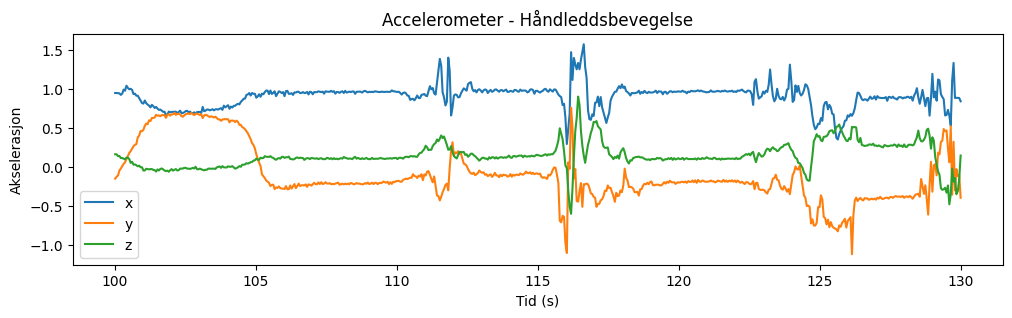

In [ ]:
# Vi plotter accelerometeret (altså fysisk bevegelse)
plt.figure(figsize=(12,3))
plt.plot(acc_win["t"], acc_win["x"], label="x")
plt.plot(acc_win["t"], acc_win["y"], label="y")
plt.plot(acc_win["t"], acc_win["z"], label="z")

plt.title("Accelerometer - Håndleddsbevegelse")
plt.xlabel("Tid (s)")
plt.ylabel("Akselerasjon")

plt.legend()
plt.show()

### Activity

For å lese grafen under, så må vi huske på:
1. Stackene vil alltid summeres til 1
2. Fargene "konkurrerer", og forteller sannsynligheten for at den gitte aktiviteten blir gjort på det tidspunktet
3. Er det myke overganger, så er det usikkerhet

Kort oppsummert så forteller denne grafen hvilken aktivitet systemet tror at personen gjør

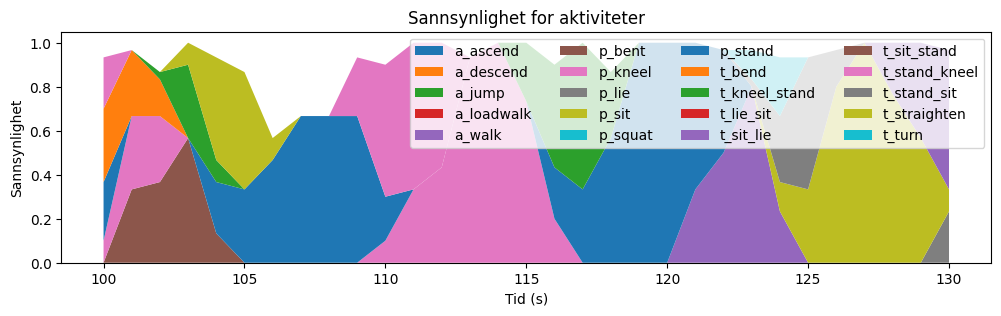

In [ ]:
activity_labels = activity.columns[1:]

plt.figure(figsize=(12,3))
plt.stackplot(
    activity_win["t"],
    activity_win[activity_labels].T
)

plt.legend(activity_labels, ncol=4, loc="upper right")
plt.title("Sannsynlighet for aktiviteter")
plt.xlabel("Tid (s)")
plt.ylabel("Sannsynlighet")

plt.show()

### Usikre aktiviteter

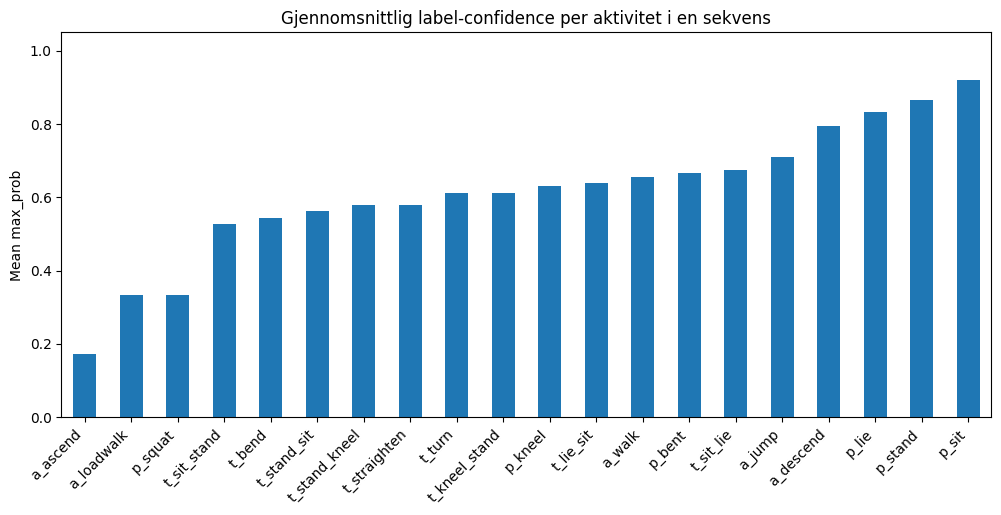

In [ ]:
#gj.snitt confidence per aktivitet
activity_cols = [c for c in activity.columns if c not in ["t", "max_prob"]]
if "max_prob" not in activity.columns:
  activity["max_prob"] = activity.iloc[:, 1:].max(axis=1)
dominant = activity[activity_cols].idxmax(axis=1)

conf_by_class = activity.groupby(dominant)["max_prob"].agg(["mean", "median", "count"]).sort_values("mean")
conf_by_class.head(10)

plt.figure(figsize=(12,5))
conf_by_class["mean"].plot(kind="bar")
plt.title("Gjennomsnittlig label-confidence per aktivitet i en sekvens")
plt.ylabel("Mean max_prob")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.show()


Figuren over viser forskjeller i label-confidence per aktivitet.

sit, stand og lie har høy gj.snitt confidence (>0.85). Disse er altså tydelige og konsistente i settet.

sit_stand, stand_kneel og kneel_stand ligger i mellom rundt (0.55 til 0.70) som gjør det vanskeligere å annotere presist.

ascend, loadwalk og squat har en betydelig lavere confience. Høy usikkerhet i disse klassene

### PIR

For å lese denne grafen, må vi tenke på:
1. Dersom PIR aktiveres så betyr det at det er tilstedeværelse eller bevegelse i et rom
2. Dersom flere rom aktiveres så er det sannsynlig at personen gjør en overgang fra et rom til et annet
3. Dersom det ikke er noen PIR men bevegelse, så er det muligens en sittende aktivitet

Kort oppsummert så gir grafen et grovt svar på "Hvor er personen?"

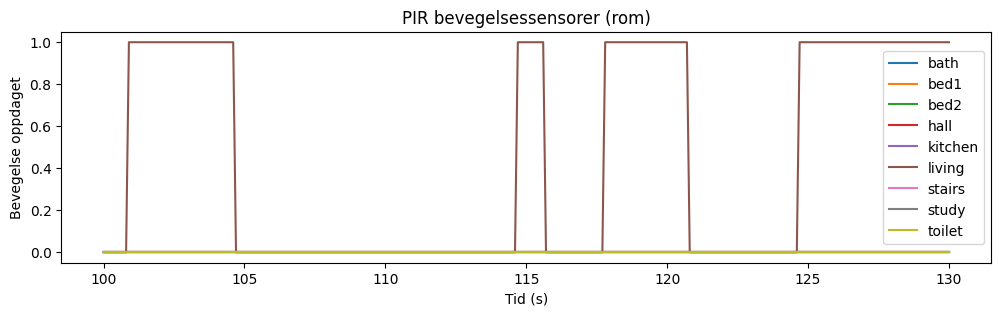

In [ ]:
plt.figure(figsize=(12,3))

for col in pir_win.columns:
  if col != "t":
    plt.plot(pir_win["t"], pir_win[col], label=col)

plt.title("PIR bevegelsessensorer (rom)")
plt.xlabel("Tid (s)")
plt.ylabel("Bevegelse oppdaget")

plt.legend()
plt.show()

Et eksempel på hvordan vi kan bruke grafene over for å trene intuitisjonen vår av datasettet:
Rundt tid = 115, ser vi at det er bevegelse i "living room" på PIR-sensorene. Vi ser på accelerometer at det er plutselige spikes, som tyder på at personen gjør en overgang fra en posisjon til en annen.
Vi ser på activity at det er høy sannsynlighet for at personen gjør p_kneel i tiden rett før t = 115, og høy sannsynlighet for at personen gjør t_kneel_stand rundt t = 115.

Vi kan derfor lese av grafene at det er høy sannsynlighet for at personen beveger seg fra knelende stilling til stående stilling i living room rundt t = 115.

## Forståelse av datastrukturen

I denne seksjonen skriver vi litt enkel kode for å få en god oversikt over strukturen på datasettet, slik at det blir lettere å navigere i løpet av prosjektet

###Sjekkliste #1:


Kodelinjen under vil fortelle oss hvilke sensorer som eksisterer (og mangler) for en gitt sekvens, og om RGB-D (kamera-data) eksisterer eller ei

In [ ]:
# For en gitt sekvens, kan det være nyttig å bruke:
os.listdir(seq_path)

['location.csv',
 'per_ann_location_2.csv',
 'per_ann_location_1.csv',
 'rgbd_kitchen.csv',
 'per_ann_activity_0.csv',
 'pir.csv',
 'per_ann_activity_1.csv',
 'per_ann_location_0.csv',
 'acceleration.csv',
 'per_ann_activity_2.csv',
 'activity.csv',
 'rgbd_hall.csv',
 'rgbd_living.csv',
 'rssi.csv',
 'meta.json']

### Sjekkliste #2:


Kodelinjene under vil fortelle oss om alle sensorene følger samme tidsintervall. Dette er nyttig å være obs på når vi skal aligne features

In [ ]:
def time_span(df):
  return df["t"].min(), df["t"].max()

time_span(activity), time_span(acc), time_span(pir)

((0.0, 1823.0), (0.017856, 1823.917), (0.0, 1823.9))

###Sjekkliste #3:


Kodelinjene under vil vise oss NaN-verdier i datasettet. Vi ser at det finnes ingen NaN-verdier, og dette gir oss verdifull informasjon:
Siden sphere-challenge-complete-2022 er et behandlet datasett for en challenge, vil ikke manglende informasjon gi en NaN-verdi, men snarere "0".

In [ ]:
acc.isna().mean()
pir.isna().mean()
activity.isna().mean()

,0
t,0.0
a_ascend,0.0
a_descend,0.0
a_jump,0.0
a_loadwalk,0.0
a_walk,0.0
p_bent,0.0
p_kneel,0.0
p_lie,0.0
p_sit,0.0


### PIR

Vi kan derfor bruke noen alternativer for å sjekke for manglende informasjon:
F.eks. en analyse av inaktivitet: hvor ofte aktiveres sensoren?
Verdier nærme 0: sensoren aktiveres sjeldent i rommet i denne sekvensen.

Verdier lik 0: Rommet blir aldri brukt i denne sekvensen.

In [ ]:
pir.drop(columns=["t"]).mean().sort_values()

,0
hall,0.000000
bed1,0.004550
study,0.011623
bath,0.019901
toilet,0.023575
stairs,0.025274
bed2,0.050822
kitchen,0.074945
living,0.089803


In [ ]:
def estimate_sampling_rate(df, t_col="t", n=5000):
    t = df[t_col].values
    dt = np.diff(t[:min(len(t), n)])
    dt = dt[dt > 0]
    return 1/np.median(dt), np.median(dt)

print("Sampling-estimat for valgt sekvens:\n")

for name, df in [("activity", activity), ("acc", acc), ("pir", pir)]:
    fs, med_dt = estimate_sampling_rate(df)
    print(f"{name}: ca {fs:.2f} Hz  |  median dt = {med_dt:.4f} sek")


Sampling-estimat for valgt sekvens:

activity: ca 1.00 Hz  |  median dt = 1.0000 sek
acc: ca 19.98 Hz  |  median dt = 0.0500 sek
pir: ca 10.00 Hz  |  median dt = 0.1000 sek


### Activity

**max_prob** forteller oss for hvert sekund *t*, hvor sikkert er datasettet på enhver gitt aktivitet?

Det er altså ikke en label for en aktivitet, men en måling på **confidence**.

Se på det som:

max_prob ≈ 1.0 -> Veldig sikkert

max_prob ≈ 0.3 - 0.5 -> Ambiguøst

max_prob ≈ 0.0 -> Ingen aktivitetshypotese

Snittverdien i seg selv er nok ikke så nyttig, men kan bli interessant når vi ser det i kontekst av medianen, les tekstfelt under tabellen.

In [ ]:
activity["max_prob"] = activity.iloc[:, 1:].max(axis=1)
activity["max_prob"].describe()


,max_prob
count,1824.000000
mean,0.768074
std,0.261771
min,0.000000
25%,0.633333
50%,0.833333
75%,1.000000
max,1.000000


For å tolke statistikken over, ser vi på noen viktige verdier:

**count**: antall sekunder med aktivitetsannoteringer

**mean**: Det at snittverdien er lavere enn medianen, forteller oss at det er mange øyeblikk med høy sikkerhet til aktiviteten, men at enkelte *veldig* ambiguøse øyeblikk trekker ned snittverdien. Med andre ord: usikkerhet er sjeldent, men eksisterer i datasettet

**50%**: Samme som **median**, og forteller oss i denne tabellen at i mer enn 50% av tidslinjen så er datasettet minst 83% sikkert på hva personen gjør

**25%**: Betyr at i 25% av tilfellene, er sikkerheten under 63%. Dette forteller oss at modeller kommer til å slite mer her, og SHAP-forklaringer kan inneholde mer støy

**75%**: Viser at for 75% av alle sekundene så er max_prob mindre eller lik 1.0. Ettersom sannsynligheter ikke kan overstige 1.0, forteller dette oss at minst 25% av alle sekunder har max_prob = 1.0. Altså vil det i minst 25% av sekundene være en aktivitet som har max_prob = 1.0.



Vi bruker to grafer for å visualisere

Første graf:

Viser oss lange platå nær verdi max_prob = 1, og noen dupper. Disse duppene er overganger som å reise seg, sette seg ned og bevege seg mellom rom.

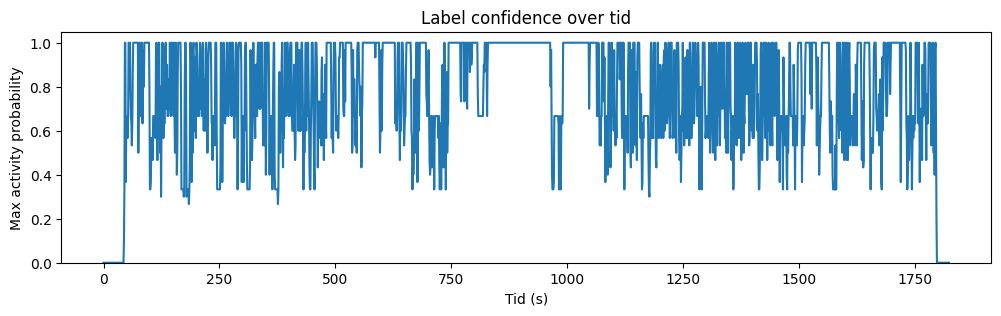

In [ ]:
plt.figure(figsize=(12,3))
plt.plot(activity["t"], activity["max_prob"])
plt.title("Label confidence over tid")
plt.xlabel("Tid (s)")
plt.ylabel("Max activity probability")
plt.ylim(0,1.05)
plt.show()


Den andre grafen viser oss fordelingen: Dette gir oss et tydelig bilde av prevalensen av ambigiuitet

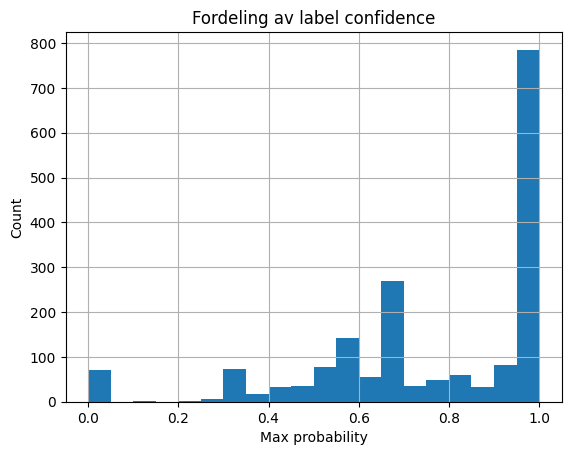

In [ ]:
activity["max_prob"].hist(bins=20)
plt.title("Fordeling av label confidence")
plt.xlabel("Max probability")
plt.ylabel("Count")
plt.show()


#### Hvorfor er dette nyttig å vite?

max_prob lar oss separere enkle vs vanskelige målinger.
Med denne informasjonen kan vi sammenligne sensormønstre, sammenligne modellytelser, og sammenligne SHAP-forklaringer. **Dette er utrolig nyttig når vi skal analysere robusthet**

max_prob forteller oss også når labels er troverdige, når datasettet selv er usikkert, og **hvor forklarbarhet er viktigst**

###Accelerometer

Vi definerer energi for å stille spørsmålet "Hvor mye beveger accelerometeret seg, uavhengig av retning?"

Vi ser at verdien alltid er lik eller større null, verdien er stor når det er bevegelse, og liten når sensoren er i lite bevegelse

In [ ]:
acc["energy"] = acc[["x","y","z"]].pow(2).sum(axis=1)

acc["energy"].describe()


,energy
count,35711.000000
mean,1.031052
std,0.384513
min,0.007696
25%,0.930434
50%,0.986604
75%,1.070212
max,23.062688


For å tolke statistikken over, ser vi på noen viktige verdier:

**count**: antall målinger fra accelerometeret i denne sekvensen
Vi ser at denne verdien bekrefter at det tas hyppige målinger fra sensoren

**mean**: Gjennomsnitt. Det at gjennomsnittet er litt over 1 betyr at det er bevegelse av og til

**50%**: Dette er det samme som median. Det at median er nesten lik 1 betyr at håndleddet på brukeren ofte er i ro.

**max**: Denne er nesten lik 23, noe som viser oss at det er rundt disse verdiene at vi måler bevegelse: i korte skarpe spikes som ved overganger, gestikuleringer og gange.


Så med dette i tankene, hvordan skal vi måle "bevegelse" skikkelig?
Istedenfor å lete etter nullverdier, så ser vi etter avvikelse fra baseline.

Vi starter derfor med å estimere baseline, da baseline vil approksimere "sensor ikke i bevegelse", altså et stilleværende håndledd med kun tyngdekraften som påvirker sensor.

In [ ]:
baseline = acc["energy"].median()
baseline


0.9866039999999999

For å computere mengden bevegelse, setter vi motion til å være lik lesninger av energi minus baseline:

In [ ]:
acc["motion"] = acc["energy"] - baseline


Kodelinjen under svarer på "Hvilken andel av tiden er det vesentlig bevegelse på håndleddet?". Dette er nyttig informasjon når vi skal oppdage bevegelse

In [ ]:
(acc["motion"] > 0.5).mean()


np.float64(0.041919856626809665)

Om vi bruker denne vinklingen på dataen, så kan vi lage grafen under for å visuelt demonstrere accelerometer aktivitet.
Vi ser en striplet linje rundt e = 1 som utgjør baseline. Spikes som stiger over denne baselinen er øyeblikk der håndleddet er i aktiv bevegelse

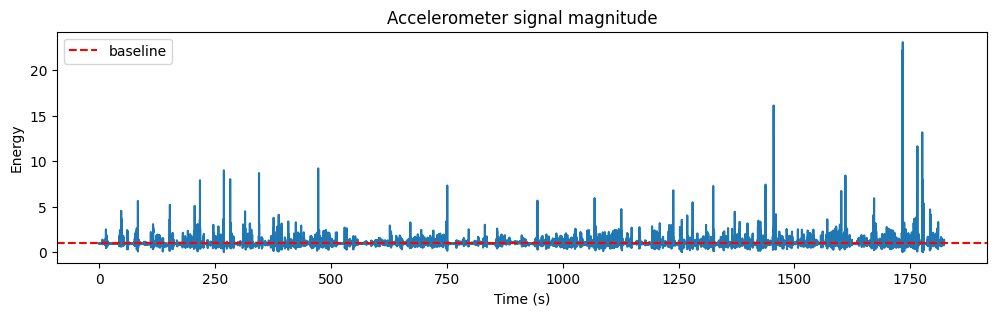

In [ ]:
plt.figure(figsize=(12,3))
plt.plot(acc["t"], acc["energy"])
plt.axhline(baseline, color="red", linestyle="--", label="baseline")
plt.title("Accelerometer signal magnitude")
plt.xlabel("Time (s)")
plt.ylabel("Energy")
plt.legend()
plt.show()


### Big picture på sjekkliste #3

Vi må altså ikke tenke på om det mangler verdier i datasettet, men snarere se hvordan dataen oppfører seg. Vi leter altså ikke etter nullverdier, men informative avvik i målingene.

Det "store bildet" er at selv om dataen ser fin ut på overflaten, er det mye usikkerhet i etikettene. Her har jeg regnet ut nøyaktige verdier for hvor pålitelige etikettene i datasettet er. Dette er viktig for å vurdere robustheten til modellene våre senere.

In [ ]:
# Regner ut gjennomsnittlig sikkerhet for alle aktivitet labels
confidence_stats = activity["max_prob"].describe()

# Beregner hvor stor andel av dataen som er usikker (under 0.6)
low_confidence_ratio = (activity["max_prob"] < 0.6).mean() * 100

print(f"Gjennomsnittlig sikkerhet i datasettet: {confidence_stats['mean']:.2f}")
print(f"Andel av data med lav sikkerhet (under 60%): {low_confidence_ratio:.1f}%")

Gjennomsnittlig sikkerhet i datasettet: 0.77
Andel av data med lav sikkerhet (under 60%): 21.1%


##Samplingfrekvens


Aktivitet, akselerometer og PIR sensorene har ulik tidsoppløsning, og bør aggregeres før modellering





Aggregering av samplingfrekvens:


In [ ]:
import numpy as np
import pandas as pd
import os


def create_5s_windows(acc, pir, activity, window_size=5):

    # sørg for max_prob én gang
    if "max_prob" not in activity.columns:
        activity = activity.copy()
        activity["max_prob"] = activity.iloc[:, 1:].max(axis=1)

    activity_cols = [c for c in activity.columns if c not in ["t", "max_prob"]]

    features = []
    max_time = int(min(acc["t"].max(), pir["t"].max(), activity["t"].max()))

    for start in range(0, max_time, window_size):
        end = start + window_size

        acc_win = acc[(acc["t"] >= start) & (acc["t"] < end)]
        pir_win = pir[(pir["t"] >= start) & (pir["t"] < end)]
        act_win = activity[(activity["t"] >= start) & (activity["t"] < end)]

        if len(acc_win) == 0 or len(act_win) == 0:
            continue

        row = {}

        # ---- ACC ----
        for axis in ["x", "y", "z"]:
            row[f"mean_{axis}"] = acc_win[axis].mean()
            row[f"std_{axis}"]  = acc_win[axis].std()
            row[f"min_{axis}"]  = acc_win[axis].min()
            row[f"max_{axis}"]  = acc_win[axis].max()

        energy = (acc_win["x"]**2 + acc_win["y"]**2 + acc_win["z"]**2)
        row["mean_energy"] = energy.mean()
        row["std_energy"]  = energy.std()
        row["max_energy"]  = energy.max()

        baseline = energy.median()
        row["motion_ratio"] = (energy > baseline + 0.5).mean()

        # ---- PIR ----
        pir_cols = [c for c in pir_win.columns if c != "t"]
        if len(pir_cols) == 0:
            continue

        row["total_pir_activity"] = pir_win[pir_cols].sum().sum()
        row["active_rooms_count"] = (pir_win[pir_cols].sum() > 0).sum()

        for col in pir_cols:
            row[f"pir_sum_{col}"] = pir_win[col].sum()
            row[f"pir_mean_{col}"] = pir_win[col].mean()

        # ---- LABEL ----
        row["label"] = act_win[activity_cols].mean().idxmax()
        row["confidence"] = act_win["max_prob"].mean()

        features.append(row)

    return pd.DataFrame(features)


seq_id = train_sequences[0]
seq_path = os.path.join(TRAIN_ROOT, seq_id)

activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))

df_windows = create_5s_windows(acc, pir, activity, window_size=5)

print(df_windows.shape)
df_windows.head()

(365, 38)


,mean_x,std_x,min_x,max_x,mean_y,std_y,min_y,max_y,mean_z,std_z,...,pir_sum_living,pir_mean_living,pir_sum_stairs,pir_mean_stairs,pir_sum_study,pir_mean_study,pir_sum_toilet,pir_mean_toilet,label,confidence
0,0.940820,0.010637,0.896,0.954,-0.273220,0.015466,-0.298,-0.154,0.140800,0.010873,...,0.0,0.0,0.0,0.00,3.0,0.06,0.0,0.0,a_ascend,0.0
1,0.954040,0.031341,0.894,1.120,-0.234788,0.075665,-0.378,0.034,0.056747,0.064405,...,0.0,0.0,0.0,0.00,16.0,0.32,0.0,0.0,a_ascend,0.0
2,0.895640,0.276252,-0.450,1.238,-0.291840,0.207019,-1.188,0.252,0.077820,0.086283,...,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,a_ascend,0.0
3,0.683778,0.574508,-0.832,1.232,-0.298707,0.264269,-1.266,0.216,0.135838,0.163215,...,0.0,0.0,0.0,0.00,41.0,0.82,0.0,0.0,a_ascend,0.0
4,0.958080,0.012575,0.920,0.988,-0.218040,0.028029,-0.314,-0.130,0.081340,0.019988,...,0.0,0.0,23.0,0.46,50.0,1.00,0.0,0.0,a_ascend,0.0


## Klassefordeling: Balanse i aktivitetsdata

For å trene en god modell må vi vite om datasettet er balansert. Her ser vi hvilke aktiviteter som dominerer i sekvensen, noe som er avgjørende for å vurdere nøyaktighet accuracy og F1-score senere. Stillestående / opphold kan dominere, mens inn- og utgang og "sjeldnere" aktiviteter for langt flere eksempler, dersom datasettet er ubalansert kan accuracy blir misvisende, vi ønsker å bruke weighted-F1 eller Macro-F1 i evalueringen.

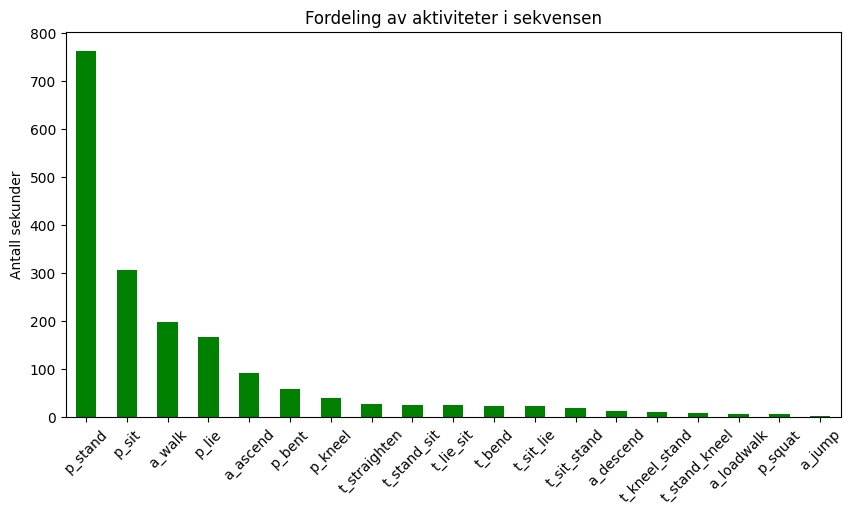

In [ ]:
# Mest sannsynlige aktiviteten for hver tidsenhet
activity_cols = activity.columns[1:-1]
dominant_act = activity[activity_cols].idxmax(axis=1)

# Visuell oversikt
plt.figure(figsize=(10, 5))
dominant_act.value_counts().plot(kind='bar', color='green')
plt.title("Fordeling av aktiviteter i sekvensen")
plt.ylabel("Antall sekunder")
plt.xticks(rotation=45)
plt.show()

**Alle sekvenser**

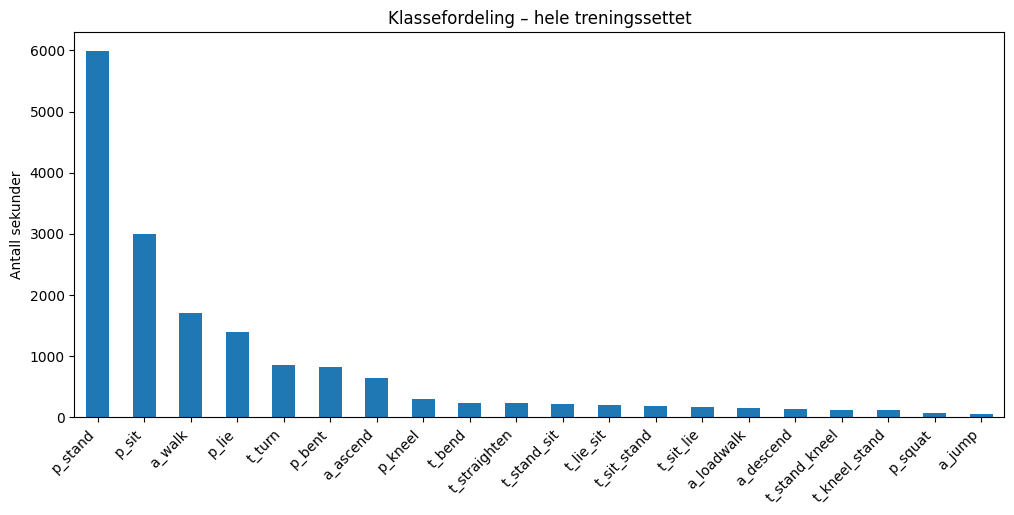

In [ ]:
from collections import Counter

def dominant_activity_counts(root_dir):
    counts = Counter()
    seq_ids = sorted(os.listdir(root_dir))

    for seq_id in seq_ids:
        seq_path = os.path.join(root_dir, seq_id)
        activity_path = os.path.join(seq_path, "activity.csv")

        if not os.path.exists(activity_path):
            continue

        activity = pd.read_csv(activity_path)
        activity_cols = [c for c in activity.columns if c != "t"]
        dominant = activity[activity_cols].idxmax(axis=1)
        counts.update(dominant.value_counts().to_dict())

    return pd.Series(counts).sort_values(ascending=False)

train_class_dist = dominant_activity_counts(TRAIN_ROOT)

plt.figure(figsize=(12,5))
train_class_dist.plot(kind="bar")
plt.title("Klassefordeling – hele treningssettet")
plt.ylabel("Antall sekunder")
plt.xticks(rotation=45, ha="right")
plt.show()


##Sammenheng mellom fysisk bevegelse og system-usikkerhet

Vi undersøker sammenhengen mellom fysisk bevegelse (accelerometer) og label-usikkerhet (max_prob). Tanken er at overganger og/eller raske bevegelser ofte er vanskeliger å klassifisere, og dermed gir lavere confidence. I grafen under ser vi at høy aktivitet ofte gir et fall i max_prob. noe som tyder på at usikkerhet i datasettet er høyest knyttet til overgangsfaser.

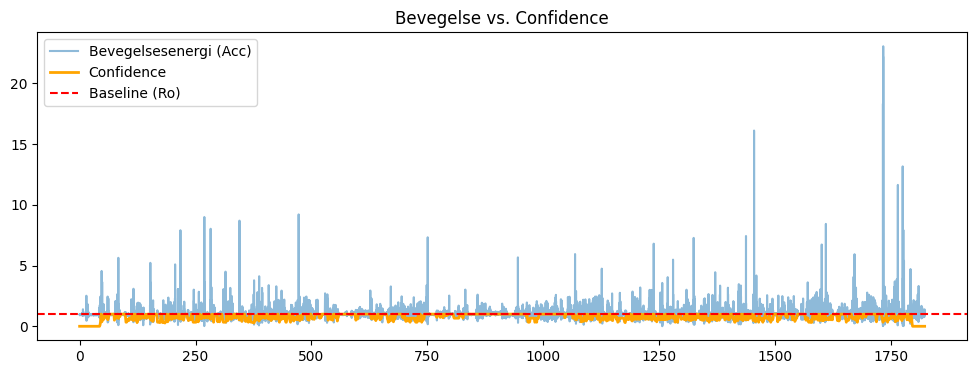

In [ ]:

# Sørg for nødvendige variabler


if "energy" not in acc.columns:
    acc["energy"] = acc[["x", "y", "z"]].pow(2).sum(axis=1)

if "max_prob" not in activity.columns:
    activity["max_prob"] = activity.iloc[:, 1:].max(axis=1)


# Plot


plt.figure(figsize=(12, 4))

plt.plot(
    acc["t"],
    acc["energy"],
    label="Bevegelsesenergi (Acc)",
    alpha=0.5
)

plt.plot(
    activity["t"],
    activity["max_prob"],
    label="Confidence",
    color="orange",
    linewidth=2
)

plt.axhline(
    0.98,
    color="red",
    linestyle="--",
    label="Baseline (Ro)"
)

plt.title("Bevegelse vs. Confidence")
plt.legend()
plt.show()

# Problemformulering

Problemet som modellene skal løse er en klassifiseringsoppgave, hvor input er sensordata aggregert per 1 sekund, og output skal være argmax av sannsynlighet til mest sannsynlig aktivitet.

Vi har følgende alternativer:
"Hard labels": argmax(activity)
"Soft labels": vi bruker sannsynligheten direkte

Vi begynner med hard labels for første baseline

#Evalurering

## Metrics

### Ytelse

For å måle performance så bruker vi Macro-F1 som hovedmetric, med weighted F1 som sekundær metric og accuracy, recall og precision for kontekst.

#### Accuracy

Andelen prediksjoner modellen klassifiserer riktig totalt.

#### Recall

Andel faktiske positive tilfeller modellen klarer å identifisere.

#### Precision

Andel predikerte positive tilfeller som faktisk er riktige.

#### Macro-F1

Gjennomsnittlig F1-score der alle klasser vektes likt. Viktig ved klasseubalanse.

#### Weighted F1

F1-score der klassene vektes etter hvor mange observasjoner de har.

## Robusthet

Vi ser tre måter vi kan evaluere robusthet på:

### Robusthet mot støy

Vi kan legge til såkalt "Gaussian noise", altså en type signalstøy, for å sammenligne hvordan ytelse blir påvirket på tvers av de forskjellige modellene.

### Robusthet mot sensorablasjon

Vi kan simulere at sensordata mangler. F.eks. fjerne PIR-data, RSSI-data eller accelerometer-data, og sammenligne hvordan ytelse blir påvirket på tvers av de forskjellige modellene.

### Robusthet mot random seed

Startverdi for tilfeldige prosesser. Brukes for å teste robusthet eller gjøre eksperimenter reproduserbare.

## Forklarbarhet

Vi evaluerer forklarbarhet gjennom to metoder:

#### SHAP

SHapley Additive exPlanations. XAI-metode som estimerer hvor mye hver variabel bidrar til en prediksjon.

#### Feature / Permutation importance

Metode for å måle variabelbetydning ved å stokke om én variabel og se hvor mye modellens ytelse faller.

# Baseline modeller


Vi starter med å trene en random forest modell på dataen.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from collections import OrderedDict
from sklearn.base import clone


In [ ]:
# Henter ut features per sekvens
def build_sequence_dataframe(seq_path):
  # Laster inn én SPHERE sekvens og returnerer
  # en feature dataframe som har fått hard labels

  # Laster inn kjernefilene
  activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
  acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
  pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))
  rssi = pd.read_csv(os.path.join(seq_path, "rssi.csv"))

  activity["t"] = activity["t"].astype(int)
  acc["t_sec"] = acc["t"].astype(int)
  pir["t"] = pir["t"].astype(int)
  rssi["t"] = rssi["t"].astype(int)

  # Aggreger accelerometer til 1 sekund


  acc_agg = (
      acc.groupby("t_sec")[["x", "y", "z"]]
      .agg(["mean", "std"])
  )

  acc_agg.columns = [f"{a}_{b}" for a, b in acc_agg.columns]
  acc_agg = acc_agg.reset_index()

  # PIR er allerede 1 Hz
  pir_agg = pir.copy()
  pir_agg = pir_agg.rename(columns={"t": "t_sec"})

  # RSSI er allerede 1 Hz
  rssi_agg = rssi.copy()
  rssi_agg = rssi_agg.rename(columns={"t": "t_sec"})

  # Merge features til sensorene
  df = acc_agg.merge(pir_agg, on="t_sec", how="inner")
  df = df.merge(rssi_agg, on="t_sec", how="inner")

  # Merge etiketter
  activity = activity.rename(columns={"t": "t_sec"})
  df = df.merge(activity, on="t_sec", how="inner")

  # Harde etiketter via argmax
  activity_cols = activity.columns[1:]
  df["label"] = df[activity_cols].idxmax(axis=1)

  # Endelig feature matrix
  X = df.drop(columns=list(activity_cols) + ["label", "t_sec"])
  y = df["label"]

  return X, y

In [ ]:
# Bygger fulle train/test splitter
def build_dataset(root_path):
  X_list, y_list = [], []

  sequences = sorted(os.listdir(root_path))

  for seq in sequences:
    seq_path = os.path.join(root_path, seq)

    if not os.path.isdir(seq_path):
      continue

    try:
      X_seq, y_seq = build_sequence_dataframe(seq_path)
      X_list.append(X_seq)
      y_list.append(y_seq)
    except Exception as e:
      print(f"Skipping {seq} due to error:", e)

  X = pd.concat(X_list, ignore_index=True)
  y = pd.concat(y_list, ignore_index=True)

  return X, y

In [ ]:
# Laster datasett fra drive dersom lagret
# Bygger dataset dersom et lagret datasett ikke blir funnet
import joblib

cache_files = [
    f"{DATASET_DIR}/X_train.pkl",
    f"{DATASET_DIR}/y_train.pkl",
    f"{DATASET_DIR}/X_test.pkl",
    f"{DATASET_DIR}/y_test.pkl"
]

# Dersom datasettet eksisterer i Google Drive
if all(os.path.exists(f) for f in cache_files):

  print("Laster cached datasett")

  X_train = joblib.load(f"{DATASET_DIR}/X_train.pkl")
  y_train = joblib.load(f"{DATASET_DIR}/y_train.pkl")

  X_test = joblib.load(f"{DATASET_DIR}/X_test.pkl")
  y_test = joblib.load(f"{DATASET_DIR}/y_test.pkl")

# Dersom datasettet ikke eksisterer i Google Drive
else:

  print("Bygger datasett fra filer")

  print("Bygger treningssett")
  X_train, y_train = build_dataset(TRAIN_ROOT)

  print("Bygger testsett")
  X_test, y_test = build_dataset(TEST_ROOT)

  # Lagrer datasettene til Google Drive
  joblib.dump(X_train, f"{DATASET_DIR}/X_train.pkl")
  joblib.dump(y_train, f"{DATASET_DIR}/y_train.pkl")
  joblib.dump(X_test, f"{DATASET_DIR}/X_test.pkl")
  joblib.dump(y_test, f"{DATASET_DIR}/y_test.pkl")


Laster cached datasett


Feature matrise


In [ ]:
n_train = len(X_train)
n_test = len(X_test)

total = n_train + n_test

print("Train samples:", n_train)
print("Test samples :", n_test)

print("Train ratio:", round(n_train / total * 100, 2), "%")
print("Test ratio :", round(n_test / total * 100, 2), "%")

Train samples: 3011880
Test samples : 3175500
Train ratio: 48.68 %
Test ratio : 51.32 %


In [ ]:
print(X_train.shape)
print(X_train.columns)
X_train.head()

(3011880, 19)
Index(['x_mean', 'x_std', 'y_mean', 'y_std', 'z_mean', 'z_std', 'bath', 'bed1',
       'bed2', 'hall', 'kitchen_x', 'living_x', 'stairs_x', 'study_x',
       'toilet', 'kitchen_y', 'living_y', 'study_y', 'stairs_y'],
      dtype='object')


,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
0,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
1,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
2,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
3,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
4,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-90.0,-89.0,NaN,-79.0


In [ ]:
print("Shape på feature-matrisen:")
print(X_train.shape)

print("\nKolonner i feature-matrisen:")
print(X_train.columns.tolist())

print("\nFørste 5 rader:")
display(X_train.head())

print("\nRader med PIR-aktivitet:")
display(
    X_train[
        (X_train[["bath", "bed1", "bed2", "hall", "kitchen_x", "living_x", "stairs_x", "study_x", "toilet"]] > 0).any(axis=1)
    ].head()
)

print("\nRader med høy bevegelse i accelerometer:")
display(
    X_train[X_train["x_std"] > 0.1].head()
)

print("\nRader sortert etter høyest x_std:")
display(
    X_train.sort_values("x_std", ascending=False).head()
)

print("\nEksempel: walking-rader")
display(
    X_train[y_train == "a_walk"].head()
)

print("\nEksempel: kitchen-aktivitet + bevegelse")
display(
    X_train[(X_train["kitchen_x"] > 0) & (X_train["x_std"] > 0.05)].head()
)

Shape på feature-matrisen:
(3011880, 19)

Kolonner i feature-matrisen:
['x_mean', 'x_std', 'y_mean', 'y_std', 'z_mean', 'z_std', 'bath', 'bed1', 'bed2', 'hall', 'kitchen_x', 'living_x', 'stairs_x', 'study_x', 'toilet', 'kitchen_y', 'living_y', 'study_y', 'stairs_y']

Første 5 rader:


,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
0,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
1,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
2,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
3,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-93.0,-95.0,NaN,-79.0
4,0.9392,0.012556,-0.2797,0.007205,0.1461,0.008271,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-90.0,-89.0,NaN,-79.0



Rader med PIR-aktivitet:


,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
940,0.9424,0.011727,-0.2603,0.026352,0.1295,0.011143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-87.0,-87.0,NaN,-81.0
941,0.9424,0.011727,-0.2603,0.026352,0.1295,0.011143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-87.0,-87.0,NaN,-81.0
942,0.9424,0.011727,-0.2603,0.026352,0.1295,0.011143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-87.0,-87.0,NaN,-81.0
943,0.9424,0.011727,-0.2603,0.026352,0.1295,0.011143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-87.0,-87.0,NaN,-81.0
944,0.9424,0.011727,-0.2603,0.026352,0.1295,0.011143,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-85.0,-87.0,NaN,-84.0



Rader med høy bevegelse i accelerometer:


...

,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
2103586,0.822154,1.345973,-0.131538,0.145105,0.403538,0.631768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,-102.0,NaN
2103590,0.822154,1.345973,-0.131538,0.145105,0.403538,0.631768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,-96.0,NaN
2103572,0.822154,1.345973,-0.131538,0.145105,0.403538,0.631768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,-102.0,NaN
2103611,0.822154,1.345973,-0.131538,0.145105,0.403538,0.631768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,-102.0,NaN
2103596,0.822154,1.345973,-0.131538,0.145105,0.403538,0.631768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,-102.0,NaN



Eksempel: walking-rader


,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
8730,1.0001,0.183444,-0.1258,0.12286,0.1126,0.078991,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-82.0,-84.0,NaN,-86.0
8731,1.0001,0.183444,-0.1258,0.12286,0.1126,0.078991,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-84.0,-95.0,NaN,-87.0
8732,1.0001,0.183444,-0.1258,0.12286,0.1126,0.078991,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-84.0,-95.0,NaN,-87.0
8733,1.0001,0.183444,-0.1258,0.12286,0.1126,0.078991,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-84.0,-95.0,NaN,-87.0
8734,1.0001,0.183444,-0.1258,0.12286,0.1126,0.078991,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-84.0,-95.0,NaN,-87.0



Eksempel: kitchen-aktivitet + bevegelse


,x_mean,x_std,y_mean,y_std,z_mean,z_std,bath,bed1,bed2,hall,kitchen_x,living_x,stairs_x,study_x,toilet,kitchen_y,living_y,study_y,stairs_y
85760,0.9504,0.052108,-0.2393,0.073465,0.1542,0.055743,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-78.0,NaN,NaN,-88.0
85761,0.9504,0.052108,-0.2393,0.073465,0.1542,0.055743,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-78.0,NaN,NaN,-88.0
85762,0.9504,0.052108,-0.2393,0.073465,0.1542,0.055743,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-78.0,NaN,NaN,-88.0
85763,0.9504,0.052108,-0.2393,0.073465,0.1542,0.055743,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-78.0,NaN,NaN,-88.0
85764,0.9504,0.052108,-0.2393,0.073465,0.1542,0.055743,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-90.0,NaN,NaN,-90.0


In [ ]:
# Preprocessing block for å imputere NaN
print("Sjekker for NaNs i datasett...")

print("NaNs i X_train:", X_train.isna().sum().sum())
print("NaNs i X_test:", X_test.isna().sum().sum())

# Lager en imputer
imputer = SimpleImputer(strategy="median")

# Fit på treningsdata
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

# Transformer testdata
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("NaNs etter imputering:", X_train.isna().sum().sum())

Sjekker for NaNs i datasett...
NaNs i X_train: 8017610
NaNs i X_test: 8260190
NaNs etter imputering: 0


In [ ]:
# Subsampler treningsdata for å redusere treningstiden
SUBSAMPLE_SIZE = 1250000  # antallet samples som modellene skal trenes på
sample_path = f"{DATASET_DIR}/train_sample_v2.pkl"

if os.path.exists(sample_path):

  print("Laster sampled treningssett")
  X_train_sub, y_train_sub = joblib.load(sample_path)

else:

  print("Lager et sampled treningssett")
  X_train_sub, _, y_train_sub, _ = train_test_split(
        X_train,
        y_train,
        train_size=SUBSAMPLE_SIZE,
        stratify=y_train,
        random_state=42
    )

  joblib.dump((X_train_sub, y_train_sub), sample_path)




print("Størrelse på originalt treningssett:", len(X_train))
print("Størrelse på subsampled treningssett:", len(X_train_sub))

Laster sampled treningssett
Størrelse på originalt treningssett: 3011880
Størrelse på subsampled treningssett: 1250000


In [ ]:
# Definerer baseline modeller
models = OrderedDict({
    "Dummy": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=1200,
                C=3.0,
                solver="saga",
                class_weight="balanced",
                n_jobs=-1,
                random_state=42
            ))
        ]),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt",
            min_samples_leaf=1,
            min_samples_split=5,
            max_depth=None,
            bootstrap=True,
            class_weight="balanced"
        ),

    "Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=700,
            learning_rate=0.03,
            max_leaf_nodes=127,
            min_samples_leaf=20,
            l2_regularization=2.0,
            random_state=42
        ),

    "Linear SVM":
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearSVC(
                C=0.75,
                class_weight="balanced",
                max_iter=8000,
                dual="auto",
                random_state=42
            ))
        ])#,

    #"KNN":
    #    Pipeline([
    #        ("scaler", StandardScaler()),
    #        ("model", KNeighborsClassifier(n_neighbors=5))
    #    ])
})

In [ ]:
# Trener baseline modeller
from sklearn.utils.class_weight import compute_sample_weight
trained_models = {}

for name, model in models.items():

    model_path = f"{MODEL_DIR}/{name}_model.pkl"

    # Dersom det eksisterer trente modeller i Google Drive
    if os.path.exists(model_path):

        print(f"Laster {name} fra Drive...")
        model = joblib.load(model_path)

    # Dersom det ikke eksisterer trente modeller i Google Drive
    else:

        print(f"Trener {name}...")

        if name == "Gradient Boosting":
            from sklearn.utils.class_weight import compute_sample_weight

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train_sub
            )

            model.fit(X_train_sub, y_train_sub, sample_weight=sample_weights)

        else:
            model.fit(X_train_sub, y_train_sub)

        joblib.dump(model, model_path)

    trained_models[name] = model

Laster Dummy fra Drive...
Laster Logistic Regression fra Drive...
Laster Random Forest fra Drive...
Laster Gradient Boosting fra Drive...
Laster Linear SVM fra Drive...


In [ ]:
# Computerer prediksjoner 1 gang og cacher dem
predictions = {}

for name, model in trained_models.items():

    pred_path = f"{PRED_DIR}/{name}_merged_no_filter_temporal_preds.pkl"

    # Dersom det eksisterer lagrede prediksjoner i Google Drive
    if os.path.exists(pred_path):

        print(f"Laster prediksjoner for {name}")
        preds = joblib.load(pred_path)

    # Dersom det ikke eksisterer lagrede prediksjoner i Google Drive
    else:

        print(f"Genererer prediksjoner for {name}")
        preds = model.predict(X_test)

        joblib.dump(preds, pred_path)

    predictions[name] = preds

Laster prediksjoner for Dummy
Laster prediksjoner for Logistic Regression
Laster prediksjoner for Random Forest
Laster prediksjoner for Gradient Boosting
Laster prediksjoner for Linear SVM


## 1D-CNN
En sekvensbasert nevral nettverksmodell som lærer mønstre direkte fra tidsseriedata. I motsetning til klassiske modeller bruker 1D-CNN automatisk mønstergjenkjenning uten manuell feature engineering.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder

# Label encoder for å konvertere klasser til tall
le = LabelEncoder()
y_train_cnn = le.fit_transform(y_train_sub)
y_test_cnn = le.transform(y_test)

n_classes = len(le.classes_)
n_features = X_train_sub.shape[1]

# Reshape for CNN input (samples, features, 1)
X_train_cnn = X_train_sub.values.reshape(-1, n_features, 1)
X_test_cnn = X_test.values.reshape(-1, n_features, 1)

print("Antall klasser:", n_classes)
print("Antall features:", n_features)
print("Train shape:", X_train_cnn.shape)
print("Test shape:", X_test_cnn.shape)

Antall klasser: 20
Antall features: 19
Train shape: (1250000, 19, 1)
Test shape: (3175500, 19, 1)


In [ ]:
def build_cnn(n_features, n_classes):
    model = keras.Sequential([
        layers.Input(shape=(n_features, 1)),

        layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_cnn(n_features, n_classes)
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 19, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 19, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 9, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 9, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,972 (367.08 KB)

 Trainable params: 93,588 (365.58 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

cnn_path = f"{MODEL_DIR}/cnn_model.keras"

if os.path.exists(cnn_path):
    print("Laster CNN fra Drive...")
    cnn_model = keras.models.load_model(cnn_path)

else:
    print("Trener CNN...")

    class_weights = dict(enumerate(
        compute_class_weight(
            class_weight="balanced",
            classes=np.unique(y_train_cnn),
            y=y_train_cnn
        )
    ))

    history = cnn_model.fit(
        X_train_cnn,
        y_train_cnn,
        epochs=20,
        batch_size=256,
        validation_split=0.1,
        class_weight=class_weights,
        callbacks=[
            keras.callbacks.EarlyStopping(
                patience=3,
                restore_best_weights=True
            )
        ]
    )

    cnn_model.save(cnn_path)
    print("CNN lagret til Drive")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train")
    plt.plot(history.history["val_accuracy"], label="Val")
    plt.title("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train")
    plt.plot(history.history["val_loss"], label="Val")
    plt.title("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

Laster CNN fra Drive...


In [ ]:
cnn_pred_path = f"{PRED_DIR}/CNN_preds.pkl"

if os.path.exists(cnn_pred_path):
    print("Laster CNN prediksjoner")
    cnn_preds = joblib.load(cnn_pred_path)
else:
    print("Genererer CNN prediksjoner")
    cnn_probs = cnn_model.predict(X_test_cnn)
    cnn_preds_encoded = np.argmax(cnn_probs, axis=1)
    cnn_preds = le.inverse_transform(cnn_preds_encoded)
    joblib.dump(cnn_preds, cnn_pred_path)

# Legg CNN til i predictions-dicten så den automatisk inkluderes i alle evalueringer
predictions["1D-CNN"] = cnn_preds
trained_models["1D-CNN"] = cnn_model

print("CNN lagt til i predictions og trained_models")
print("Accuracy:", accuracy_score(y_test, cnn_preds))
print("Macro F1:", f1_score(y_test, cnn_preds, average="macro", zero_division=0))

Laster CNN prediksjoner
CNN lagt til i predictions og trained_models
Accuracy: 0.37418422295701464
Macro F1: 0.2391279348287676


In [ ]:
report_path = f"{RESULT_DIR}/classification_reports.pkl"

if os.path.exists(report_path):

    print("Laster cached klassifiseringsrapporter")
    reports = joblib.load(report_path)

else:

    reports = {}

    for name, preds in predictions.items():

        reports[name] = classification_report(
            y_test,
            preds,
            output_dict=True,
            zero_division=0
        )

    joblib.dump(reports, report_path)

print("Klassifiseringsrapporter er klar")

Laster cached klassifiseringsrapporter
Klassifiseringsrapporter er klar


## Big picture på baseline

### Struktur

Vi observerer at det er lettest for RF å klassifisere statiske postures som p_stand, p_sit og p_lie. Dette kan være fordi posture = stabilt accelerometer + PIR-mønstre.

Men den presterer også bra på dynamiske aktiviteter som a_jump og a_ascend. a_jump er nok lettest fordi det er en stor spike i accelerometer, med et tydelig signal. a_walk derimot har en F1 på 0.39, og dette er nok fordi det er overlapp med a_loadwalk og med overgangsaktiviteter.

Vi ser derimot at det slites på overganger (t_*). De fleste F1-scores her ligger mellom 0.02-0.14. Dette er nok fordi de er korte, sjeldne, og modellen vår ser kun 1-sekunder lange øyeblikk.

# Baseline-resultater

## Ytelse

Evaluerer modellene for våre gitte metrics, og setter inn i en ryddig tabell

In [ ]:
perf_path = f"{RESULT_DIR}/performance_df.pkl"

if os.path.exists(perf_path):

    performance_df = joblib.load(perf_path)

else:

    performance_df = pd.DataFrame([
        {
            "Model": name,
            "Accuracy": reports[name]["accuracy"],
            "Macro_F1": reports[name]["macro avg"]["f1-score"],
            "Weighted_F1": reports[name]["weighted avg"]["f1-score"],
            "Macro_Precision": reports[name]["macro avg"]["precision"],
            "Macro_Recall": reports[name]["macro avg"]["recall"]
        }
        for name in reports
    ])

    performance_df = performance_df.sort_values("Macro_F1", ascending=False)

    joblib.dump(performance_df, perf_path)

performance_df

,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
2,Random Forest,0.564659,0.254784,0.509994,0.403190,0.225782
5,1D-CNN,0.374184,0.239128,0.390408,0.233682,0.261546
3,Gradient Boosting,0.566613,0.237936,0.514284,0.361168,0.218078
1,Logistic Regression,0.182886,0.144080,0.176256,0.165987,0.267943
4,Linear SVM,0.223174,0.132954,0.222114,0.158807,0.251857
0,Dummy,0.382100,0.027646,0.211274,0.019105,0.050000


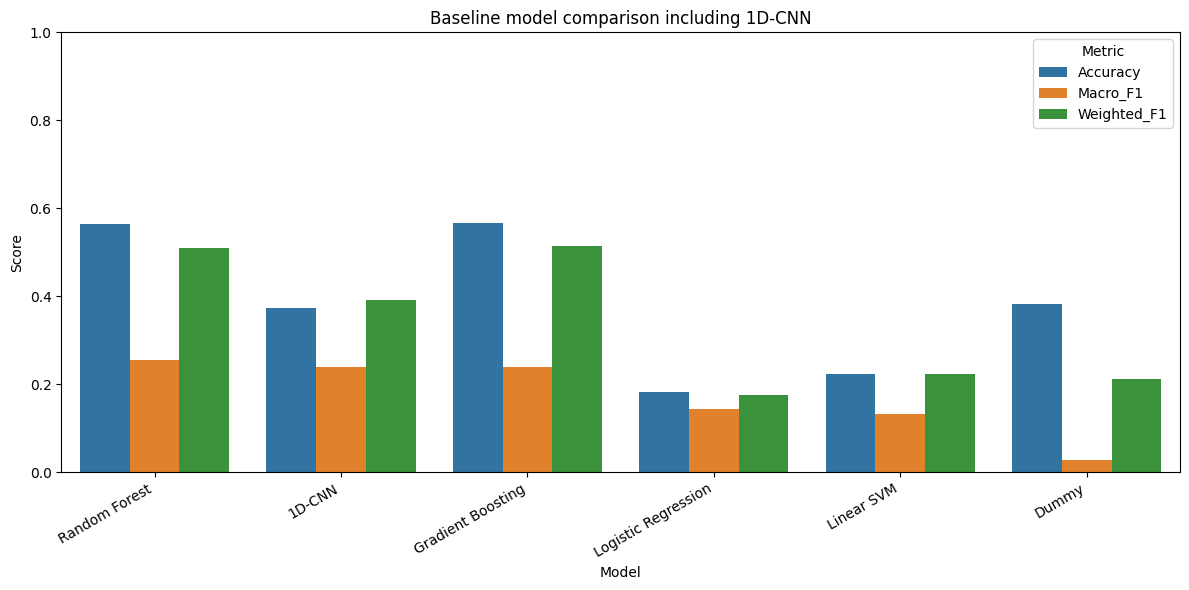

In [ ]:
# ======================================================
# BASELINE MODEL COMPARISON INCLUDING 1D-CNN
# Bruker eksisterende performance_df
# ======================================================

import matplotlib.pyplot as plt
import seaborn as sns

baseline_metrics_long = performance_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro_F1", "Weighted_F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=baseline_metrics_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Baseline model comparison including 1D-CNN")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

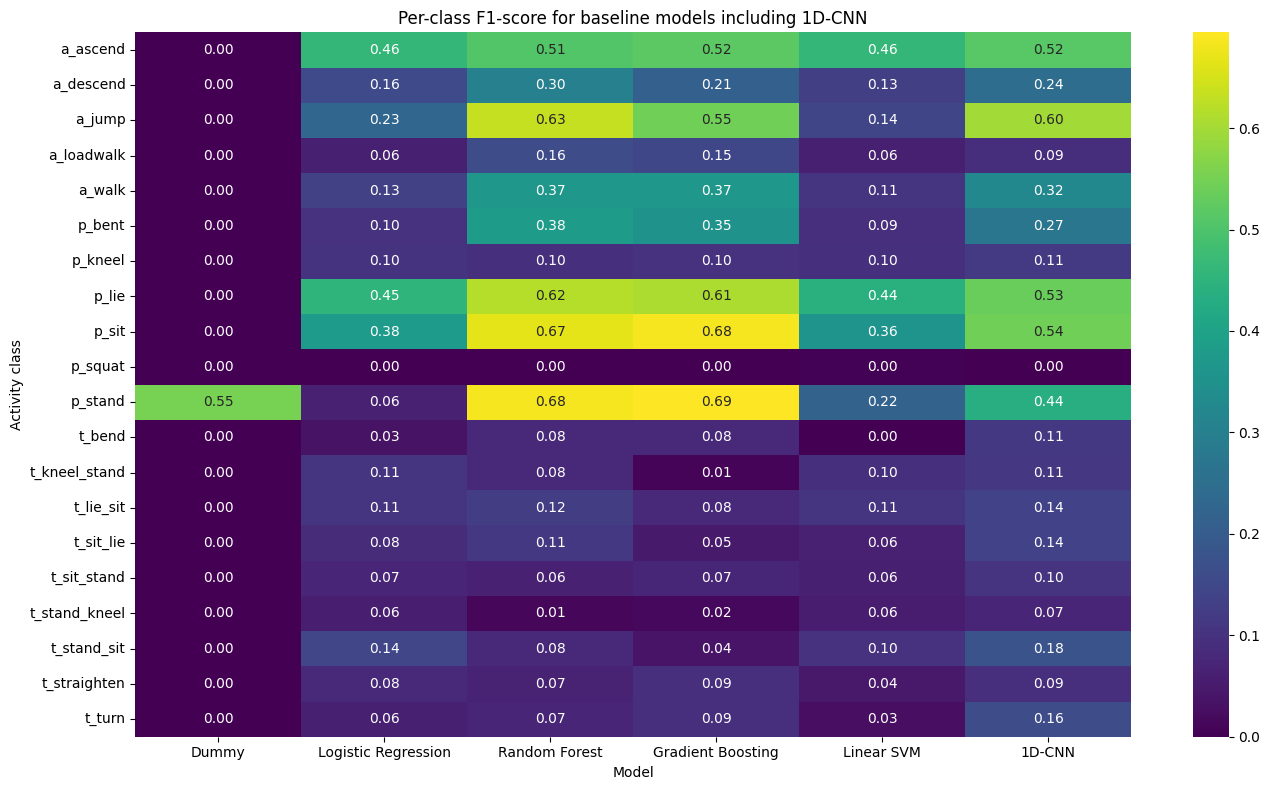

In [ ]:
# ======================================================
# PER-CLASS F1 INCLUDING 1D-CNN
# Bruker eksisterende f1_comparison
# ======================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

f1_path = f"{RESULT_DIR}/per_class_f1.pkl"

if os.path.exists(f1_path):

    f1_comparison = joblib.load(f1_path)

else:

    classes = [
        c for c in reports[list(reports.keys())[0]].keys()
        if c not in ["accuracy", "macro avg", "weighted avg"]
    ]

    f1_comparison = pd.DataFrame({
        model: [reports[model][c]["f1-score"] for c in classes]
        for model in reports
    }, index=classes)

    joblib.dump(f1_comparison, f1_path)



plt.figure(figsize=(14, 8))

sns.heatmap(
    f1_comparison,
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.title("Per-class F1-score for baseline models including 1D-CNN")
plt.ylabel("Activity class")
plt.xlabel("Model")

plt.tight_layout()
plt.show()

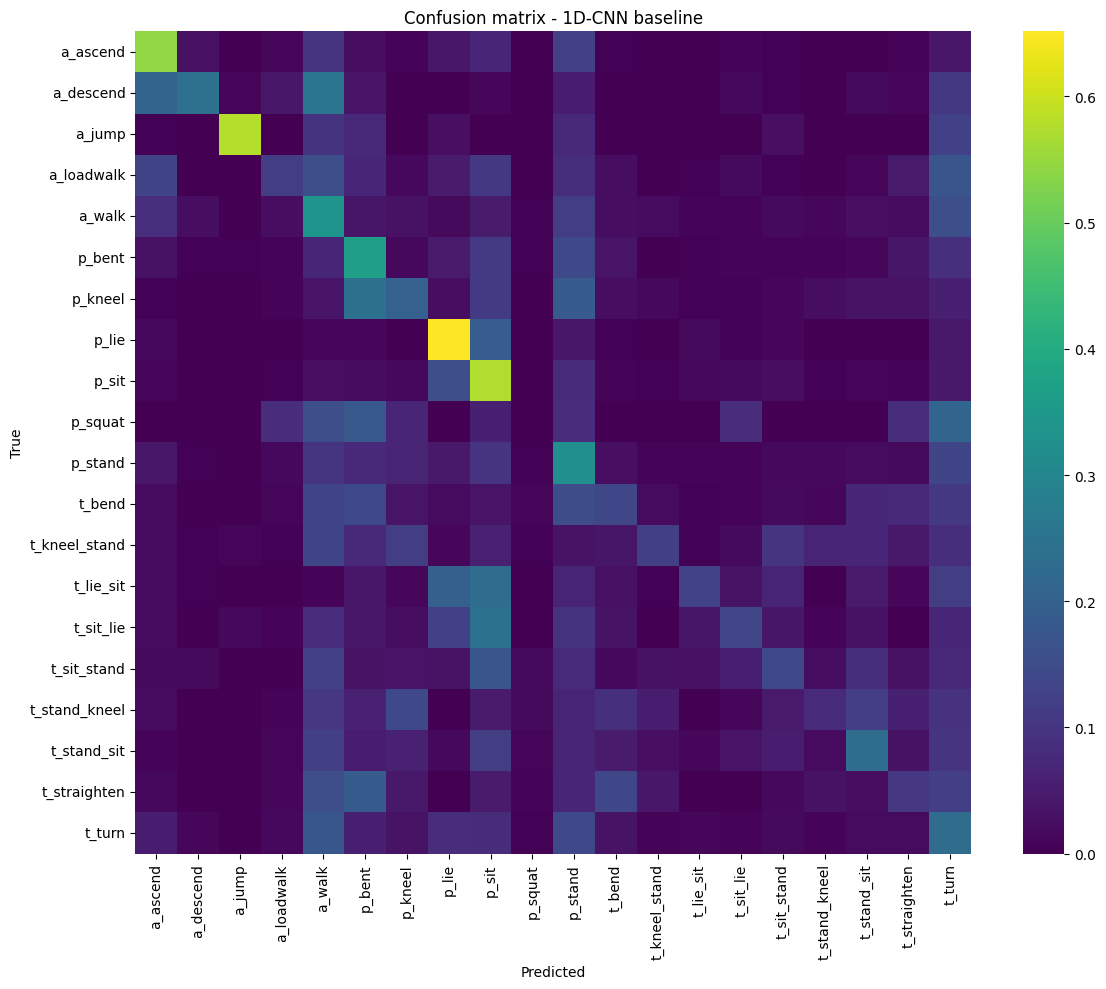

In [ ]:
# ======================================================
# CONFUSION MATRIX - ORIGINAL 1D-CNN
# Bruker y_test og cnn_preds
# ======================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

class_labels = sorted(y_test.unique())

cm_cnn = confusion_matrix(
    y_test,
    cnn_preds,
    labels=class_labels
)

cm_cnn_norm = cm_cnn.astype("float") / cm_cnn.sum(axis=1, keepdims=True)
cm_cnn_norm = np.nan_to_num(cm_cnn_norm)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_cnn_norm,
    cmap="viridis",
    xticklabels=class_labels,
    yticklabels=class_labels,
    annot=False
)

plt.title("Confusion matrix - 1D-CNN baseline")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

###Confusion Matrix
Vi lager en confusion matrix for hver modell:

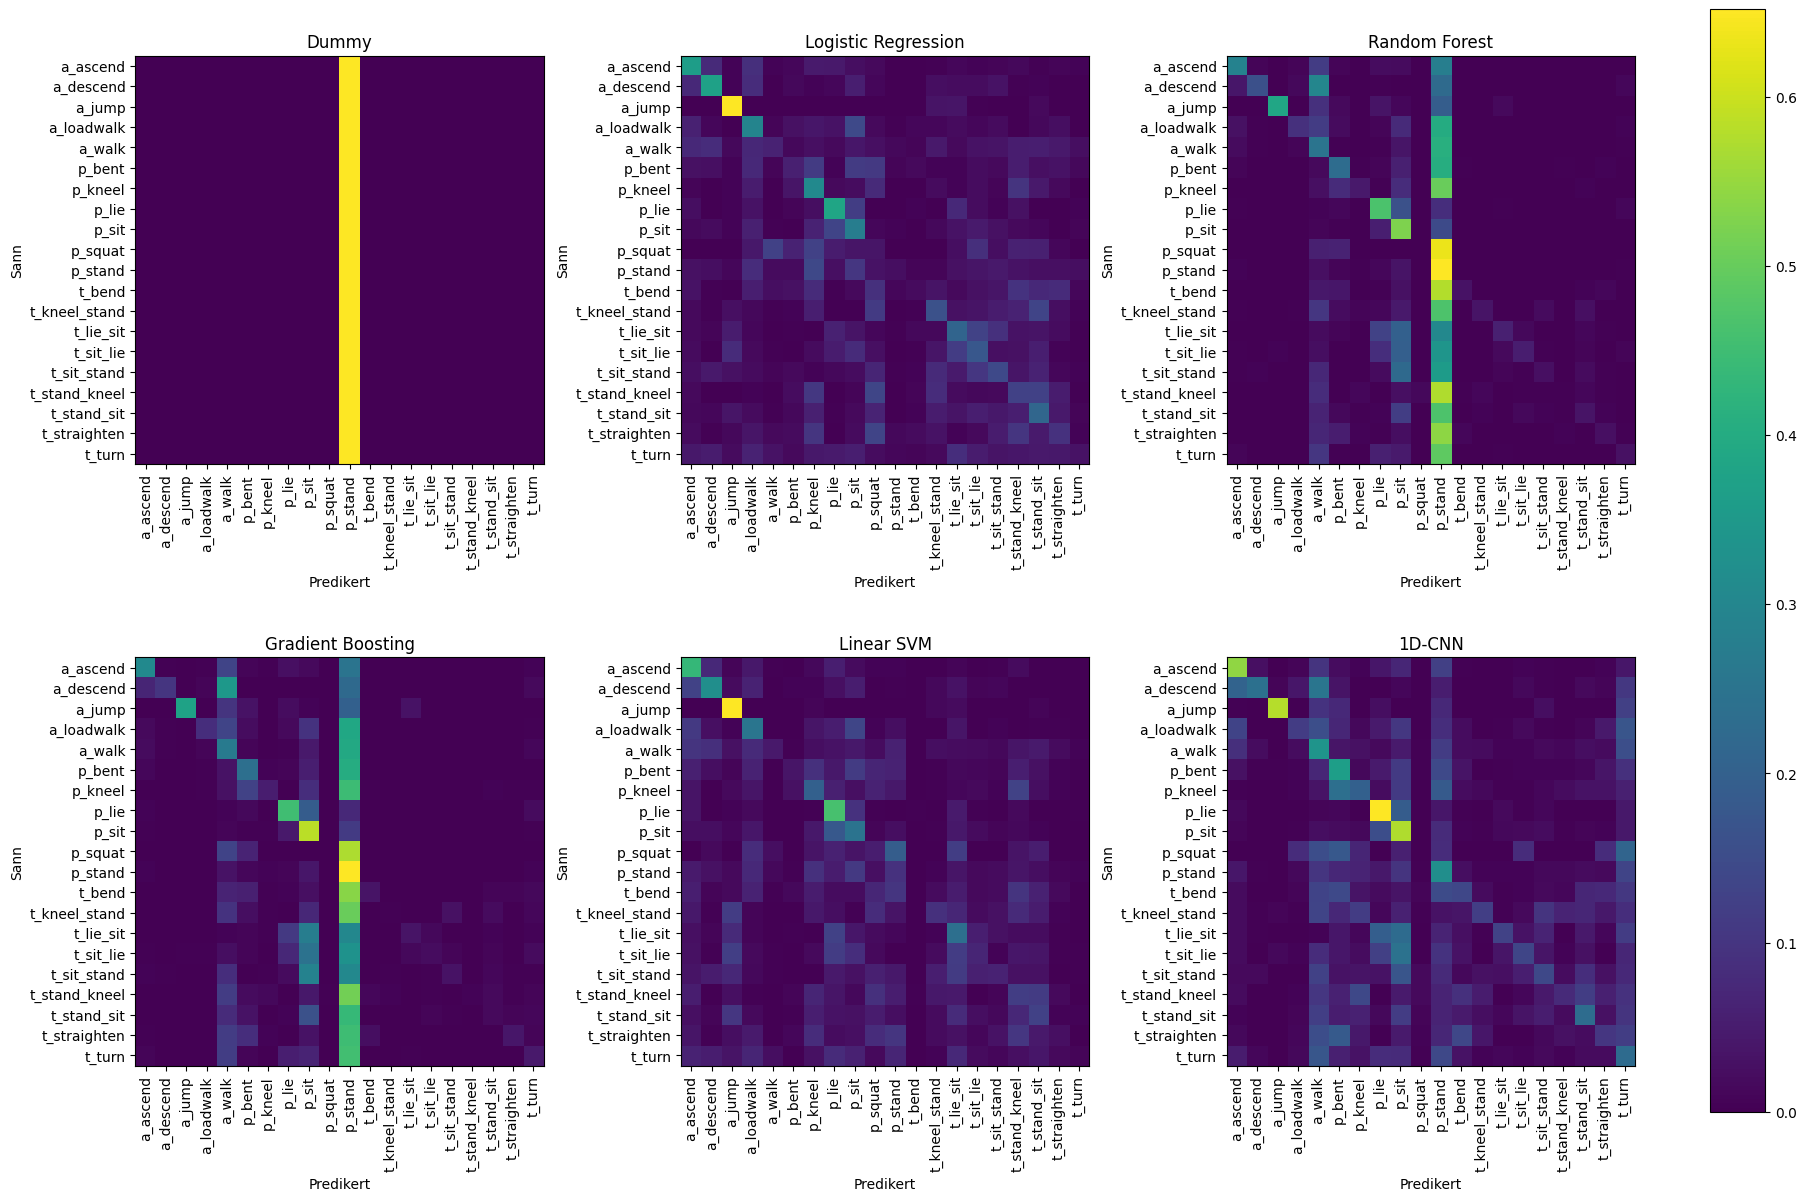

In [ ]:
cm_cache = f"{RESULT_DIR}/confusion_matrices.pkl"

if os.path.exists(cm_cache):

    confusion_mats = joblib.load(cm_cache)

else:

    confusion_mats = {}

    for name, preds in predictions.items():
        confusion_mats[name] = confusion_matrix(y_test, preds)

    joblib.dump(confusion_mats, cm_cache)



class_labels = sorted(y_test.unique())

n_models = len(predictions)
cols = 3
rows = int(np.ceil(n_models / cols))

fig, axes = plt.subplots(rows, cols, figsize=(18, 6 * rows), constrained_layout=True)
axes = axes.flatten()

for ax, (name, preds) in zip(axes, predictions.items()):

    cm = confusion_mats[name]

    cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

    im = ax.imshow(cm_norm, interpolation="nearest")

    ax.set_title(name)
    ax.set_xlabel("Predikert")
    ax.set_ylabel("Sann")

    ax.set_xticks(range(len(class_labels)))
    ax.set_yticks(range(len(class_labels)))

    ax.set_xticklabels(class_labels, rotation=90)
    ax.set_yticklabels(class_labels)

for ax in axes[n_models:]:
    ax.axis("off")

fig.colorbar(im, ax=axes.tolist())

plt.show()

###Per-Klasse F1

In [ ]:
f1_path = f"{RESULT_DIR}/per_class_f1.pkl"

if os.path.exists(f1_path):

    f1_comparison = joblib.load(f1_path)

else:

    classes = [
        c for c in reports[list(reports.keys())[0]].keys()
        if c not in ["accuracy", "macro avg", "weighted avg"]
    ]

    f1_comparison = pd.DataFrame({
        model: [reports[model][c]["f1-score"] for c in classes]
        for model in reports
    }, index=classes)

    joblib.dump(f1_comparison, f1_path)

f1_comparison

,Dummy,Logistic Regression,Random Forest,Gradient Boosting,Linear SVM,1D-CNN
a_ascend,0.000000,0.458770,0.505945,0.518282,0.460476,0.515178
a_descend,0.000000,0.157081,0.300970,0.210778,0.127927,0.244752
a_jump,0.000000,0.226003,0.633649,0.545095,0.141871,0.598729
a_loadwalk,0.000000,0.062113,0.158182,0.147909,0.062089,0.091397
a_walk,0.000000,0.134263,0.370532,0.371164,0.108190,0.324174
p_bent,0.000000,0.100154,0.380688,0.353114,0.093674,0.273213
p_kneel,0.000000,0.101082,0.096027,0.100313,0.095231,0.114129
p_lie,0.000000,0.451422,0.616407,0.608171,0.440288,0.534556
p_sit,0.000000,0.379611,0.665205,0.684351,0.358382,0.543594
p_squat,0.000000,0.001724,0.000000,0.000000,0.003094,0.000000


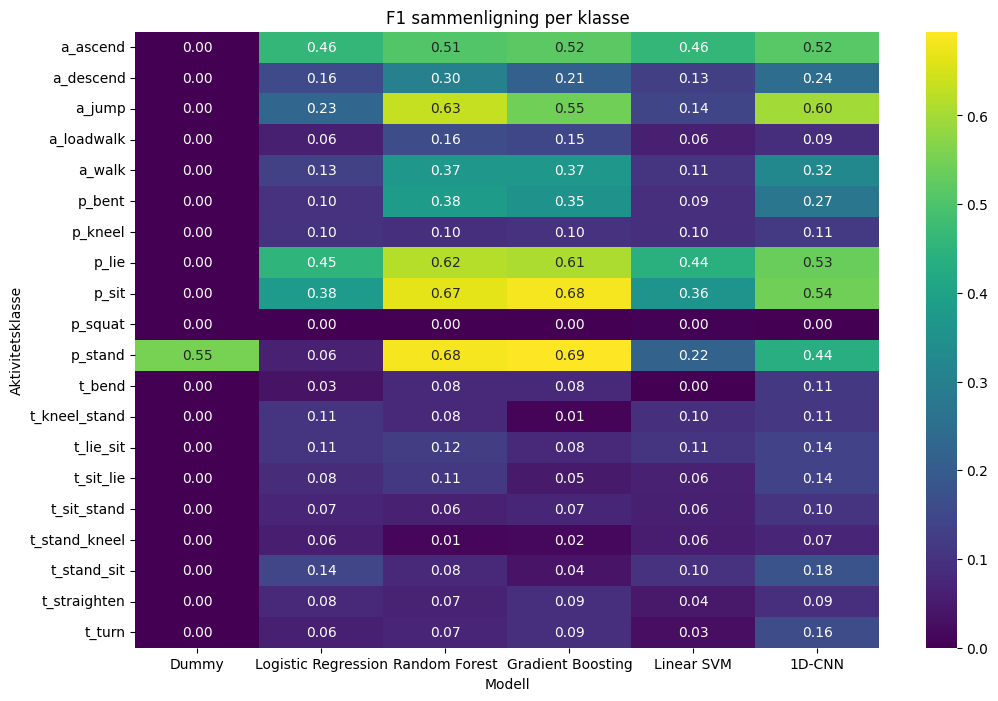

In [ ]:
import seaborn as sns

plt.figure(figsize=(12,8))

sns.heatmap(
    f1_comparison,
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.title("F1 sammenligning per klasse")
plt.ylabel("Aktivitetsklasse")
plt.xlabel("Modell")

plt.show()

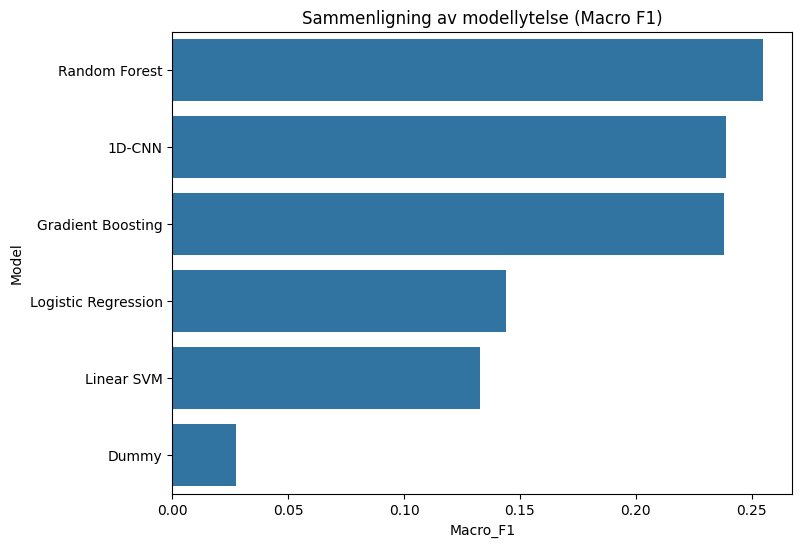

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=performance_df,
    x="Macro_F1",
    y="Model"
)

plt.title("Sammenligning av modellytelse (Macro F1)")

plt.show()

## Robusthet

### Random seed

In [ ]:
robustness_path = f"{RESULT_DIR}/robustness_results.pkl"

if os.path.exists(robustness_path):
    print("Laster cachede robusthet resultater...")
    robustness = joblib.load(robustness_path)

else:
    print("Kjører robusthet test...")

    robustness = {}
    seeds = [0, 1, 2]

    for name, model in models.items():

        scores = []
        print(f"Kjører test for {name}")

        for seed in seeds:

            print(f"Kjører test for seed: {seed}")
            model_temp = clone(model)

            if hasattr(model_temp, "random_state"):
                model_temp.random_state = seed

            if name == "Logistic Regression":
                continue
            elif name == "Gradient Boosting":
                continue
            elif name == "Linear SVM":
                Xtr = X_train_sub.sample(300000, random_state=seed)
                ytr = y_train_sub.loc[Xtr.index]
            else:
                Xtr = X_train_sub
                ytr = y_train_sub

            model_temp.fit(X_train_sub, y_train_sub)
            preds = model_temp.predict(X_test)
            score = f1_score(y_test, preds, average="macro")
            scores.append(score)

        robustness[name] = scores

    joblib.dump(robustness, robustness_path)

print("\nRobusthet resultater:")
print("-" * 40)

for name, scores in robustness.items():
    print(name)
    print("mean:", np.mean(scores))
    print("std :", np.std(scores))
    print()

Laster cachede robusthet resultater...

Robusthet resultater:
----------------------------------------
Dummy
mean: 0.027646359191225055
std : 0.0

Logistic Regression
mean: nan
std : nan

Random Forest
mean: 0.2525710705747337
std : 0.0009626746883030711

Gradient Boosting
mean: nan
std : nan

Linear SVM
mean: 0.1329538657251617
std : 0.0



/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


### Manglende sensordata

In [ ]:
acc_features = [
    "x_mean",
    "x_std",
    "y_mean",
    "y_std",
    "z_mean",
    "z_std"
]

pir_features = [
    c for c in X_train.columns
    if c not in acc_features
]

print("ACC features:", acc_features)
print("PIR features:", pir_features)

ACC features: ['x_mean', 'x_std', 'y_mean', 'y_std', 'z_mean', 'z_std']
PIR features: ['bath', 'bed1', 'bed2', 'hall', 'kitchen_x', 'living_x', 'stairs_x', 'study_x', 'toilet', 'kitchen_y', 'living_y', 'study_y', 'stairs_y']


In [ ]:
feature_sets = {
    "ACC_only": acc_features,
    "PIR_only": pir_features,
    "ACC+PIR": acc_features + pir_features
}

ablation_path = f"{RESULT_DIR}/sensor_ablation.pkl"

if os.path.exists(ablation_path):
    print("Laster cachede resultater for eksperimenter ved manglende sensordata")
    ablation_results = joblib.load(ablation_path)

else:
    print("Kjører eksperimenter for resultater ved manglende sensordata")
    ablation_results = []

    for exp_name, features in feature_sets.items():

        print("Kjører:", exp_name)

        Xtr = X_train_sub[features]
        Xte = X_test[features]

        for model_name, model in models.items():

            model_temp = clone(model)

            model_temp.fit(Xtr, y_train_sub)

            preds = model_temp.predict(Xte)

            score = f1_score(
                y_test,
                preds,
                average="macro"
            )

            ablation_results.append({
                "Experiment": exp_name,
                "Model": model_name,
                "Macro_F1": score
            })

    ablation_results = pd.DataFrame(ablation_results)

    joblib.dump(ablation_results, ablation_path)

ablation_results

Laster cachede resultater for eksperimenter ved manglende sensordata


,Experiment,Model,Macro_F1
0,ACC_only,Dummy,0.027646
1,ACC_only,Logistic Regression,0.082344
2,ACC_only,Random Forest,0.173242
3,ACC_only,Gradient Boosting,0.141663
4,ACC_only,Linear SVM,0.059932
5,PIR_only,Dummy,0.027646
6,PIR_only,Logistic Regression,0.072206
7,PIR_only,Random Forest,0.125537
8,PIR_only,Gradient Boosting,0.127927
9,PIR_only,Linear SVM,0.061745


Samme som over men med RSSI features

In [ ]:
acc_features = [c for c in X_train.columns if c.startswith(("x_", "y_", "z_"))]

pir_features = [
    c for c in X_train.columns
    if c in [
        "bath", "bed1", "bed2", "hall", "toilet",
        "kitchen_x", "living_x", "stairs_x", "study_x"
    ]
]

rssi_features = [
    c for c in X_train.columns
    if c.endswith("_y")
]

print("ACC features:", acc_features)
print("PIR features:", pir_features)
print("RSSI features:", rssi_features)

print("Antall ACC:", len(acc_features))
print("Antall PIR:", len(pir_features))
print("Antall RSSI:", len(rssi_features))

print("Sample ACC:")
print(X_train_sub[acc_features].head())

print("Sample PIR:")
print(X_train_sub[pir_features].head())

print("Sample RSSI:")
print(X_train_sub[rssi_features].head())

feature_sets = {
    "ACC_only": acc_features,
    "PIR_only": pir_features,
    "RSSI_only": rssi_features,
    "ACC+PIR": acc_features + pir_features,
    "ACC+RSSI": acc_features + rssi_features,
    "ALL": acc_features + pir_features + rssi_features
}

print("Feature sets:")
for name, feats in feature_sets.items():
    print(name, len(feats), feats)

ACC features: ['x_mean', 'x_std', 'y_mean', 'y_std', 'z_mean', 'z_std']
PIR features: ['bath', 'bed1', 'bed2', 'hall', 'kitchen_x', 'living_x', 'stairs_x', 'study_x', 'toilet']
RSSI features: ['kitchen_y', 'living_y', 'study_y', 'stairs_y']
Antall ACC: 6
Antall PIR: 9
Antall RSSI: 4
Sample ACC:
         x_mean     x_std  y_mean     y_std  z_mean     z_std
1952903  0.1044  0.056418 -0.6197  0.087716  0.8190  0.081518
1619548  0.8485  0.555509 -0.8319  0.473783  0.0271  0.378927
456605   0.1126  0.110992 -0.4039  0.028694  0.9520  0.092130
475451   0.0472  0.041266  0.0530  0.131891  1.0505  0.054363
477318   0.4991  0.412863 -0.5257  0.238260  0.4739  0.275506
Sample PIR:
         bath  bed1  bed2  hall  kitchen_x  living_x  stairs_x  study_x  \
1952903   0.0   1.0   0.0   0.0        0.0       0.0       0.0      0.0   
1619548   0.0   0.0   0.0   0.0        0.0       1.0       0.0      0.0   
456605    0.0   0.0   0.0   0.0        1.0       0.0       0.0      0.0   
475451    0.0   0.0 

In [ ]:
ablation_path = f"{RESULT_DIR}/sensor_ablation_v2.pkl"

if os.path.exists(ablation_path):
    print("Laster cachede resultater for eksperimenter ved manglende sensordata")
    ablation_results = joblib.load(ablation_path)
else:
    print("Kjører eksperimenter for resultater ved manglende sensordata")
    ablation_results = []

    for exp_name, features in feature_sets.items():
        print("Kjører:", exp_name)

        Xtr = X_train_sub[features]
        Xte = X_test[features]

        for model_name, model in models.items():
            model_temp = clone(model)
            model_temp.fit(Xtr, y_train_sub)
            preds = model_temp.predict(Xte)

            score = f1_score(
                y_test,
                preds,
                average="macro"
            )

            ablation_results.append({
                "Experiment": exp_name,
                "Model": model_name,
                "Macro_F1": score
            })

    ablation_results = pd.DataFrame(ablation_results)
    joblib.dump(ablation_results, ablation_path)

print(ablation_results)

Laster cachede resultater for eksperimenter ved manglende sensordata
   Experiment                Model  Macro_F1
0    ACC_only                Dummy  0.027646
1    ACC_only  Logistic Regression  0.082344
2    ACC_only        Random Forest  0.173242
3    ACC_only    Gradient Boosting  0.151264
4    ACC_only           Linear SVM  0.059932
5    PIR_only                Dummy  0.027646
6    PIR_only  Logistic Regression  0.047146
7    PIR_only        Random Forest  0.037903
8    PIR_only    Gradient Boosting  0.046434
9    PIR_only           Linear SVM  0.047108
10  RSSI_only                Dummy  0.027646
11  RSSI_only  Logistic Regression  0.050871
12  RSSI_only        Random Forest  0.104807
13  RSSI_only    Gradient Boosting  0.111946
14  RSSI_only           Linear SVM  0.044705
15    ACC+PIR                Dummy  0.027646
16    ACC+PIR  Logistic Regression  0.109133
17    ACC+PIR        Random Forest  0.190183
18    ACC+PIR    Gradient Boosting  0.161126
19    ACC+PIR           Linear 

In [ ]:
print(ablation_results.sort_values(["Experiment", "Macro_F1"], ascending=[True, False]))

   Experiment                Model  Macro_F1
17    ACC+PIR        Random Forest  0.190183
18    ACC+PIR    Gradient Boosting  0.161126
16    ACC+PIR  Logistic Regression  0.109133
19    ACC+PIR           Linear SVM  0.094653
15    ACC+PIR                Dummy  0.027646
22   ACC+RSSI        Random Forest  0.244120
23   ACC+RSSI    Gradient Boosting  0.222585
21   ACC+RSSI  Logistic Regression  0.110321
24   ACC+RSSI           Linear SVM  0.083246
20   ACC+RSSI                Dummy  0.027646
2    ACC_only        Random Forest  0.173242
3    ACC_only    Gradient Boosting  0.151264
1    ACC_only  Logistic Regression  0.082344
4    ACC_only           Linear SVM  0.059932
0    ACC_only                Dummy  0.027646
27        ALL        Random Forest  0.251863
28        ALL    Gradient Boosting  0.224614
26        ALL  Logistic Regression  0.133868
29        ALL           Linear SVM  0.117720
25        ALL                Dummy  0.027646
6    PIR_only  Logistic Regression  0.047146
9    PIR_o

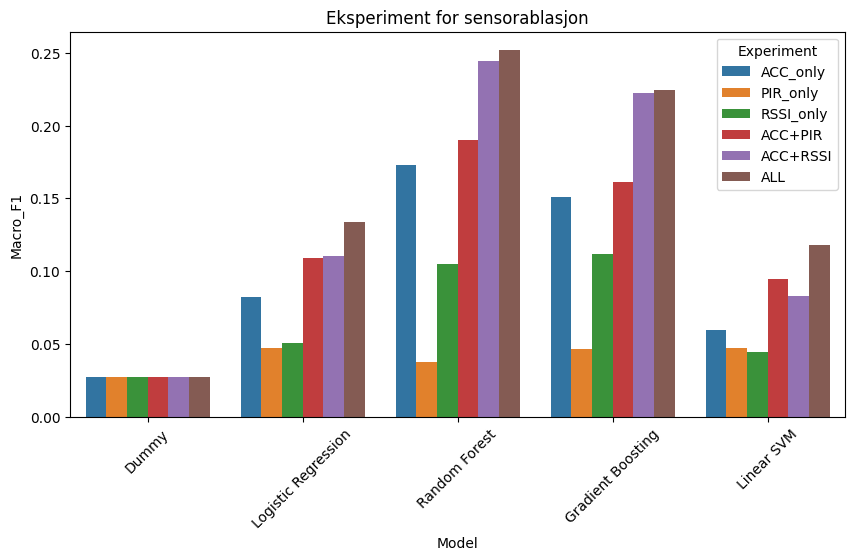

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=ablation_results,
    x="Model",
    y="Macro_F1",
    hue="Experiment"
)

plt.title("Eksperiment for sensorablasjon")
plt.xticks(rotation=45)

plt.show()

### Datastøy

In [ ]:
def add_gaussian_noise(X, noise_level):

    noise = np.random.normal(
        loc=0,
        scale=noise_level,
        size=X.shape
    )

    return X + noise

In [ ]:
noise_levels = [0, 0.05, 0.1, 0.2]

In [ ]:
noise_path = f"{RESULT_DIR}/noise_robustness.pkl"

if os.path.exists(noise_path):
    print("Laster cachede resultater for eksperimenter ved datastøy")
    noise_results = joblib.load(noise_path)

else:
    print("Kjører eksperimenter for resultater ved datastøy")
    noise_results = []

    for noise in noise_levels:
        print("Støynivå:", noise)
        X_test_noisy = add_gaussian_noise(X_test, noise)

        for name, model in trained_models.items():

            if name == "1D-CNN":
                X_noisy_cnn = X_test_noisy.values.reshape(-1, n_features, 1)
                preds_encoded = np.argmax(model.predict(X_noisy_cnn, verbose=0), axis=1)
                preds = le.inverse_transform(preds_encoded)
            else:
                preds = model.predict(X_test_noisy)

            score = f1_score(
                y_test,
                preds,
                average="macro",
                zero_division=0
            )

            noise_results.append({
                "Model": name,
                "Noise": noise,
                "Macro_F1": score
            })

    noise_results = pd.DataFrame(noise_results)
    joblib.dump(noise_results, noise_path)

noise_results

Laster cachede resultater for eksperimenter ved datastøy


,Model,Noise,Macro_F1
0,Dummy,0.00,0.027646
1,Logistic Regression,0.00,0.133868
2,Random Forest,0.00,0.251545
3,Gradient Boosting,0.00,0.199601
4,Linear SVM,0.00,0.117720
5,1D-CNN,0.00,0.239128
6,Dummy,0.05,0.027646
7,Logistic Regression,0.05,0.133316
8,Random Forest,0.05,0.213911
9,Gradient Boosting,0.05,0.155109


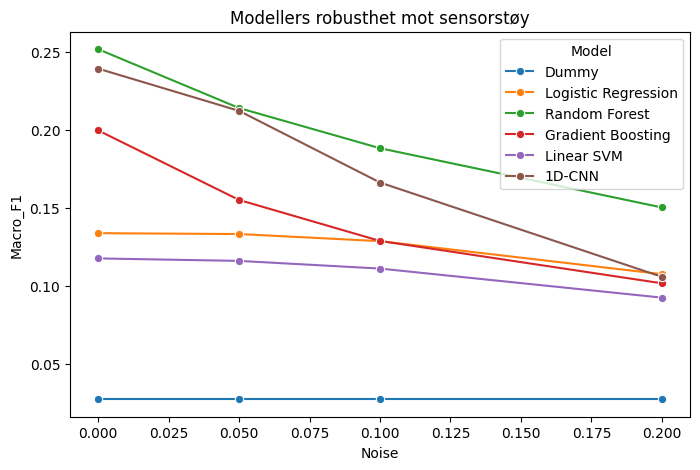

In [ ]:
plt.figure(figsize=(8,5))

sns.lineplot(
    data=noise_results,
    x="Noise",
    y="Macro_F1",
    hue="Model",
    marker="o"
)

plt.title("Modellers robusthet mot sensorstøy")

plt.show()

## Forklarbarhet
Forklarbarhet handler om å forstå hvorfor modellen tar de beslutningene den tar. Vi starter med feature importance for å få et overordnet bilde av hvilke features som er viktigst, før vi går videre til SHAP for mer detaljerte forklaringer per prediksjon.

### Feature importance
Feature importance forteller oss hvilke features modellen generelt vektlegger mest. Vi starter med Random Forest.

In [ ]:
fi_path = f"{RESULT_DIR}/feature_importance_rf.pkl"

if os.path.exists(fi_path):
    print("Laster cachet feature importance")
    importances = joblib.load(fi_path)

else:
    print("Beregner feature importance")
    rf_model = trained_models["Random Forest"]

    importances = pd.Series(
        rf_model.feature_importances_,
        index=X_train_sub.columns
    ).sort_values(ascending=False)

    joblib.dump(importances, fi_path)



Laster cachet feature importance


### SHAP

In [ ]:
# =========================
# SHAP CACHE BLOKK (RF)
# =========================

import shap
import joblib
import os


BASE_CACHE_DIR = "/content/drive/MyDrive/DAT191_H3_project_shared"
SHAP_DIR = os.path.join(BASE_CACHE_DIR, "shap")
os.makedirs(SHAP_DIR, exist_ok=True)

rf_shap_sample_path  = os.path.join(SHAP_DIR, "rf_shap_sample.pkl")
rf_shap_values_path  = os.path.join(SHAP_DIR, "rf_shap_values.pkl")
rf_shap_classes_path = os.path.join(SHAP_DIR, "rf_shap_classes.pkl")

# leiter etter cached SHAP
if (
    os.path.exists(rf_shap_sample_path) and
    os.path.exists(rf_shap_values_path) and
    os.path.exists(rf_shap_classes_path)
):

    print("Laster cached SHAP for Random Forest")

    x_shap_sample = joblib.load(rf_shap_sample_path)
    rf_shap_values = joblib.load(rf_shap_values_path)
    rf_classes = joblib.load(rf_shap_classes_path)

# Generer Shap
else:

    print("Genererer SHAP for Random Forest ")

    rf_model = trained_models["Random Forest"]

    # juster størrelse om nødvendig
    x_shap_sample = X_test.sample(100, random_state=42)

    rf_explainer = shap.TreeExplainer(rf_model)
    rf_shap_values = rf_explainer.shap_values(x_shap_sample)

    rf_classes = rf_model.classes_

    joblib.dump(x_shap_sample, rf_shap_sample_path)
    joblib.dump(rf_shap_values, rf_shap_values_path)
    joblib.dump(rf_classes, rf_shap_classes_path)

    print("SHAP lagret til cache")

#
print("SHAP shape:", rf_shap_values.shape)
print("Antall klasser:", len(rf_classes))
print("Klasser:", rf_classes)

Laster cached SHAP for Random Forest
SHAP shape: (100, 19, 20)
Antall klasser: 20
Klasser: ['a_ascend' 'a_descend' 'a_jump' 'a_loadwalk' 'a_walk' 'p_bent' 'p_kneel'
 'p_lie' 'p_sit' 'p_squat' 'p_stand' 't_bend' 't_kneel_stand' 't_lie_sit'
 't_sit_lie' 't_sit_stand' 't_stand_kneel' 't_stand_sit' 't_straighten'
 't_turn']


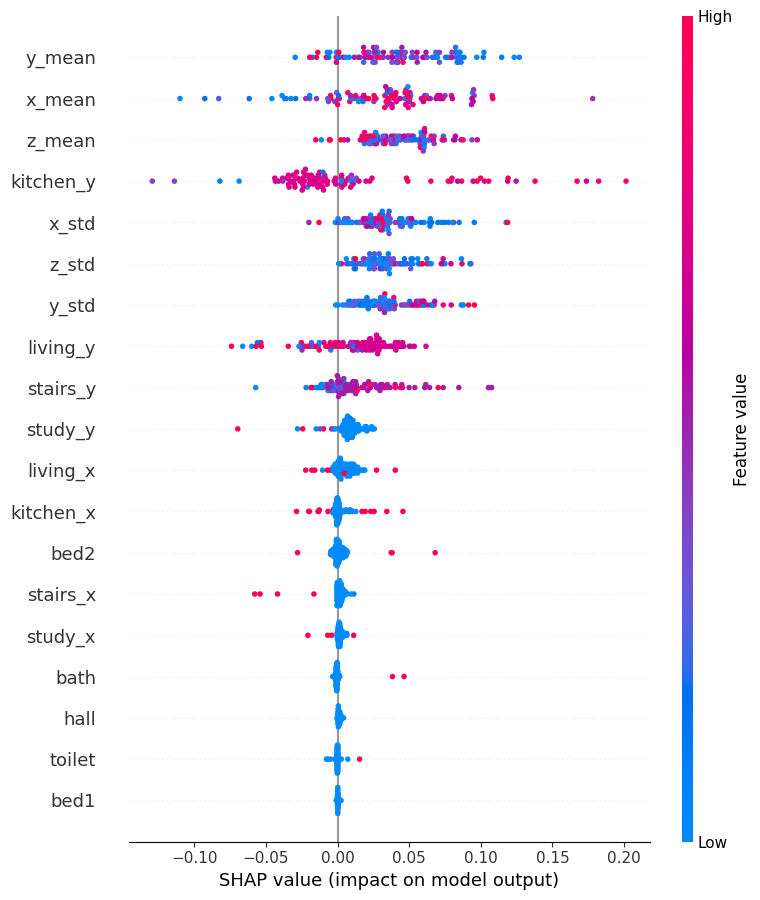

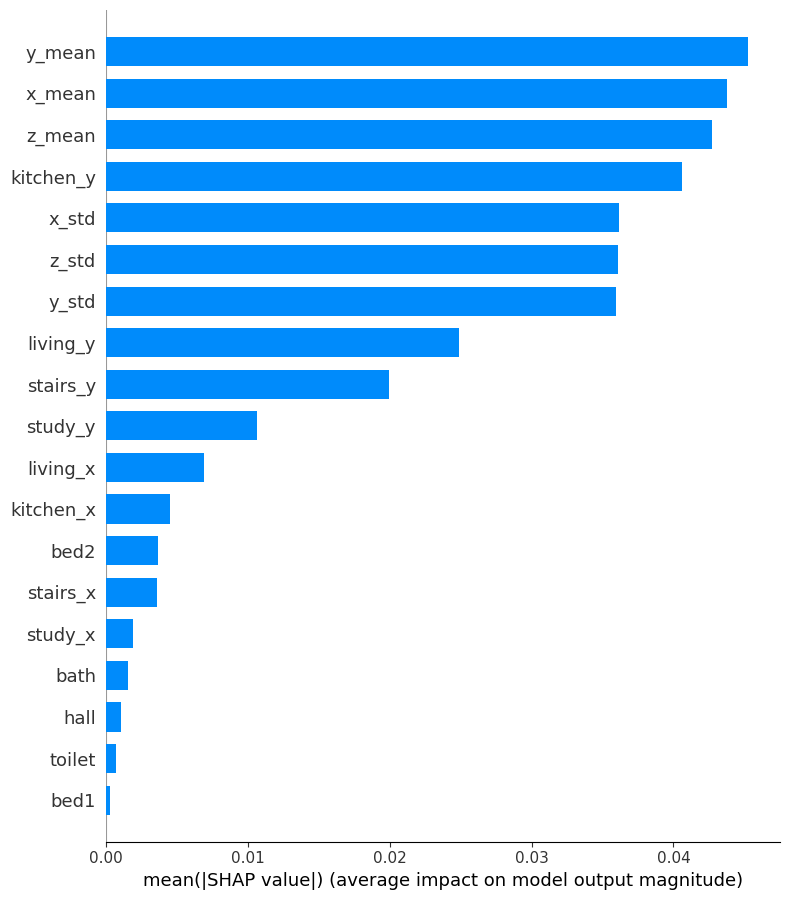

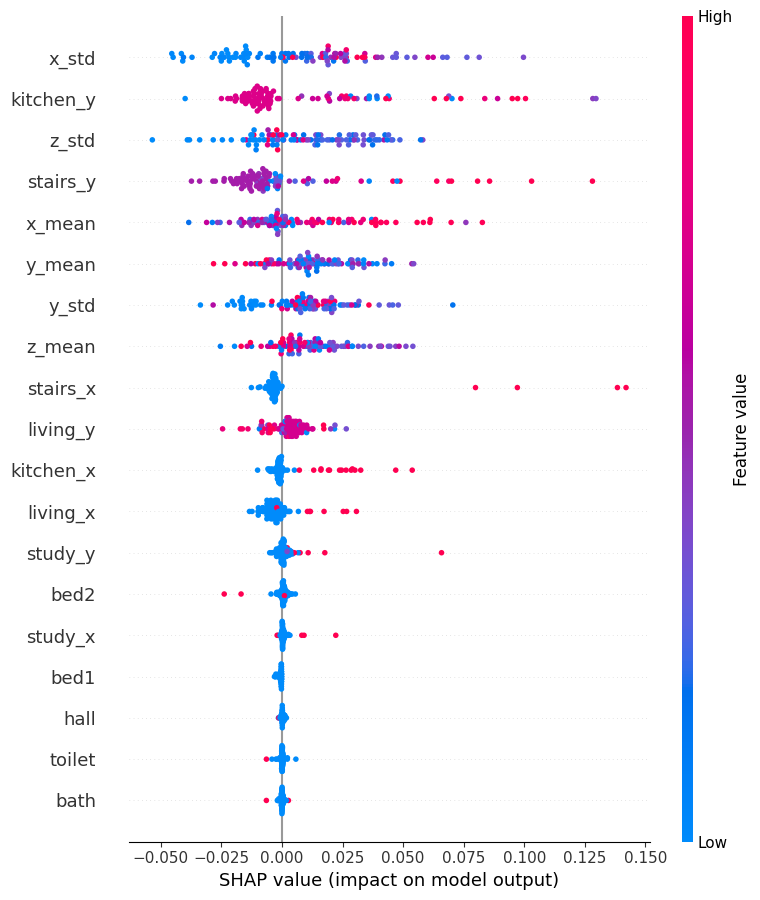

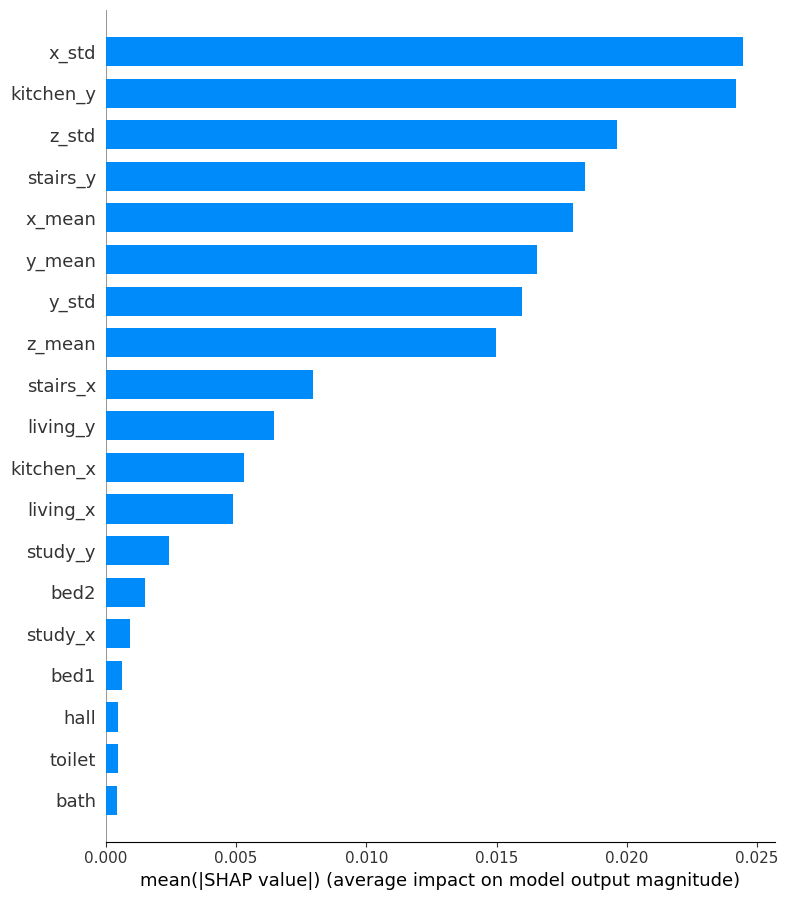

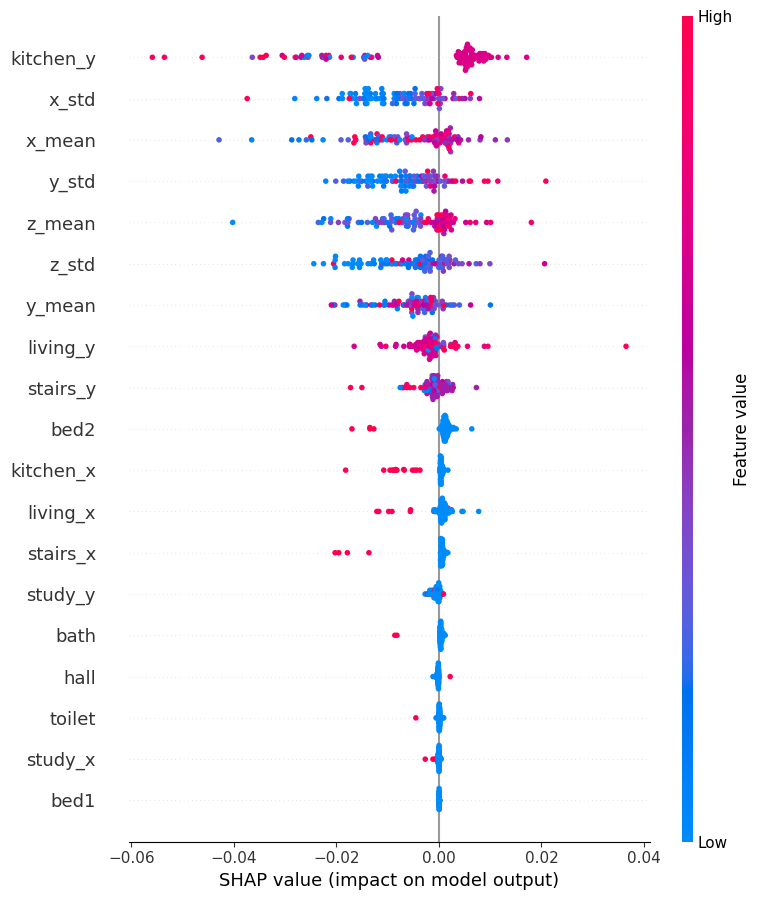

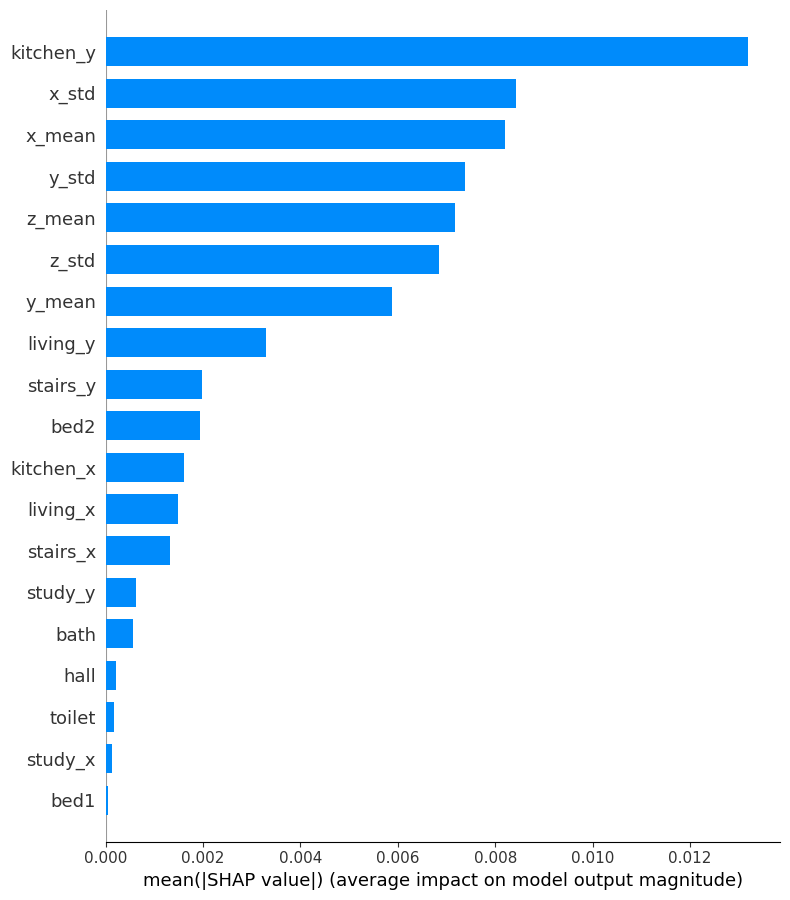

In [ ]:
selected_classes = ["p_stand", "a_walk", "t_sit_stand"]

for class_name in selected_classes:

    class_idx = list(rf_classes).index(class_name)


    # Beeswarm
    shap.summary_plot(
        rf_shap_values[:, :, class_idx],
        x_shap_sample
    )

    # Bar plot
    shap.summary_plot(
        rf_shap_values[:, :, class_idx],
        x_shap_sample,
        plot_type="bar"
    )

## Eksperiment - Sammenslåing av overgangsklasser
I dette eksperimentet slår vi sammen alle overgangsklasser (t_*) til en klasse kalt "transition". Målet er å undersøke om dette forbedrer Macro-F1 ved å redusere støy fra sjeldne og vanskelige klasser.

#Merked Klasser

In [ ]:
def merge_transition_classes(y):
    return y.apply(lambda x: "transition" if x.startswith("t_") else x)

y_train_sub_merged = merge_transition_classes(y_train_sub)
y_test_merged = merge_transition_classes(y_test)

print("Originale klasser:", sorted(y_test.unique()))
print("\nKlasser etter sammenslåing:", sorted(y_test_merged.unique()))
print("\nAntall transition-samples i testsett:", y_test_merged.value_counts()["transition"])

Originale klasser: ['a_ascend', 'a_descend', 'a_jump', 'a_loadwalk', 'a_walk', 'p_bent', 'p_kneel', 'p_lie', 'p_sit', 'p_squat', 'p_stand', 't_bend', 't_kneel_stand', 't_lie_sit', 't_sit_lie', 't_sit_stand', 't_stand_kneel', 't_stand_sit', 't_straighten', 't_turn']

Klasser etter sammenslåing: ['a_ascend', 'a_descend', 'a_jump', 'a_loadwalk', 'a_walk', 'p_bent', 'p_kneel', 'p_lie', 'p_sit', 'p_squat', 'p_stand', 'transition']

Antall transition-samples i testsett: 488670


### Trening på merged klasser

In [ ]:
trained_models_merged = {}

for name, model in models.items():
    model_path = f"{MODEL_MERGED_DIR}/{name}_merged_model.pkl"

    if os.path.exists(model_path):
        print(f"Laster {name} merged fra Drive...")
        model_temp = joblib.load(model_path)
    else:
        print(f"Trener {name} på merged klasser...")
        model_temp = clone(model)
        model_temp.fit(X_train_sub, y_train_sub_merged)
        joblib.dump(model_temp, model_path)

    trained_models_merged[name] = model_temp

Laster Dummy merged fra Drive...
Laster Logistic Regression merged fra Drive...
Laster Random Forest merged fra Drive...
Laster Gradient Boosting merged fra Drive...
Laster Linear SVM merged fra Drive...


### Prediksjoner på merged klasser

In [ ]:
predictions_merged = {}

for name, model in trained_models_merged.items():
    pred_path = f"{PRED_DIR}/{name}_merged_no_filter_temporal_preds.pkl"

    if os.path.exists(pred_path):
        print(f"Laster prediksjoner for {name}")
        preds = joblib.load(pred_path)
    else:
        print(f"Genererer prediksjoner for {name}")
        preds = model.predict(X_test)
        joblib.dump(preds, pred_path)

    predictions_merged[name] = preds

Laster prediksjoner for Dummy
Laster prediksjoner for Logistic Regression
Laster prediksjoner for Random Forest
Laster prediksjoner for Gradient Boosting
Laster prediksjoner for Linear SVM


### Evaluering - merged klasser vs originale klasser
Her sammenligner vi ytelsen med og uten sammenslåing av overgangsklasser.

In [ ]:
perf_merged_path = f"{RESULT_DIR}/performance_merged_df.pkl"

if os.path.exists(perf_merged_path):
    print("Laster cached merged resultater")
    performance_merged_df = joblib.load(perf_merged_path)

else:
    results_merged = []

    for name, preds in predictions_merged.items():
        results_merged.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test_merged, preds),
            "Macro_F1": f1_score(y_test_merged, preds, average="macro"),
            "Weighted_F1": f1_score(y_test_merged, preds, average="weighted"),
            "Macro_Precision": precision_score(y_test_merged, preds, average="macro", zero_division=0),
            "Macro_Recall": recall_score(y_test_merged, preds, average="macro", zero_division=0)
        })

    performance_merged_df = pd.DataFrame(results_merged).sort_values("Macro_F1", ascending=False)
    joblib.dump(performance_merged_df, perf_merged_path)

print("Originale klasser")
print(performance_df[["Model", "Macro_F1", "Accuracy"]].to_string(index=False))
print("\nMerged klasser")
print(performance_merged_df[["Model", "Macro_F1", "Accuracy"]].to_string(index=False))

Laster cached merged resultater
Originale klasser
              Model  Macro_F1  Accuracy
      Random Forest  0.254784  0.564659
             1D-CNN  0.239128  0.374184
  Gradient Boosting  0.237936  0.566613
Logistic Regression  0.144080  0.182886
         Linear SVM  0.132954  0.223174
              Dummy  0.027646  0.382100

Merged klasser
              Model  Macro_F1  Accuracy
      Random Forest  0.403238  0.591095
  Gradient Boosting  0.353638  0.571484
Logistic Regression  0.231343  0.461605
         Linear SVM  0.205997  0.447964
              Dummy  0.046077  0.382100


### Konklusjon - Sammenslåing av overgangsklasser

Eksperimentet viser at sammenslåing av overgangsklassene (t_*) til en felles klasse "transition" gir en betydelig forbedring i Macro-F1 for alle modeller.
Dette indikerer at overgangsklassene er en stor kilde til støy i datasettet, noe som også støttes av den lave label-confidence som ble observert i dataanalysen. Sammenslåingen gir et mer stabilt klassifikasjonsproblem, men på bekostning av detaljert informasjon om hvilken spesifikk overgang som utføres.

# EKSPERIMENT - 1D-CNN
Dette eksperimentet undersøker om en korrekt implementasjon av 1D-CNN
med rå tidsseriedata gir bedre ytelse enn den originale implementasjonen
med aggregerte features. Akselerometer (xyz) og PIR-data resamples til
100 tidssteg per 5-sekunders vindu og brukes direkte som input til modellen.

In [ ]:
def build_sequence_dataframe_raw_cnn(seq_path, window_size=5, stride=1, target_hz=20):
    activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
    acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
    pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))

    activity_cols = [c for c in activity.columns if c != "t"]
    activity["max_prob"] = activity[activity_cols].max(axis=1)

    pir_cols = [c for c in pir.columns if c != "t"]
    n_pir = len(pir_cols)

    max_time = int(min(acc["t"].max(), activity["t"].max(), pir["t"].max()))

    sequences = []
    labels = []
    confidences = []

    n_steps = window_size * target_hz  # 100 tidssteg

    for start in range(0, max_time - window_size + 1, stride):
        end = start + window_size

        acc_win = acc[(acc["t"] >= start) & (acc["t"] < end)]
        pir_win = pir[(pir["t"] >= start) & (pir["t"] < end)]
        act_win = activity[(activity["t"] >= start) & (activity["t"] < end)]

        if len(acc_win) < 2 or len(pir_win) < 2 or len(act_win) == 0:
            continue

        from scipy.interpolate import interp1d
        t_new = np.linspace(0, 1, n_steps)

        # ACC resample
        xyz = acc_win[["x", "y", "z"]].values
        t_acc = np.linspace(0, 1, len(xyz))
        acc_resampled = np.zeros((n_steps, 3))
        for i in range(3):
            f = interp1d(t_acc, xyz[:, i], kind="linear")
            acc_resampled[:, i] = f(t_new)

        # PIR resample
        pir_vals = pir_win[pir_cols].values
        t_pir = np.linspace(0, 1, len(pir_vals))
        pir_resampled = np.zeros((n_steps, n_pir))
        for i in range(n_pir):
            f = interp1d(t_pir, pir_vals[:, i], kind="nearest")
            pir_resampled[:, i] = f(t_new)

        # Kombiner ACC + PIR
        combined = np.concatenate([acc_resampled, pir_resampled], axis=1)

        label = act_win[activity_cols].mean().idxmax()
        confidence = act_win["max_prob"].mean()

        sequences.append(combined)
        labels.append(label)
        confidences.append(confidence)

    return np.array(sequences), pd.Series(labels), pd.Series(confidences)

In [ ]:
import time

seq_id = train_sequences[0]
seq_path = os.path.join(TRAIN_ROOT, seq_id)

start = time.time()
X_raw, y_raw, conf_raw = build_sequence_dataframe_raw_cnn(seq_path)
end = time.time()

print(f"Tid for én sekvens: {end-start:.1f} sekunder")
print(f"Shape: {X_raw.shape}")  # Skal være (n_samples, 100, 3)
print(f"Antall samples: {len(y_raw)}")

Tid for én sekvens: 6.3 sekunder
Shape: (1819, 100, 12)
Antall samples: 1819


In [ ]:
print("Antall treningssekvenser:", len(train_sequences))
print("Antall testsekvenser:", len(test_sequences))

Antall treningssekvenser: 10
Antall testsekvenser: 9


In [ ]:
# Test hele treningssettet
import time

start = time.time()

X_list, y_list, conf_list = [], [], []

for seq in train_sequences:
    seq_path = os.path.join(TRAIN_ROOT, seq)
    try:
        X_seq, y_seq, conf_seq = build_sequence_dataframe_raw_cnn(seq_path)
        X_list.append(X_seq)
        y_list.append(y_seq)
        conf_list.append(conf_seq)
        print(f"Ferdig: {seq}")
    except Exception as e:
        print(f"Feil i {seq}: {e}")

X_train_raw = np.concatenate(X_list)
y_train_raw = pd.concat(y_list, ignore_index=True)

end = time.time()
print(f"\nTotal tid: {end-start:.1f} sekunder")
print(f"Shape: {X_train_raw.shape}")

Ferdig: 00001
Ferdig: 00002
Ferdig: 00003
Ferdig: 00004
Ferdig: 00005
Ferdig: 00006
Ferdig: 00007
Ferdig: 00008
Ferdig: 00009
Ferdig: 00010

Total tid: 56.9 sekunder
Shape: (16283, 100, 12)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

le_raw = LabelEncoder()
y_train_raw_enc = le_raw.fit_transform(y_train_raw)
n_classes_raw = len(le_raw.classes_)

class_weights_raw = dict(enumerate(
    compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_train_raw_enc),
        y=y_train_raw_enc
    )
))

def build_cnn_raw(n_steps, n_features, n_classes):
    model = keras.Sequential([
        layers.Input(shape=(n_steps, n_features)),

        layers.Conv1D(64, kernel_size=5, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=5, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(256, kernel_size=3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_raw_model = build_cnn_raw(100, 12, n_classes_raw)
cnn_raw_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 100, 64)        │         3,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 50, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 25, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,820 (706.33 KB)

 Trainable params: 179,924 (702.83 KB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# Finn antall features fra nye data
n_features_raw = X_train_raw.shape[2]
print("Antall features:", n_features_raw)


cnn_raw_model = build_cnn_raw(100, n_features_raw, n_classes_raw)


history_raw = cnn_raw_model.fit(
    X_train_raw,
    y_train_raw_enc,
    epochs=30,
    batch_size=256,
    validation_split=0.1,
    class_weight=class_weights_raw,
    callbacks=[
        keras.callbacks.EarlyStopping(
            patience=5,
            restore_best_weights=True
        )
    ]
)

Antall features: 12
Epoch 1/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 26s 241ms/step - accuracy: 0.1353 - loss: 2.5573 - val_accuracy: 0.0184 - val_loss: 2.9475
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1820 - loss: 2.1482 - val_accuracy: 0.0583 - val_loss: 2.7907
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2010 - loss: 1.9490 - val_accuracy: 0.0559 - val_loss: 2.7372
Epoch 4/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2081 - loss: 1.9154 - val_accuracy: 0.1314 - val_loss: 2.6164
Epoch 5/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2214 - loss: 1.7784 - val_accuracy: 0.1142 - val_loss: 2.6267
Epoch 6/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2225 - loss: 1.7335 - val_accuracy: 0.0724 - val_loss: 2.6147
Epoch 7/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2304 - loss: 1.6728 - val_accuracy: 0.0939 - val_loss: 2.6588
Epoch 8/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2397 - loss: 1.5894 - val_accur

### Konklusjon - Rå tidsseriedata for 1D-CNN


Eksperimentet testet en korrekt implementasjon av 1D-CNN med rå tidsseriedata
(akselerometer xyz + PIR) i stedet for aggregerte features.

**Input shape:** (n_samples, 100, 12) — 100 tidssteg × 12 sensorer
**Treningssekvenser:** 10
**Resultat:** Val_accuracy stabiliserte seg rundt 0.10-0.16

**Konklusjon:**
Selv med korrekt tidsserieformat oppnådde modellen ikke bedre ytelse enn
Random Forest. Sannsynlig årsak er at 10 treningssekvenser er for lite data
for et nevralt nettverk. Dette bekrefter at klassiske ensemble-metoder er
mer dataeffisiente for dette datasettet.

Dette støtter funnene i rapporten om at Random Forest gir best balanse
mellom ytelse og robusthet for SPHERE-datasettet.

##Raw CNN V2

In [ ]:
# RAW CNN V2 DATASETT

import os
import joblib
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d

BASE_CACHE_DIR = "/content/drive/MyDrive/DAT191_H3_project_shared"
DATASET_VERSION = "v3_5s_stride1"
V3_DIR = os.path.join(BASE_CACHE_DIR, DATASET_VERSION)

RAW_CNN_DIR = os.path.join(V3_DIR, "raw_cnn_v2")
os.makedirs(RAW_CNN_DIR, exist_ok=True)

RAW_CNN_WINDOW_SIZE = 5
RAW_CNN_STRIDE = 1
RAW_CNN_TARGET_HZ = 20
RAW_CNN_CONF_THRESHOLD = 0.6

def build_raw_cnn_sequence_dataset(seq_path, window_size=5, stride=1, target_hz=20):
    activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
    acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
    pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))

    activity_cols = [c for c in activity.columns if c != "t"]
    activity["max_prob"] = activity[activity_cols].max(axis=1)

    pir_cols = [c for c in pir.columns if c != "t"]
    n_steps = window_size * target_hz

    max_time = int(min(
        activity["t"].max(),
        acc["t"].max(),
        pir["t"].max()
    ))

    X_rows = []
    y_rows = []
    conf_rows = []
    seq_rows = []
    t_rows = []

    for start in range(0, max_time - window_size + 1, stride):
        end = start + window_size

        acc_win = acc[(acc["t"] >= start) & (acc["t"] < end)]
        pir_win = pir[(pir["t"] >= start) & (pir["t"] < end)]
        act_win = activity[(activity["t"] >= start) & (activity["t"] < end)]

        if len(acc_win) < 2 or len(pir_win) < 2 or len(act_win) == 0:
            continue

        t_new = np.linspace(0, 1, n_steps)

        acc_vals = acc_win[["x", "y", "z"]].values
        t_acc = np.linspace(0, 1, len(acc_vals))

        acc_resampled = np.zeros((n_steps, 3))

        for i in range(3):
            f = interp1d(t_acc, acc_vals[:, i], kind="linear")
            acc_resampled[:, i] = f(t_new)

        pir_vals = pir_win[pir_cols].values
        t_pir = np.linspace(0, 1, len(pir_vals))

        pir_resampled = np.zeros((n_steps, len(pir_cols)))

        for i in range(len(pir_cols)):
            f = interp1d(t_pir, pir_vals[:, i], kind="nearest")
            pir_resampled[:, i] = f(t_new)

        X_window = np.concatenate([acc_resampled, pir_resampled], axis=1)

        mean_probs = act_win[activity_cols].mean()
        original_label = mean_probs.idxmax()
        clean_label = map_activity_to_clean_class(pd.Series([original_label])).iloc[0]
        confidence = act_win["max_prob"].mean()

        if pd.isna(clean_label):
            continue

        X_rows.append(X_window)
        y_rows.append(clean_label)
        conf_rows.append(confidence)
        seq_rows.append(os.path.basename(seq_path))
        t_rows.append(start)

    X = np.array(X_rows)
    y = pd.Series(y_rows, name="label")
    confidence = pd.Series(conf_rows, name="confidence")
    meta = pd.DataFrame({
        "seq_id": seq_rows,
        "t_start": t_rows,
        "confidence": conf_rows
    })

    return X, y, confidence, meta


def build_raw_cnn_dataset(root_path, window_size=5, stride=1, target_hz=20):
    X_list = []
    y_list = []
    conf_list = []
    meta_list = []

    for seq in sorted(os.listdir(root_path)):
        seq_path = os.path.join(root_path, seq)

        if not os.path.isdir(seq_path):
            continue

        print(f"Bygger raw CNN-sekvens: {seq}")

        X_seq, y_seq, conf_seq, meta_seq = build_raw_cnn_sequence_dataset(
            seq_path,
            window_size=window_size,
            stride=stride,
            target_hz=target_hz
        )

        X_list.append(X_seq)
        y_list.append(y_seq)
        conf_list.append(conf_seq)
        meta_list.append(meta_seq)

    X = np.concatenate(X_list, axis=0)
    y = pd.concat(y_list, ignore_index=True)
    confidence = pd.concat(conf_list, ignore_index=True)
    meta = pd.concat(meta_list, ignore_index=True)

    return X, y, confidence, meta


raw_cache_path = os.path.join(RAW_CNN_DIR, "raw_cnn_clean_dataset_conf06.pkl")

if os.path.exists(raw_cache_path):
    print("Laster cached raw CNN V2 datasett")

    (
        X_train_raw_cnn,
        y_train_raw_cnn,
        conf_train_raw_cnn,
        meta_train_raw_cnn,
        X_test_raw_cnn,
        y_test_raw_cnn,
        conf_test_raw_cnn,
        meta_test_raw_cnn
    ) = joblib.load(raw_cache_path)

else:
    print("Bygger raw CNN V2 treningssett")
    X_train_raw_cnn, y_train_raw_cnn, conf_train_raw_cnn, meta_train_raw_cnn = build_raw_cnn_dataset(
        TRAIN_ROOT,
        window_size=RAW_CNN_WINDOW_SIZE,
        stride=RAW_CNN_STRIDE,
        target_hz=RAW_CNN_TARGET_HZ
    )

    print("Bygger raw CNN V2 testsett")
    X_test_raw_cnn, y_test_raw_cnn, conf_test_raw_cnn, meta_test_raw_cnn = build_raw_cnn_dataset(
        TEST_ROOT,
        window_size=RAW_CNN_WINDOW_SIZE,
        stride=RAW_CNN_STRIDE,
        target_hz=RAW_CNN_TARGET_HZ
    )

    train_conf_mask = conf_train_raw_cnn > RAW_CNN_CONF_THRESHOLD

    X_train_raw_cnn = X_train_raw_cnn[train_conf_mask.values]
    y_train_raw_cnn = y_train_raw_cnn.loc[train_conf_mask].reset_index(drop=True)
    conf_train_raw_cnn = conf_train_raw_cnn.loc[train_conf_mask].reset_index(drop=True)
    meta_train_raw_cnn = meta_train_raw_cnn.loc[train_conf_mask].reset_index(drop=True)

    joblib.dump(
        (
            X_train_raw_cnn,
            y_train_raw_cnn,
            conf_train_raw_cnn,
            meta_train_raw_cnn,
            X_test_raw_cnn,
            y_test_raw_cnn,
            conf_test_raw_cnn,
            meta_test_raw_cnn
        ),
        raw_cache_path
    )

print("Raw CNN train shape:", X_train_raw_cnn.shape)
print("Raw CNN test shape :", X_test_raw_cnn.shape)
print("Train labels:")
print(y_train_raw_cnn.value_counts())
print("Test labels:")
print(y_test_raw_cnn.value_counts())

Laster cached raw CNN V2 datasett
Raw CNN train shape: (14707, 100, 12)
Raw CNN test shape : (16582, 100, 12)
Train labels:
label
Stand     6616
Sit       3222
Lie       1588
Walk      1581
Bent       743
Kneel      310
Turn       285
Stairs     272
Squat       46
Jump        44
Name: count, dtype: int64
Test labels:
label
Stand     7098
Sit       3165
Walk      1767
Lie       1574
Stairs    1068
Bent       851
Turn       559
Kneel      445
Jump        31
Squat       24
Name: count, dtype: int64


In [ ]:
# RAW CNN V2 PREPROCESSING

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

n_train, n_steps, n_features = X_train_raw_cnn.shape

mean_raw = X_train_raw_cnn.reshape(-1, n_features).mean(axis=0)
std_raw = X_train_raw_cnn.reshape(-1, n_features).std(axis=0)

std_raw[std_raw == 0] = 1.0

X_train_raw_cnn_scaled = (
    X_train_raw_cnn - mean_raw
) / std_raw

X_test_raw_cnn_scaled = (
    X_test_raw_cnn - mean_raw
) / std_raw

label_encoder_raw = LabelEncoder()

y_train_raw_enc = label_encoder_raw.fit_transform(y_train_raw_cnn)
y_test_raw_enc = label_encoder_raw.transform(y_test_raw_cnn)

n_classes_raw = len(label_encoder_raw.classes_)

class_weights_raw = dict(enumerate(
    compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_train_raw_enc),
        y=y_train_raw_enc
    )
))

print("Train shape:", X_train_raw_cnn_scaled.shape)
print("Test shape :", X_test_raw_cnn_scaled.shape)

print("Features:", n_features)
print("Classes:", n_classes_raw)

print("Label classes:")
print(label_encoder_raw.classes_)

print("Class weights:")
print(class_weights_raw)

Train shape: (14707, 100, 12)
Test shape : (16582, 100, 12)
Features: 12
Classes: 10
Label classes:
['Bent' 'Jump' 'Kneel' 'Lie' 'Sit' 'Squat' 'Stairs' 'Stand' 'Turn' 'Walk']
Class weights:
{0: np.float64(1.9794078061911171), 1: np.float64(33.425), 2: np.float64(4.744193548387097), 3: np.float64(0.9261335012594458), 4: np.float64(0.456455617628802), 5: np.float64(31.971739130434784), 6: np.float64(5.406985294117647), 7: np.float64(0.22229443772672308), 8: np.float64(5.1603508771929825), 9: np.float64(0.9302340290955091)}


In [ ]:
# RAW CNN V2 TRAINING

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import plot_model
import os

RAW_CNN_DIR = os.path.join(V3_DIR, "raw_cnn")
os.makedirs(RAW_CNN_DIR, exist_ok=True)

raw_cnn_model_path = os.path.join(RAW_CNN_DIR, "raw_cnn_clean_conf06.keras")

def build_raw_cnn_v2(n_steps, n_features, n_classes):
    model = keras.Sequential([
        layers.Input(shape=(n_steps, n_features)),

        layers.Conv1D(64, kernel_size=7, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(256, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),

        layers.GlobalAveragePooling1D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )



    return model


if os.path.exists(raw_cnn_model_path):
    print("Laster raw CNN V2 fra cache")
    raw_cnn_model = keras.models.load_model(raw_cnn_model_path)
    raw_cnn_model.summary()

    plot_model(
      raw_cnn_model,
      show_shapes=True,
      show_layer_names=True,
      dpi=120
    )



else:
    print("Trener raw CNN V2")

    raw_cnn_model = build_raw_cnn_v2(
        n_steps=X_train_raw_cnn_scaled.shape[1],
        n_features=X_train_raw_cnn_scaled.shape[2],
        n_classes=n_classes_raw
    )

    history_raw_cnn = raw_cnn_model.fit(
        X_train_raw_cnn_scaled,
        y_train_raw_enc,
        validation_split=0.15,
        epochs=50,
        batch_size=256,
        class_weight=class_weights_raw,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=3,
                min_lr=1e-5
            )
        ],
        verbose=1
    )

    raw_cnn_model.save(raw_cnn_model_path)

print("Raw CNN V2 klar")

Laster raw CNN V2 fra cache


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_19 (Conv1D)              │ (None, 100, 64)        │         5,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_14 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_20 (Conv1D)              │ (None, 50, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 50, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_15 (MaxPooling1D) │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_21 (Conv1D)              │ (None, 25, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 25, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 541,408 (2.07 MB)

 Trainable params: 180,170 (703.79 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 360,342 (1.37 MB)

Raw CNN V2 klar


In [ ]:
# RAW CNN V2 EVALUATION

from sklearn.metrics import classification_report, accuracy_score, f1_score
import joblib
import numpy as np
import os

raw_cnn_pred_path = os.path.join(
    RAW_CNN_DIR,
    "raw_cnn_clean_conf06_preds.pkl"
)

if os.path.exists(raw_cnn_pred_path):
    print("Laster raw CNN prediksjoner")
    y_pred_raw_labels = joblib.load(raw_cnn_pred_path)

else:
    print("Predikerer raw CNN")

    y_pred_raw_probs = raw_cnn_model.predict(
        X_test_raw_cnn_scaled
    )

    y_pred_raw_enc = np.argmax(
        y_pred_raw_probs,
        axis=1
    )

    y_pred_raw_labels = label_encoder_raw.inverse_transform(
        y_pred_raw_enc
    )

    joblib.dump(
        y_pred_raw_labels,
        raw_cnn_pred_path
    )

raw_cnn_accuracy = accuracy_score(
    y_test_raw_cnn,
    y_pred_raw_labels
)

raw_cnn_macro_f1 = f1_score(
    y_test_raw_cnn,
    y_pred_raw_labels,
    average="macro",
    zero_division=0
)

raw_cnn_weighted_f1 = f1_score(
    y_test_raw_cnn,
    y_pred_raw_labels,
    average="weighted",
    zero_division=0
)

print("Raw CNN V2 accuracy:", raw_cnn_accuracy)
print("Raw CNN V2 macro F1:", raw_cnn_macro_f1)
print("Raw CNN V2 weighted F1:", raw_cnn_weighted_f1)

print("\nClassification report:\n")

print(
    classification_report(
        y_test_raw_cnn,
        y_pred_raw_labels,
        zero_division=0
    )
)

Laster raw CNN prediksjoner
Raw CNN V2 accuracy: 0.34241949101435293
Raw CNN V2 macro F1: 0.2785717053176556
Raw CNN V2 weighted F1: 0.3650028686137458

Classification report:

              precision    recall  f1-score   support

        Bent       0.19      0.45      0.27       851
        Jump       0.21      0.87      0.34        31
       Kneel       0.09      0.38      0.14       445
         Lie       0.45      0.65      0.53      1574
         Sit       0.49      0.46      0.48      3165
       Squat       0.00      0.08      0.01        24
      Stairs       0.28      0.22      0.25      1068
       Stand       0.65      0.25      0.36      7098
        Turn       0.09      0.22      0.13       559
        Walk       0.31      0.27      0.29      1767

    accuracy                           0.34     16582
   macro avg       0.28      0.39      0.28     16582
weighted avg       0.48      0.34      0.37     16582



# V3-pipeline

##V3-Datasett

In [ ]:
# ============================================================
# V3 DATASETT: 5s sliding windows + flere features + confidence
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

DATASET_VERSION = "v3_5s_stride1"
WINDOW_SIZE = 5
STRIDE = 1

V3_DIR = os.path.join(BASE_CACHE_DIR, DATASET_VERSION)
os.makedirs(V3_DIR, exist_ok=True)

def merge_transition_classes_series(y):
    return y.apply(lambda x: "transition" if str(x).startswith("t_") else x)


def build_sequence_dataframe_v3(seq_path, window_size=5, stride=1):
    activity = pd.read_csv(os.path.join(seq_path, "activity.csv"))
    acc = pd.read_csv(os.path.join(seq_path, "acceleration.csv"))
    pir = pd.read_csv(os.path.join(seq_path, "pir.csv"))
    rssi = pd.read_csv(os.path.join(seq_path, "rssi.csv"))

    # Sikre max_prob
    activity_cols = [c for c in activity.columns if c != "t"]
    activity["max_prob"] = activity[activity_cols].max(axis=1)

    max_time = int(min(
        activity["t"].max(),
        acc["t"].max(),
        pir["t"].max(),
        rssi["t"].max()
    ))

    rows = []
    labels = []
    confidences = []
    start_times = []

    for start in range(0, max_time - window_size + 1, stride):
        end = start + window_size

        acc_win = acc[(acc["t"] >= start) & (acc["t"] < end)]
        pir_win = pir[(pir["t"] >= start) & (pir["t"] < end)]
        rssi_win = rssi[(rssi["t"] >= start) & (rssi["t"] < end)]
        act_win = activity[(activity["t"] >= start) & (activity["t"] < end)]

        if len(acc_win) == 0 or len(pir_win) == 0 or len(rssi_win) == 0 or len(act_win) == 0:
            continue

        row = {}

        # -------------------------
        # ACC features
        # -------------------------
        for axis in ["x", "y", "z"]:
            vals = acc_win[axis]

            row[f"{axis}_mean"] = vals.mean()
            row[f"{axis}_std"] = vals.std()
            row[f"{axis}_min"] = vals.min()
            row[f"{axis}_max"] = vals.max()
            row[f"{axis}_median"] = vals.median()
            row[f"{axis}_range"] = vals.max() - vals.min()
            row[f"{axis}_q25"] = vals.quantile(0.25)
            row[f"{axis}_q75"] = vals.quantile(0.75)

        energy = acc_win[["x", "y", "z"]].pow(2).sum(axis=1)
        magnitude = np.sqrt(energy)

        row["energy_mean"] = energy.mean()
        row["energy_std"] = energy.std()
        row["energy_min"] = energy.min()
        row["energy_max"] = energy.max()
        row["energy_median"] = energy.median()
        row["energy_range"] = energy.max() - energy.min()

        row["magnitude_mean"] = magnitude.mean()
        row["magnitude_std"] = magnitude.std()
        row["magnitude_max"] = magnitude.max()

        baseline = energy.median()
        row["motion_ratio_03"] = (energy > baseline + 0.3).mean()
        row["motion_ratio_05"] = (energy > baseline + 0.5).mean()
        row["motion_ratio_10"] = (energy > baseline + 1.0).mean()

        # -------------------------
        # PIR features
        # -------------------------
        pir_cols = [c for c in pir_win.columns if c != "t"]

        row["pir_total_activity"] = pir_win[pir_cols].sum().sum()
        row["pir_active_rooms"] = (pir_win[pir_cols].sum() > 0).sum()

        for col in pir_cols:
            row[f"pir_{col}_sum"] = pir_win[col].sum()
            row[f"pir_{col}_mean"] = pir_win[col].mean()
            row[f"pir_{col}_max"] = pir_win[col].max()

        # -------------------------
        # RSSI features
        # -------------------------
        rssi_cols = [c for c in rssi_win.columns if c != "t"]

        for col in rssi_cols:
            row[f"rssi_{col}_mean"] = rssi_win[col].mean()
            row[f"rssi_{col}_std"] = rssi_win[col].std()
            row[f"rssi_{col}_min"] = rssi_win[col].min()
            row[f"rssi_{col}_max"] = rssi_win[col].max()
            row[f"rssi_{col}_range"] = rssi_win[col].max() - rssi_win[col].min()

        # -------------------------
        # Label + confidence
        # -------------------------
        mean_probs = act_win[activity_cols].mean()
        label = mean_probs.idxmax()
        confidence = act_win["max_prob"].mean()

        rows.append(row)
        labels.append(label)
        confidences.append(confidence)
        start_times.append(start)

    X = pd.DataFrame(rows)
    y = pd.Series(labels, name="label")
    confidence = pd.Series(confidences, name="confidence")
    t_start = pd.Series(start_times, name="t_start")

    return X, y, confidence, t_start


def build_dataset_v3(root_path, window_size=5, stride=1):
    X_list = []
    y_list = []
    conf_list = []
    seq_list = []
    t_list = []

    sequences = sorted(os.listdir(root_path))

    for seq in sequences:
        seq_path = os.path.join(root_path, seq)

        if not os.path.isdir(seq_path):
            continue

        try:
            print(f"Bygger sekvens {seq}")
            X_seq, y_seq, conf_seq, t_seq = build_sequence_dataframe_v3(
                seq_path,
                window_size=window_size,
                stride=stride
            )

            X_list.append(X_seq)
            y_list.append(y_seq)
            conf_list.append(conf_seq)
            t_list.append(t_seq)
            seq_list.extend([seq] * len(y_seq))

        except Exception as e:
            print(f"Skipping {seq} due to error:", e)

    X = pd.concat(X_list, ignore_index=True)
    y = pd.concat(y_list, ignore_index=True)
    confidence = pd.concat(conf_list, ignore_index=True)
    t_start = pd.concat(t_list, ignore_index=True)
    seq_id = pd.Series(seq_list, name="seq_id")

    meta = pd.DataFrame({
        "seq_id": seq_id,
        "t_start": t_start,
        "confidence": confidence
    })

    return X, y, confidence, meta


v3_cache_files = [
    os.path.join(V3_DIR, "X_train_v3.pkl"),
    os.path.join(V3_DIR, "y_train_v3.pkl"),
    os.path.join(V3_DIR, "conf_train_v3.pkl"),
    os.path.join(V3_DIR, "meta_train_v3.pkl"),
    os.path.join(V3_DIR, "X_test_v3.pkl"),
    os.path.join(V3_DIR, "y_test_v3.pkl"),
    os.path.join(V3_DIR, "conf_test_v3.pkl"),
    os.path.join(V3_DIR, "meta_test_v3.pkl"),
]

if all(os.path.exists(f) for f in v3_cache_files):
    print("Laster cached v3 datasett")

    X_train_v3 = joblib.load(os.path.join(V3_DIR, "X_train_v3.pkl"))
    y_train_v3 = joblib.load(os.path.join(V3_DIR, "y_train_v3.pkl"))
    conf_train_v3 = joblib.load(os.path.join(V3_DIR, "conf_train_v3.pkl"))
    meta_train_v3 = joblib.load(os.path.join(V3_DIR, "meta_train_v3.pkl"))

    X_test_v3 = joblib.load(os.path.join(V3_DIR, "X_test_v3.pkl"))
    y_test_v3 = joblib.load(os.path.join(V3_DIR, "y_test_v3.pkl"))
    conf_test_v3 = joblib.load(os.path.join(V3_DIR, "conf_test_v3.pkl"))
    meta_test_v3 = joblib.load(os.path.join(V3_DIR, "meta_test_v3.pkl"))

else:
    print("Bygger v3 treningssett")
    X_train_v3, y_train_v3, conf_train_v3, meta_train_v3 = build_dataset_v3(
        TRAIN_ROOT,
        window_size=WINDOW_SIZE,
        stride=STRIDE
    )

    print("Bygger v3 testsett")
    X_test_v3, y_test_v3, conf_test_v3, meta_test_v3 = build_dataset_v3(
        TEST_ROOT,
        window_size=WINDOW_SIZE,
        stride=STRIDE
    )

    joblib.dump(X_train_v3, os.path.join(V3_DIR, "X_train_v3.pkl"))
    joblib.dump(y_train_v3, os.path.join(V3_DIR, "y_train_v3.pkl"))
    joblib.dump(conf_train_v3, os.path.join(V3_DIR, "conf_train_v3.pkl"))
    joblib.dump(meta_train_v3, os.path.join(V3_DIR, "meta_train_v3.pkl"))

    joblib.dump(X_test_v3, os.path.join(V3_DIR, "X_test_v3.pkl"))
    joblib.dump(y_test_v3, os.path.join(V3_DIR, "y_test_v3.pkl"))
    joblib.dump(conf_test_v3, os.path.join(V3_DIR, "conf_test_v3.pkl"))
    joblib.dump(meta_test_v3, os.path.join(V3_DIR, "meta_test_v3.pkl"))

print("V3 shapes:")
print("X_train_v3:", X_train_v3.shape)
print("X_test_v3 :", X_test_v3.shape)
print("Antall features:", X_train_v3.shape[1])
print("Train labels:")
print(y_train_v3.value_counts().head(10))

Laster cached v3 datasett
V3 shapes:
X_train_v3: (16289, 85)
X_test_v3 : (16583, 85)
Antall features: 85
Train labels:
label
p_stand       6786
p_sit         3145
a_walk        1761
p_lie         1610
p_bent         908
a_ascend       533
t_turn         342
p_kneel        313
a_descend      143
a_loadwalk     120
Name: count, dtype: int64


##Clean Semantic Class Mapping

In [ ]:
# ============================================================
# CLEAN SEMANTIC CLASS MAPPING
# ============================================================

def map_activity_to_clean_class(y):
    mapping = {
        "p_stand": "Stand",
        "t_sit_stand": "Stand",
        "t_kneel_stand": "Stand",
        "t_straighten": "Stand",

        "p_sit": "Sit",
        "t_lie_sit": "Sit",
        "t_stand_sit": "Sit",

        "p_lie": "Lie",
        "t_sit_lie": "Lie",

        "p_kneel": "Kneel",
        "t_stand_kneel": "Kneel",

        "p_bent": "Bent",
        "t_bend": "Bent",

        "a_walk": "Walk",
        "a_loadwalk": "Walk",

        "a_ascend": "Stairs",
        "a_descend": "Stairs",

        "a_jump": "Jump",
        "t_turn": "Turn",
        "p_squat": "Squat"
    }

    return y.map(mapping)

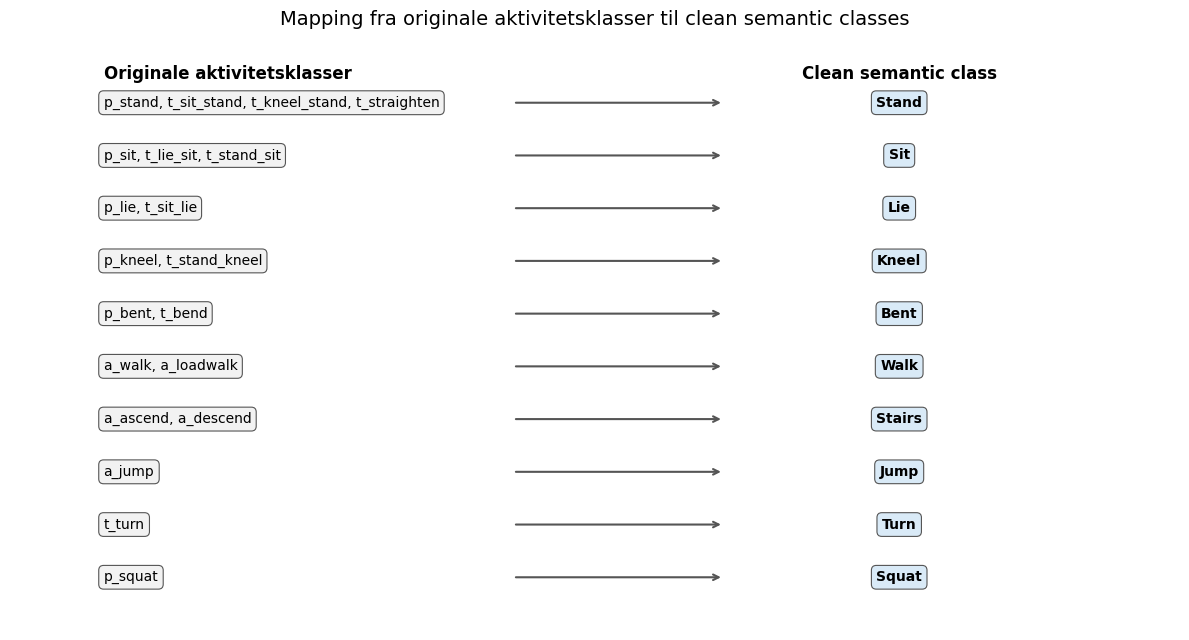

In [ ]:
import matplotlib.pyplot as plt

# Mapping til clean semantic classes


groups = {
    "Stand": ["p_stand", "t_sit_stand", "t_kneel_stand", "t_straighten"],
    "Sit": ["p_sit", "t_lie_sit", "t_stand_sit"],
    "Lie": ["p_lie", "t_sit_lie"],
    "Kneel": ["p_kneel", "t_stand_kneel"],
    "Bent": ["p_bent", "t_bend"],
    "Walk": ["a_walk", "a_loadwalk"],
    "Stairs": ["a_ascend", "a_descend"],
    "Jump": ["a_jump"],
    "Turn": ["t_turn"],
    "Squat": ["p_squat"]
}


plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

n = len(groups)
fig_height = max(6, n * 0.65)

fig, ax = plt.subplots(figsize=(12, fig_height))
ax.set_xlim(0, 1)
ax.set_ylim(0, n + 1)
ax.axis("off")

# Kolonneposisjoner
x_left = 0.08
x_arrow_start = 0.43
x_arrow_end = 0.61
x_right = 0.76

# Overskrifter
ax.text(
    x_left, n + 0.55,
    "Originale aktivitetsklasser",
    ha="left",
    va="center",
    fontsize=12,
    fontweight="bold"
)

ax.text(
    x_right, n + 0.55,
    "Clean semantic class",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

# Tegn rader
for i, (clean_class, original_classes) in enumerate(groups.items()):
    y = n - i

    original_text = ", ".join(original_classes)

    # Originalklasser
    ax.text(
        x_left, y,
        original_text,
        ha="left",
        va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#f2f2f2",
            edgecolor="#555555",
            linewidth=0.8
        )
    )

    # Pil
    ax.annotate(
        "",
        xy=(x_arrow_end, y),
        xytext=(x_arrow_start, y),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5,
            color="#555555"
        )
    )

    # Clean class
    ax.text(
        x_right, y,
        clean_class,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#d9eaf7",
            edgecolor="#555555",
            linewidth=0.8
        )
    )

plt.title(
    "Mapping fra originale aktivitetsklasser til clean semantic classes",
    pad=18
)

plt.tight_layout()
plt.show()

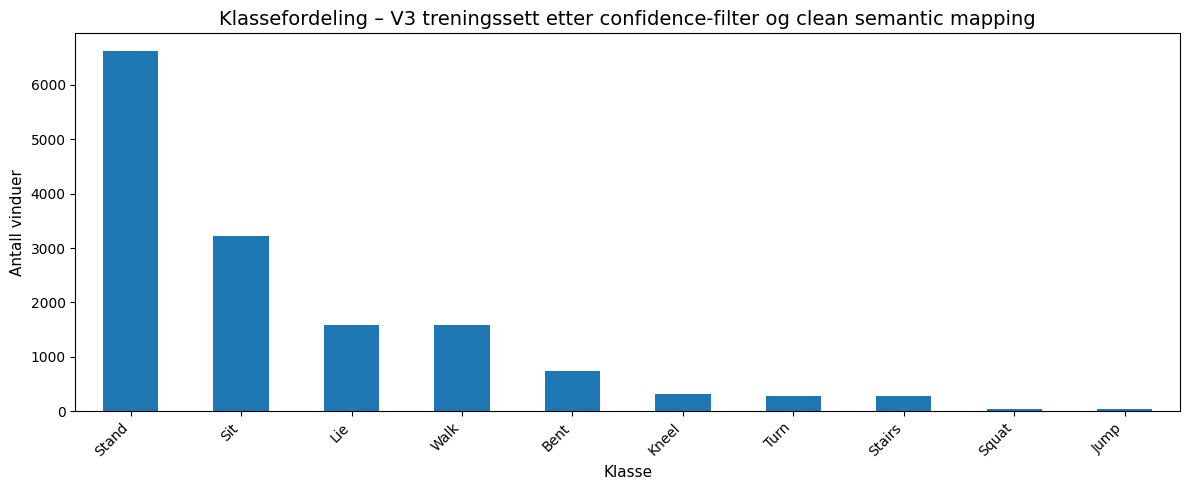

In [ ]:
# Klassefordeling etter V3 confidence-filter og clean semantic classes

CONF_THRESHOLD = 0.6

y_train_v3_clean_full = map_activity_to_clean_class(y_train_v3)

valid_mask = y_train_v3_clean_full.notna()
highconf_mask = conf_train_v3 > CONF_THRESHOLD

final_mask = valid_mask & highconf_mask

train_class_dist_v3_clean = (
    y_train_v3_clean_full[final_mask]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,5))
train_class_dist_v3_clean.plot(kind="bar")

plt.title("Klassefordeling – V3 treningssett etter confidence-filter og clean semantic mapping")
plt.ylabel("Antall vinduer")
plt.xlabel("Klasse")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

,mean,median,count
label,,,
Turn,0.740912,0.740,285
Squat,0.765870,0.755,46
Walk,0.788079,0.790,1581
Jump,0.819318,0.830,44
Kneel,0.834452,0.840,310
Bent,0.835783,0.840,743
Stairs,0.841642,0.860,272
Lie,0.857729,0.870,1588
Stand,0.885803,0.900,6616


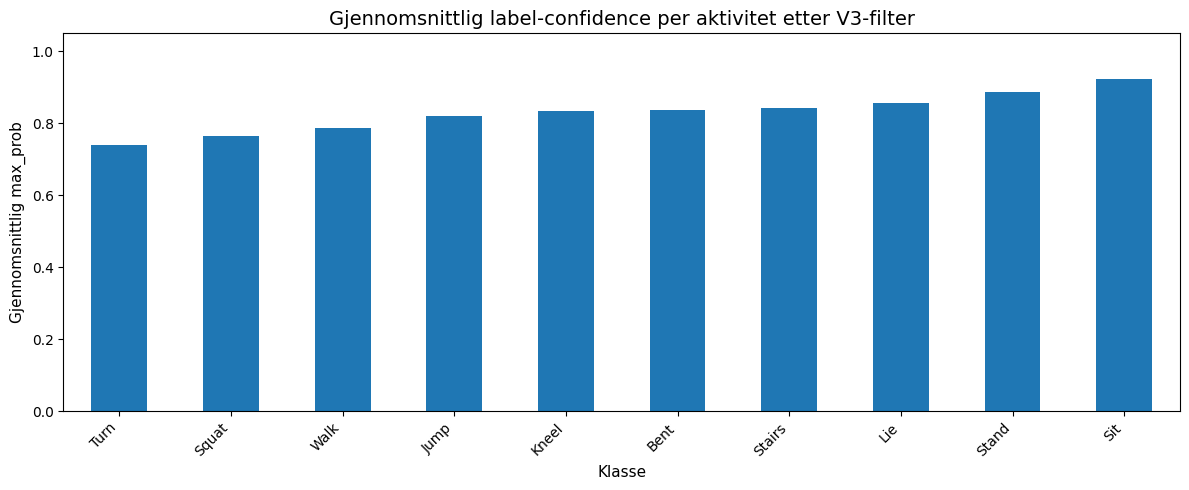

In [ ]:
# Gjennomsnittlig label-confidence per aktivitet etter V3-filter og clean semantic classes

CONF_THRESHOLD = 0.6

y_train_v3_clean_full = map_activity_to_clean_class(y_train_v3)

valid_mask = y_train_v3_clean_full.notna()
highconf_mask = conf_train_v3 > CONF_THRESHOLD

final_mask = valid_mask & highconf_mask

conf_v3_clean_df = pd.DataFrame({
    "label": y_train_v3_clean_full[final_mask],
    "confidence": conf_train_v3[final_mask]
})

conf_by_class_v3_clean = (
    conf_v3_clean_df
    .groupby("label")["confidence"]
    .agg(["mean", "median", "count"])
    .sort_values("mean")
)

display(conf_by_class_v3_clean.head(10))

plt.figure(figsize=(12,5))
conf_by_class_v3_clean["mean"].plot(kind="bar")

plt.title("Gjennomsnittlig label-confidence per aktivitet etter V3-filter")
plt.ylabel("Gjennomsnittlig max_prob")
plt.xlabel("Klasse")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

##V3 Preprocessing

In [ ]:
# ============================================================
# V3 PREPROCESSING: temporal features + clean classes + conf > 0.6
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

SUBSAMPLE_SIZE_V3 = 1_250_000
CONFIDENCE_THRESHOLD_CLEAN = 0.6

preprocessed_path = os.path.join(V3_DIR, "v3_preprocessed_clean_classes_conf06.pkl")

def add_temporal_features_by_sequence(X, meta, lags=[1, 2, 3], leads=[1]):
    X = X.copy().reset_index(drop=True)
    meta = meta.reset_index(drop=True)

    temporal_cols = [
        c for c in X.columns
        if (
            c.startswith(("x_", "y_", "z_"))
            or c.startswith("energy_")
            or c.startswith("magnitude_")
            or c.startswith("motion_ratio")
        )
    ]

    output_parts = []

    for seq in meta["seq_id"].unique():
        idx = meta.index[meta["seq_id"] == seq]
        seq_df = X.loc[idx].copy()

        new_cols = []

        for lag in lags:
            shifted = seq_df[temporal_cols].shift(lag)
            shifted.columns = [f"{col}_lag{lag}" for col in shifted.columns]
            new_cols.append(shifted)

        for lead in leads:
            shifted = seq_df[temporal_cols].shift(-lead)
            shifted.columns = [f"{col}_lead{lead}" for col in shifted.columns]
            new_cols.append(shifted)

        seq_df = pd.concat([seq_df] + new_cols, axis=1)
        seq_df = seq_df.bfill().ffill()

        output_parts.append(seq_df)

    return pd.concat(output_parts).sort_index().reset_index(drop=True)


if os.path.exists(preprocessed_path):
    print("Laster cached clean preprocessing")
    (
        X_train_v3_imp,
        X_test_v3_imp,
        X_train_v3_sub,
        y_train_v3_sub,
        conf_train_v3_sub,
        y_train_v3_merged_sub,
        y_test_v3_merged,
        y_train_v3_clean_sub,
        X_test_v3_clean,
        y_test_v3_clean
    ) = joblib.load(preprocessed_path)

else:
    print("Imputer v3 datasett")

    imputer_v3 = SimpleImputer(strategy="median")

    X_train_v3_imp = pd.DataFrame(
        imputer_v3.fit_transform(X_train_v3),
        columns=X_train_v3.columns
    )

    X_test_v3_imp = pd.DataFrame(
        imputer_v3.transform(X_test_v3),
        columns=X_test_v3.columns
    )

    print("NaNs etter imputering train:", X_train_v3_imp.isna().sum().sum())
    print("NaNs etter imputering test :", X_test_v3_imp.isna().sum().sum())

    print("Legger til temporal features")
    X_train_v3_imp = add_temporal_features_by_sequence(X_train_v3_imp, meta_train_v3)
    X_test_v3_imp = add_temporal_features_by_sequence(X_test_v3_imp, meta_test_v3)

    print("Ny train shape:", X_train_v3_imp.shape)
    print("Ny test shape :", X_test_v3_imp.shape)

    # Confidence-filter på trening
    clean_conf_mask = conf_train_v3 > CONFIDENCE_THRESHOLD_CLEAN

    X_train_high = X_train_v3_imp.loc[clean_conf_mask].reset_index(drop=True)
    y_train_high = y_train_v3.loc[clean_conf_mask].reset_index(drop=True)
    conf_train_high = conf_train_v3.loc[clean_conf_mask].reset_index(drop=True)

    print("Før confidence-filter:", len(X_train_v3_imp))
    print("Etter confidence-filter > 0.6:", len(X_train_high))

    if len(X_train_high) > SUBSAMPLE_SIZE_V3:
        X_train_v3_sub, _, y_train_v3_sub, _, conf_train_v3_sub, _ = train_test_split(
            X_train_high,
            y_train_high,
            conf_train_high,
            train_size=SUBSAMPLE_SIZE_V3,
            stratify=y_train_high,
            random_state=42
        )
    else:
        X_train_v3_sub = X_train_high
        y_train_v3_sub = y_train_high
        conf_train_v3_sub = conf_train_high

    X_train_v3_sub = X_train_v3_sub.reset_index(drop=True)
    y_train_v3_sub = y_train_v3_sub.reset_index(drop=True)
    conf_train_v3_sub = conf_train_v3_sub.reset_index(drop=True)

    y_train_v3_merged_sub = merge_transition_classes_series(y_train_v3_sub)
    y_test_v3_merged = merge_transition_classes_series(y_test_v3)

    # Clean semantic labels
    y_train_v3_clean_sub = map_activity_to_clean_class(y_train_v3_sub)
    y_test_v3_clean = map_activity_to_clean_class(y_test_v3)

    valid_train_mask = y_train_v3_clean_sub.notna()

    X_train_v3_sub = X_train_v3_sub.loc[valid_train_mask].reset_index(drop=True)
    y_train_v3_sub = y_train_v3_sub.loc[valid_train_mask].reset_index(drop=True)
    conf_train_v3_sub = conf_train_v3_sub.loc[valid_train_mask].reset_index(drop=True)
    y_train_v3_merged_sub = y_train_v3_merged_sub.loc[valid_train_mask].reset_index(drop=True)
    y_train_v3_clean_sub = y_train_v3_clean_sub.loc[valid_train_mask].reset_index(drop=True)

    valid_test_mask_clean = y_test_v3_clean.notna()

    X_test_v3_clean = X_test_v3_imp.loc[valid_test_mask_clean].reset_index(drop=True)
    y_test_v3_clean = y_test_v3_clean.loc[valid_test_mask_clean].reset_index(drop=True)

    print("\nClean train labels:")
    print(y_train_v3_clean_sub.value_counts())

    print("\nClean test labels:")
    print(y_test_v3_clean.value_counts())

    joblib.dump(
        (
            X_train_v3_imp,
            X_test_v3_imp,
            X_train_v3_sub,
            y_train_v3_sub,
            conf_train_v3_sub,
            y_train_v3_merged_sub,
            y_test_v3_merged,
            y_train_v3_clean_sub,
            X_test_v3_clean,
            y_test_v3_clean
        ),
        preprocessed_path
    )

print("V3 training size:", X_train_v3_sub.shape)
print("Original labels:", y_train_v3_sub.nunique())
print("Merged labels:", y_train_v3_merged_sub.nunique())
print("Clean labels:", y_train_v3_clean_sub.nunique())

Laster cached clean preprocessing
V3 training size: (14713, 229)
Original labels: 20
Merged labels: 12
Clean labels: 10


##V3 Modeller

In [ ]:
# ============================================================
# V3 MODELLER: Alle modeller, ikke 1d-cnn
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.base import clone
import numpy as np
import pandas as pd
import joblib
import os

MODEL_V3_DIR = os.path.join(V3_DIR, "models")
PRED_V3_DIR = os.path.join(V3_DIR, "predictions")
RESULT_V3_DIR = os.path.join(V3_DIR, "results")

for d in [MODEL_V3_DIR, PRED_V3_DIR, RESULT_V3_DIR]:
    os.makedirs(d, exist_ok=True)

v3_models = {
    "Dummy v3": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression v3": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            C=3.0,
            solver="saga",
            class_weight=None,
            n_jobs=-1,
            random_state=42
        ))
    ]),

    "Random Forest v3": RandomForestClassifier(
        n_estimators=800,
        max_depth=35,
        min_samples_split=10,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight=None,
        n_jobs=-1,
        random_state=42,
        bootstrap=True,
        verbose=1
    ),

    "Gradient Boosting v3": HistGradientBoostingClassifier(
        max_iter=1000,
        learning_rate=0.025,
        max_leaf_nodes=63,
        min_samples_leaf=30,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=30,
        random_state=42,
        verbose=1
    ),

    "Linear SVM v3": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            C=0.75,
            class_weight=None,
            max_iter=10000,
            dual="auto",
            random_state=42
        ))
    ])
}
print("ok")

ok


In [ ]:
# V3 TRENING: original, merged og clean

def fit_model_with_optional_weights(model, X, y, sample_weights):
    if isinstance(model, Pipeline):
        last_step_name = model.steps[-1][0]
        try:
            model.fit(X, y, **{f"{last_step_name}__sample_weight": sample_weights})
        except (TypeError, ValueError):
            model.fit(X, y)
    else:
        try:
            model.fit(X, y, sample_weight=sample_weights)
        except (TypeError, ValueError):
            model.fit(X, y)

    return model


def train_v3_model_set(models, X, y, confidence, experiment_suffix):
    trained = {}

    class_weights = compute_sample_weight(
        class_weight="balanced",
        y=y
    )

    sample_weights = class_weights * (confidence.values ** 2)

    for name, model in models.items():
        safe_name = name.replace(" ", "_")
        model_path = os.path.join(
            MODEL_V3_DIR,
            f"{safe_name}_{experiment_suffix}.pkl"
        )

        if os.path.exists(model_path):
            print(f"Laster {name} ({experiment_suffix}) fra cache")
            trained_model = joblib.load(model_path)

        else:
            print(f"Trener {name} ({experiment_suffix})")

            trained_model = clone(model)
            trained_model = fit_model_with_optional_weights(
                trained_model,
                X,
                y,
                sample_weights
            )

            joblib.dump(trained_model, model_path)

        trained[name] = trained_model

    return trained


trained_models_v3_original = train_v3_model_set(
    v3_models,
    X_train_v3_sub,
    y_train_v3_sub,
    conf_train_v3_sub,
    "original_conf_weighted"
)

trained_models_v3_merged = train_v3_model_set(
    v3_models,
    X_train_v3_sub,
    y_train_v3_merged_sub,
    conf_train_v3_sub,
    "merged_conf_weighted"
)

trained_models_v3_clean = train_v3_model_set(
    v3_models,
    X_train_v3_sub,
    y_train_v3_clean_sub,
    conf_train_v3_sub,
    "clean_conf06_conf_weighted"
)

print("trening ok")

Laster Dummy v3 (original_conf_weighted) fra cache
Laster Logistic Regression v3 (original_conf_weighted) fra cache
Laster Random Forest v3 (original_conf_weighted) fra cache
Laster Gradient Boosting v3 (original_conf_weighted) fra cache
Laster Linear SVM v3 (original_conf_weighted) fra cache
Laster Dummy v3 (merged_conf_weighted) fra cache
Laster Logistic Regression v3 (merged_conf_weighted) fra cache
Laster Random Forest v3 (merged_conf_weighted) fra cache
Laster Gradient Boosting v3 (merged_conf_weighted) fra cache
Laster Linear SVM v3 (merged_conf_weighted) fra cache
Laster Dummy v3 (clean_conf06_conf_weighted) fra cache
Laster Logistic Regression v3 (clean_conf06_conf_weighted) fra cache
Laster Random Forest v3 (clean_conf06_conf_weighted) fra cache
Laster Gradient Boosting v3 (clean_conf06_conf_weighted) fra cache
Laster Linear SVM v3 (clean_conf06_conf_weighted) fra cache
trening ok


In [ ]:

# V3 PREDIKSJONER:

def predict_v3_model_set(models_dict, X_test_data, prediction_suffix):
    predictions = {}

    for name, model in models_dict.items():
        safe_name = name.replace(" ", "_")

        pred_path = os.path.join(
            PRED_V3_DIR,
            f"{safe_name}_{prediction_suffix}_preds.pkl"
        )

        if os.path.exists(pred_path):
            print(f"Laster prediksjoner: {name} ({prediction_suffix})")
            preds = joblib.load(pred_path)

        else:
            print(f"Predikerer: {name} ({prediction_suffix})")
            preds = model.predict(X_test_data)
            joblib.dump(preds, pred_path)

        predictions[name] = preds

    return predictions


predictions_v3_original = predict_v3_model_set(
    trained_models_v3_original,
    X_test_v3_imp,
    "original_conf_weighted"
)

predictions_v3_merged = predict_v3_model_set(
    trained_models_v3_merged,
    X_test_v3_imp,
    "merged_conf_weighted"
)

predictions_v3_clean = predict_v3_model_set(
    trained_models_v3_clean,
    X_test_v3_clean,
    "clean_conf06_conf_weighted"
)

print("Alle V3-prediksjoner klare")

Laster prediksjoner: Dummy v3 (original_conf_weighted)
Laster prediksjoner: Logistic Regression v3 (original_conf_weighted)
Laster prediksjoner: Random Forest v3 (original_conf_weighted)
Laster prediksjoner: Gradient Boosting v3 (original_conf_weighted)
Laster prediksjoner: Linear SVM v3 (original_conf_weighted)
Laster prediksjoner: Dummy v3 (merged_conf_weighted)
Laster prediksjoner: Logistic Regression v3 (merged_conf_weighted)
Laster prediksjoner: Random Forest v3 (merged_conf_weighted)
Laster prediksjoner: Gradient Boosting v3 (merged_conf_weighted)
Laster prediksjoner: Linear SVM v3 (merged_conf_weighted)
Laster prediksjoner: Dummy v3 (clean_conf06_conf_weighted)
Laster prediksjoner: Logistic Regression v3 (clean_conf06_conf_weighted)
Laster prediksjoner: Random Forest v3 (clean_conf06_conf_weighted)
Laster prediksjoner: Gradient Boosting v3 (clean_conf06_conf_weighted)
Laster prediksjoner: Linear SVM v3 (clean_conf06_conf_weighted)
Alle V3-prediksjoner klare


In [ ]:
# ============================================================
# TEMPORAL SMOOTHING
# ============================================================

def smooth_labels_by_sequence(preds, meta, window=5):
    preds = pd.Series(preds).reset_index(drop=True)
    meta = meta.reset_index(drop=True)

    smoothed = preds.copy()

    for seq in meta["seq_id"].unique():
        idx = meta.index[meta["seq_id"] == seq].tolist()
        seq_preds = preds.iloc[idx].reset_index(drop=True)

        seq_smoothed = []

        half = window // 2

        for i in range(len(seq_preds)):
            start = max(0, i - half)
            end = min(len(seq_preds), i + half + 1)
            seq_smoothed.append(seq_preds.iloc[start:end].mode().iloc[0])

        smoothed.iloc[idx] = seq_smoothed

    return smoothed.values


SMOOTH_WINDOWS = [3, 5, 9]

smoothed_predictions_v3_original = {}
smoothed_predictions_v3_merged = {}

for window in SMOOTH_WINDOWS:
    for name, preds in predictions_v3_original.items():
        key = f"{name} smooth{window}"
        smoothed_predictions_v3_original[key] = smooth_labels_by_sequence(
            preds,
            meta_test_v3,
            window=window
        )

    for name, preds in predictions_v3_merged.items():
        key = f"{name} smooth{window}"
        smoothed_predictions_v3_merged[key] = smooth_labels_by_sequence(
            preds,
            meta_test_v3,
            window=window
        )

print("Smoothing ferdig")

Smoothing ferdig


In [ ]:

# HIGH-CONFIDENCE TESTSETT FOR CLEAN CLASSES

conf_test_mask = conf_test_v3 > 0.6

y_test_v3_clean_full = map_activity_to_clean_class(y_test_v3)

valid_highconf_mask = conf_test_mask & y_test_v3_clean_full.notna()

X_test_v3_highconf = X_test_v3_imp.loc[valid_highconf_mask].reset_index(drop=True)
y_test_v3_clean_highconf = y_test_v3_clean_full.loc[valid_highconf_mask].reset_index(drop=True)

print("High confidence samples:", len(X_test_v3_highconf))
print("Original test samples:", len(X_test_v3_imp))

print("\nFeature match:")
print("Train features:", X_train_v3_sub.shape[1])
print("Highconf test features:", X_test_v3_highconf.shape[1])

print("\nLabel distribution:")
print(y_test_v3_clean_highconf.value_counts())

High confidence samples: 15029
Original test samples: 16583

Feature match:
Train features: 229
Highconf test features: 229

Label distribution:
label
Stand     6898
Sit       3060
Lie       1548
Walk      1489
Bent       795
Turn       471
Kneel      422
Stairs     312
Jump        31
Squat        3
Name: count, dtype: int64


# V3-resultater

## Ytelse

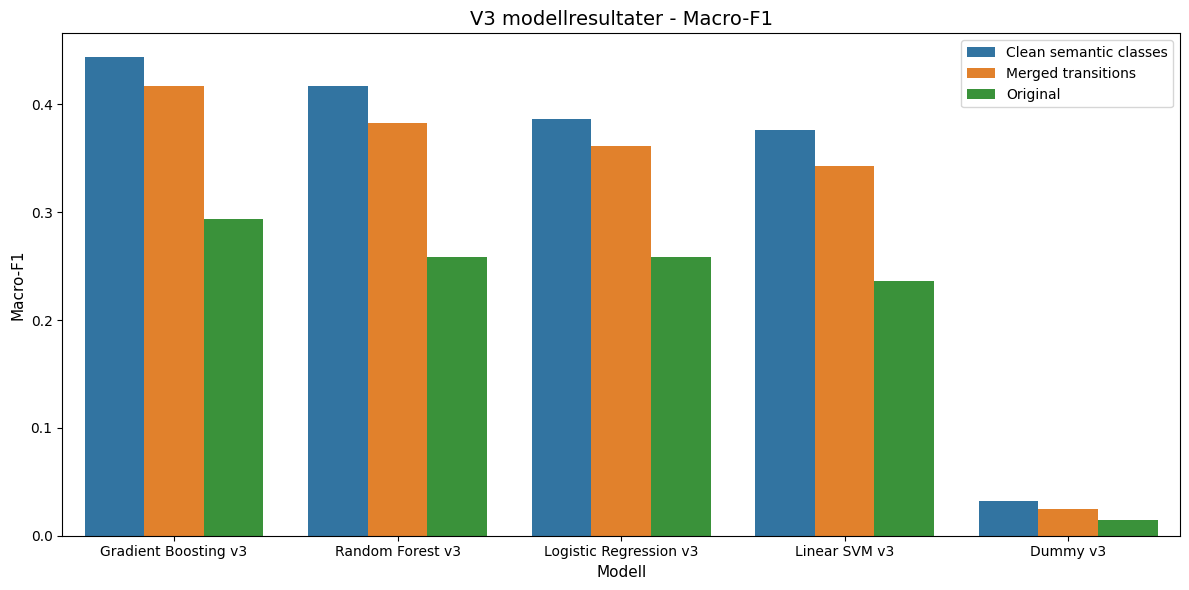

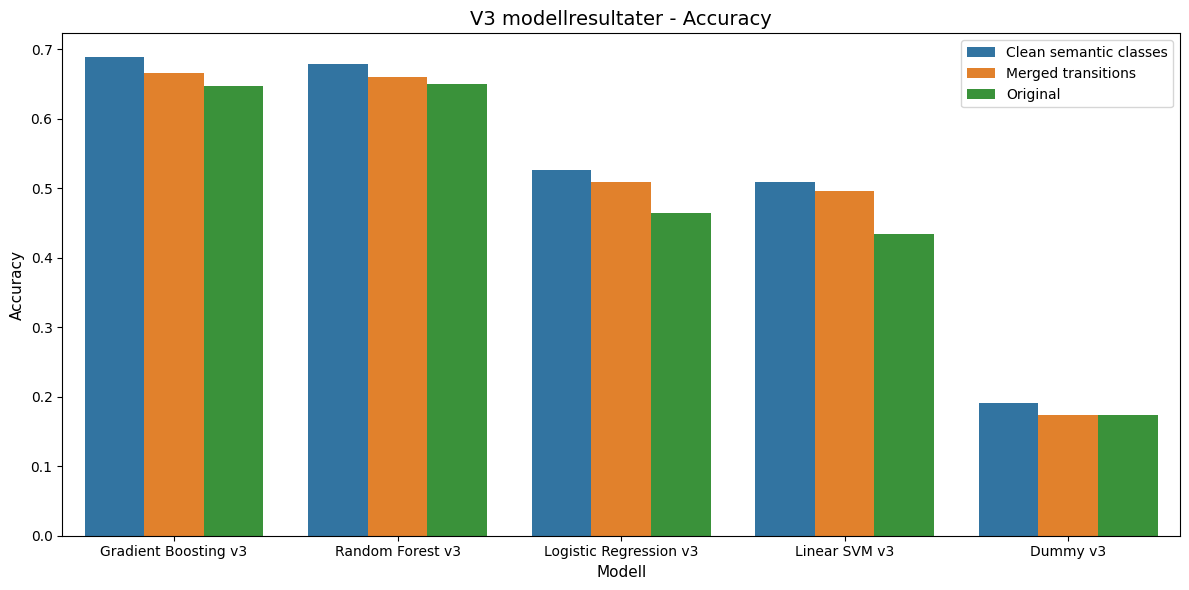

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.3s
[Parallel(n_jobs=12)]: Done 800 out of 800 | elapsed:    0.4s finished


,Experiment,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
3,High Confidence,Gradient Boosting v3,0.729989,0.489410,0.712471,0.527899,0.508061
2,High Confidence,Random Forest v3,0.720740,0.464172,0.695426,0.664801,0.450724
1,High Confidence,Logistic Regression v3,0.552532,0.417507,0.580118,0.389825,0.523865
4,High Confidence,Linear SVM v3,0.533702,0.401456,0.559174,0.374238,0.517624
0,High Confidence,Dummy v3,0.203606,0.033833,0.068886,0.020361,0.100000


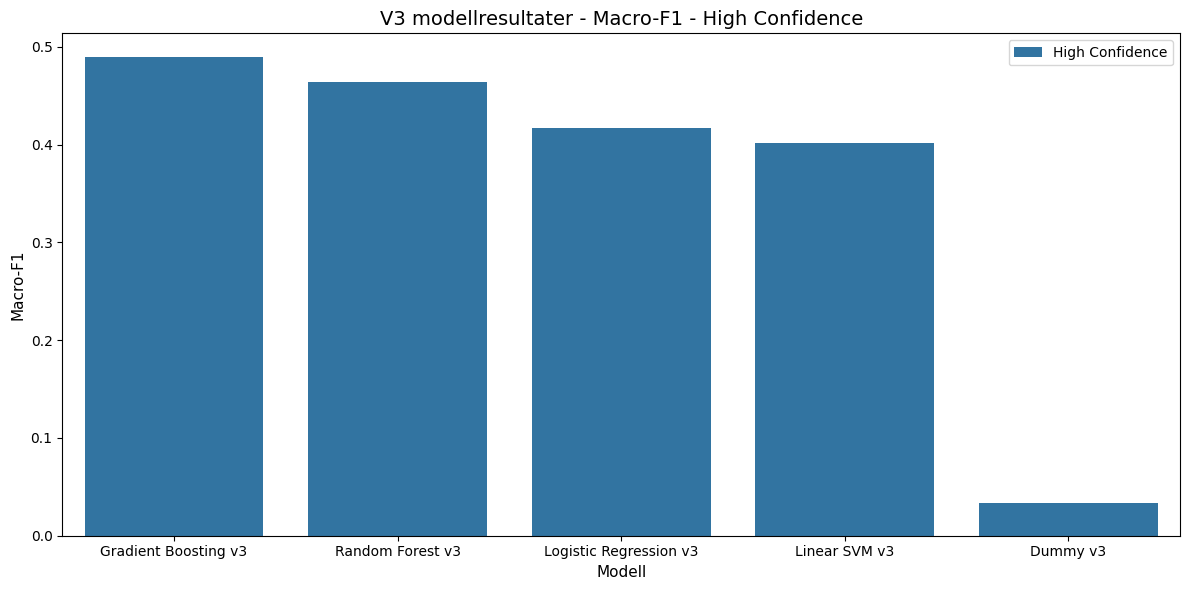

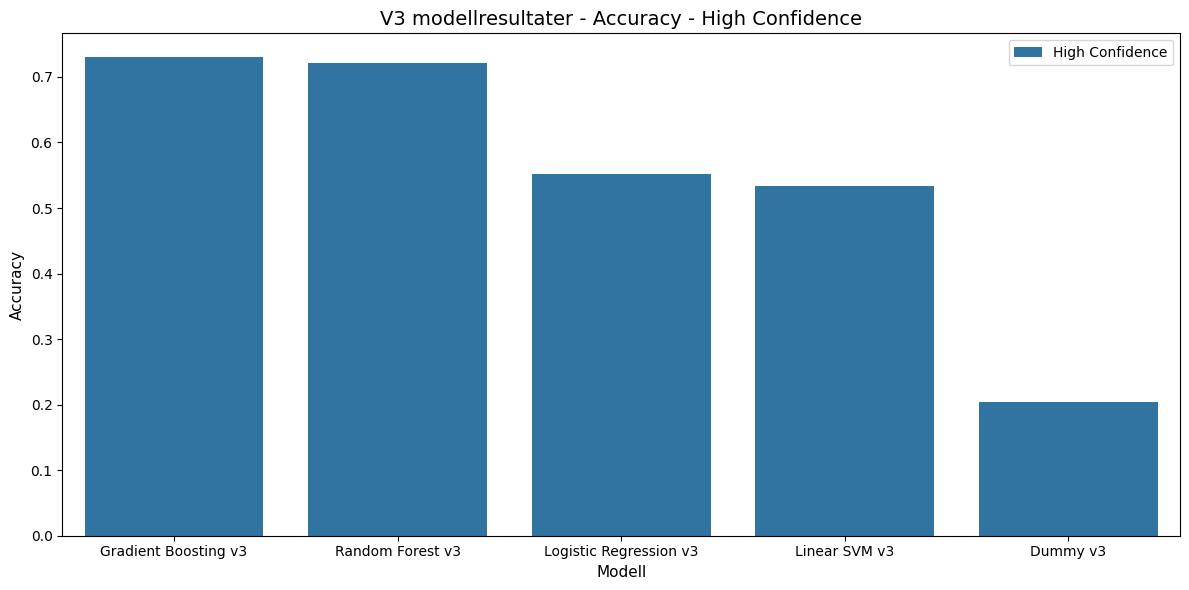

In [ ]:
# ============================================================
# V3 EVALUERING: original + merged + smoothing
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import joblib
import os
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def evaluate_predictions(y_true, predictions_dict, experiment_name):
    rows = []

    for name, preds in predictions_dict.items():
        rows.append({
            "Experiment": experiment_name,
            "Model": name,
            "Accuracy": accuracy_score(y_true, preds),
            "Macro_F1": f1_score(y_true, preds, average="macro", zero_division=0),
            "Weighted_F1": f1_score(y_true, preds, average="weighted", zero_division=0),
            "Macro_Precision": precision_score(y_true, preds, average="macro", zero_division=0),
            "Macro_Recall": recall_score(y_true, preds, average="macro", zero_division=0)
        })

    return pd.DataFrame(rows)


eval_original = evaluate_predictions(
    y_test_v3,
    predictions_v3_original,
    "Original"
)

eval_merged = evaluate_predictions(
    y_test_v3_merged,
    predictions_v3_merged,
    "Merged transitions"
)

eval_clean = evaluate_predictions(
    y_test_v3_clean,
    predictions_v3_clean,
    "Clean semantic classes"
)

performance_v3_all = pd.concat(
    [
        eval_original,
        eval_merged,
        eval_clean
    ],
    ignore_index=True
).sort_values(
    ["Macro_F1", "Accuracy"],
    ascending=False
)

joblib.dump(
    performance_v3_all,
    os.path.join(RESULT_V3_DIR, "performance_v3_all.pkl")
)

# ============================================================
# PLOTS: ytelse
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_v3_all,
    x="Model",
    y="Macro_F1",
    hue="Experiment"
)

plt.title("V3 modellresultater - Macro-F1")
plt.xlabel("Modell")
plt.ylabel("Macro-F1")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_v3_all,
    x="Model",
    y="Accuracy",
    hue="Experiment"
)

plt.title("V3 modellresultater - Accuracy")
plt.xlabel("Modell")
plt.ylabel("Accuracy")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#Ny plot med bare high-confidence resultater
highconf_rows = []

for model_name, model in trained_models_v3_clean.items():

    preds_highconf = model.predict(X_test_v3_highconf)

    highconf_rows.append({
        "Experiment": "High Confidence",
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_v3_clean_highconf, preds_highconf),
        "Macro_F1": f1_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_test_v3_clean_highconf, preds_highconf, average="weighted", zero_division=0),
        "Macro_Precision": precision_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0)
    })

performance_v3_highconf = pd.DataFrame(highconf_rows).sort_values(
    ["Macro_F1", "Accuracy"],
    ascending=False
)

display(performance_v3_highconf)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_v3_highconf,
    x="Model",
    y="Macro_F1",
    hue="Experiment"
)

plt.title("V3 modellresultater - Macro-F1 - High Confidence")
plt.xlabel("Modell")
plt.ylabel("Macro-F1")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_v3_highconf,
    x="Model",
    y="Accuracy",
    hue="Experiment"
)

plt.title("V3 modellresultater - Accuracy - High Confidence")
plt.xlabel("Modell")
plt.ylabel("Accuracy")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# V3 EVALUERING: original + merged + smoothing
# ============================================================

def evaluate_predictions(y_true, predictions_dict, experiment_name):
    rows = []

    for name, preds in predictions_dict.items():
        rows.append({
            "Experiment": experiment_name,
            "Model": name,
            "Accuracy": accuracy_score(y_true, preds),
            "Macro_F1": f1_score(y_true, preds, average="macro", zero_division=0),
            "Weighted_F1": f1_score(y_true, preds, average="weighted", zero_division=0),
            "Macro_Precision": precision_score(y_true, preds, average="macro", zero_division=0),
            "Macro_Recall": recall_score(y_true, preds, average="macro", zero_division=0)
        })

    return pd.DataFrame(rows)


eval_original = evaluate_predictions(
    y_test_v3,
    predictions_v3_original,
    "Original"
)

eval_merged = evaluate_predictions(
    y_test_v3_merged,
    predictions_v3_merged,
    "Merged transitions"
)

eval_clean = evaluate_predictions(
    y_test_v3_clean,
    predictions_v3_clean,
    "Clean semantic classes"
)

performance_v3_all = pd.concat(
    [
        eval_original,
        eval_merged,
        eval_clean
    ],
    ignore_index=True
).sort_values(
    ["Macro_F1", "Accuracy"],
    ascending=False
)

joblib.dump(
    performance_v3_all,
    os.path.join(RESULT_V3_DIR, "performance_v3_all.pkl")
)

display(performance_v3_all)

,Experiment,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
13,Clean semantic classes,Gradient Boosting v3,0.688778,0.443636,0.661128,0.505148,0.468206
12,Clean semantic classes,Random Forest v3,0.678888,0.416901,0.641197,0.638859,0.415671
8,Merged transitions,Gradient Boosting v3,0.665923,0.416810,0.640032,0.482599,0.432659
11,Clean semantic classes,Logistic Regression v3,0.526262,0.386412,0.548308,0.377453,0.473804
7,Merged transitions,Random Forest v3,0.660074,0.382278,0.615321,0.539319,0.376297
14,Clean semantic classes,Linear SVM v3,0.509558,0.376335,0.531186,0.364815,0.468265
6,Merged transitions,Logistic Regression v3,0.509256,0.361039,0.525925,0.348215,0.452314
9,Merged transitions,Linear SVM v3,0.496110,0.342523,0.511881,0.327921,0.443549
3,Original,Gradient Boosting v3,0.647832,0.293874,0.622304,0.324162,0.311322
2,Original,Random Forest v3,0.650847,0.258887,0.601052,0.431579,0.247042


In [ ]:
# ============================================================
# BESTE MODELL
# ============================================================

best_row = performance_v3_all.iloc[0]

print("BESTE V3 RESULTAT:")
print(best_row)

best_model_name = best_row["Model"]
best_experiment = best_row["Experiment"]

print("\nBeste modell:", best_model_name)
print("Beste eksperiment:", best_experiment)

if best_experiment == "Original":
    y_true_best = y_test_v3
    preds_best = predictions_v3_original[best_model_name]

elif best_experiment == "Merged transitions":
    y_true_best = y_test_v3_merged
    preds_best = predictions_v3_merged[best_model_name]

elif best_experiment == "Clean semantic classes":
    y_true_best = y_test_v3_clean
    preds_best = predictions_v3_clean[best_model_name]

print("\nClassification report for beste modell:")
print(classification_report(y_true_best, preds_best, zero_division=0))

report_best_v3 = classification_report(
    y_true_best,
    preds_best,
    output_dict=True,
    zero_division=0
)

joblib.dump(
    report_best_v3,
    os.path.join(RESULT_V3_DIR, "best_classification_report_v3_all.pkl")
)

BESTE V3 RESULTAT:
Experiment         Clean semantic classes
Model                Gradient Boosting v3
Accuracy                         0.688778
Macro_F1                         0.443636
Weighted_F1                      0.661128
Macro_Precision                  0.505148
Macro_Recall                     0.468206
Name: 13, dtype: object

Beste modell: Gradient Boosting v3
Beste eksperiment: Clean semantic classes

Classification report for beste modell:
              precision    recall  f1-score   support

        Bent       0.56      0.40      0.47       851
        Jump       0.44      0.90      0.59        31
       Kneel       0.54      0.16      0.24       445
         Lie       0.74      0.75      0.75      1575
         Sit       0.72      0.85      0.78      3165
       Squat       0.00      0.00      0.00        24
      Stairs       0.75      0.18      0.29      1068
       Stand       0.74      0.82      0.78      7098
        Turn       0.09      0.01      0.01       559
   

['/content/drive/MyDrive/DAT191_H3_project_shared/v3_5s_stride1/results/best_classification_report_v3_all.pkl']

In [ ]:
# EVALUER BESTE GB-MODELL PÅ HIGH-CONFIDENCE TESTSETT

best_gb_model = trained_models_v3_clean["Gradient Boosting v3"]

y_pred_highconf = best_gb_model.predict(X_test_v3_highconf)

acc_highconf = accuracy_score(
    y_test_v3_clean_highconf,
    y_pred_highconf
)

macro_f1_highconf = f1_score(
    y_test_v3_clean_highconf,
    y_pred_highconf,
    average="macro"
)

weighted_f1_highconf = f1_score(
    y_test_v3_clean_highconf,
    y_pred_highconf,
    average="weighted"
)

print("HIGH-CONFIDENCE RESULTS")
print("-----------------------")
print("Accuracy:", acc_highconf)
print("Macro F1:", macro_f1_highconf)
print("Weighted F1:", weighted_f1_highconf)

print("\nClassification report:")
print(
    classification_report(
        y_test_v3_clean_highconf,
        y_pred_highconf
    )
)

HIGH-CONFIDENCE RESULTS
-----------------------
Accuracy: 0.729988688535498
Macro F1: 0.4894103779805081
Weighted F1: 0.7124712842481723

Classification report:
              precision    recall  f1-score   support

        Bent       0.59      0.43      0.49       795
        Jump       0.44      0.90      0.59        31
       Kneel       0.61      0.15      0.25       422
         Lie       0.77      0.76      0.77      1548
         Sit       0.73      0.85      0.79      3060
       Squat       0.00      0.00      0.00         3
      Stairs       0.77      0.56      0.65       312
       Stand       0.79      0.83      0.81      6898
        Turn       0.07      0.00      0.01       471
        Walk       0.50      0.60      0.55      1489

    accuracy                           0.73     15029
   macro avg       0.53      0.51      0.49     15029
weighted avg       0.71      0.73      0.71     15029



In [ ]:
# TEMPORAL SMOOTHING

from collections import Counter

def smooth_predictions(predictions, window_size=7):
    preds = np.array(predictions)

    smoothed = []

    half_window = window_size // 2

    for i in range(len(preds)):
        start = max(0, i - half_window)
        end = min(len(preds), i + half_window + 1)

        window = preds[start:end]

        most_common = Counter(window).most_common(1)[0][0]

        smoothed.append(most_common)

    return np.array(smoothed)

print("smoothing-funksjon klar")

smoothing-funksjon klar


In [ ]:
# CLEAN SEMANTIC CLASSES WITH SMOOTHING
#lite påvirkning kan skippe i rapport? evnt bare nevne at feature engineering allerede dekker mye av samme.

clean_smoothing_results = []
clean_smoothed_predictions = {}

for name, preds in predictions_v3_clean.items():
    for window_size in [3, 5, 7, 9]:
        smoothed_preds = smooth_predictions(preds, window_size=window_size)

        key = f"{name} smooth{window_size}"
        clean_smoothed_predictions[key] = smoothed_preds

        clean_smoothing_results.append({
            "Experiment": f"Clean semantic classes smooth{window_size}",
            "Model": name,
            "Accuracy": accuracy_score(y_test_v3_clean, smoothed_preds),
            "Macro_F1": f1_score(y_test_v3_clean, smoothed_preds, average="macro", zero_division=0),
            "Weighted_F1": f1_score(y_test_v3_clean, smoothed_preds, average="weighted", zero_division=0),
            "Macro_Precision": precision_score(y_test_v3_clean, smoothed_preds, average="macro", zero_division=0),
            "Macro_Recall": recall_score(y_test_v3_clean, smoothed_preds, average="macro", zero_division=0)
        })

clean_smoothing_df = pd.DataFrame(clean_smoothing_results).sort_values(
    ["Macro_F1", "Accuracy"],
    ascending=False
)

display(clean_smoothing_df)

,Experiment,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
12,Clean semantic classes smooth3,Gradient Boosting v3,0.692155,0.442772,0.663411,0.514272,0.468616
13,Clean semantic classes smooth5,Gradient Boosting v3,0.694265,0.435480,0.663575,0.541660,0.458548
14,Clean semantic classes smooth7,Gradient Boosting v3,0.691129,0.421791,0.658415,0.530822,0.444224
8,Clean semantic classes smooth3,Random Forest v3,0.679612,0.417068,0.641402,0.639897,0.418045
9,Clean semantic classes smooth5,Random Forest v3,0.679069,0.403078,0.639275,0.539625,0.400823
6,Clean semantic classes smooth7,Logistic Regression v3,0.543147,0.395271,0.560078,0.383365,0.481142
5,Clean semantic classes smooth5,Logistic Regression v3,0.537900,0.394985,0.556329,0.384248,0.482586
7,Clean semantic classes smooth9,Logistic Regression v3,0.542845,0.391217,0.558316,0.380301,0.476949
15,Clean semantic classes smooth9,Gradient Boosting v3,0.682446,0.389685,0.646735,0.472631,0.398275
4,Clean semantic classes smooth3,Logistic Regression v3,0.531810,0.389275,0.551985,0.379871,0.475618


###Per Klasse F-1

,Random Forest V3,Gradient Boosting V3,Logistic Regression V3,Linear SVM V3
Class,,,,
Bent,0.422,0.467,0.310,0.277
Jump,0.500,0.589,0.364,0.347
Kneel,0.236,0.241,0.310,0.313
Lie,0.737,0.747,0.646,0.628
Sit,0.759,0.782,0.693,0.674
Squat,0.000,0.000,0.000,0.000
Stairs,0.239,0.291,0.357,0.387
Stand,0.767,0.780,0.590,0.569
Turn,0.007,0.010,0.126,0.130


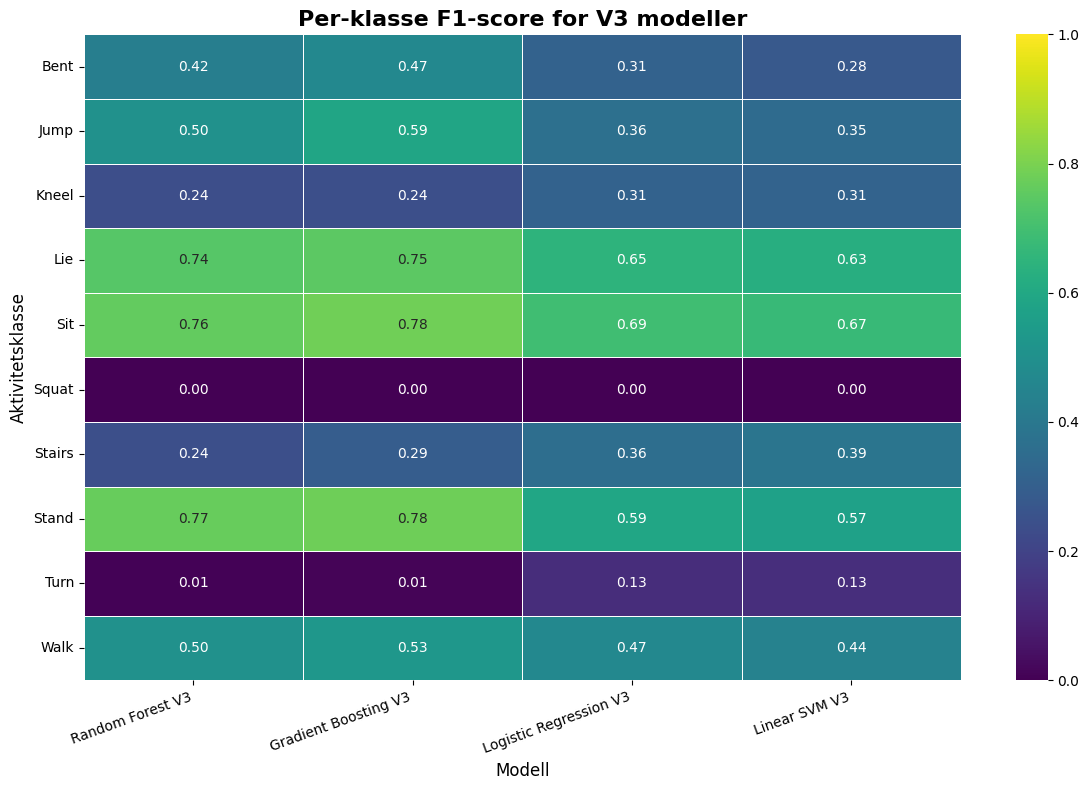

In [ ]:
# ============================================================
# PER-CLASS F1: V3 MODELS ONLY
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report

# ------------------------------------------------------------
# Lag reports direkte fra predictions
# ------------------------------------------------------------

rf_report = classification_report(
    y_test_v3_clean,
    predictions_v3_clean["Random Forest v3"],
    output_dict=True,
    zero_division=0
)

gb_report = classification_report(
    y_test_v3_clean,
    predictions_v3_clean["Gradient Boosting v3"],
    output_dict=True,
    zero_division=0
)

lr_report = classification_report(
    y_test_v3_clean,
    predictions_v3_clean["Logistic Regression v3"],
    output_dict=True,
    zero_division=0
)

svm_report = classification_report(
    y_test_v3_clean,
    predictions_v3_clean["Linear SVM v3"],
    output_dict=True,
    zero_division=0
)

# ------------------------------------------------------------
# Klasser
# ------------------------------------------------------------

classes = sorted(pd.Series(y_test_v3_clean).unique())

# ------------------------------------------------------------
# Bygg dataframe
# ------------------------------------------------------------

v3_per_class_df = pd.DataFrame({
    "Class": classes,

    "Random Forest V3":
        [rf_report[c]["f1-score"] for c in classes],

    "Gradient Boosting V3":
        [gb_report[c]["f1-score"] for c in classes],

    "Logistic Regression V3":
        [lr_report[c]["f1-score"] for c in classes],

    "Linear SVM V3":
        [svm_report[c]["f1-score"] for c in classes]
})

v3_per_class_df = v3_per_class_df.set_index("Class")

# ------------------------------------------------------------
# STYLED TABLE
# ------------------------------------------------------------

display(
    v3_per_class_df.style
    .format("{:.3f}")
    .background_gradient(cmap="viridis")
)

# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

sns.heatmap(
    v3_per_class_df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",

)

plt.title(
    "Per-klasse F1-score for V3 modeller",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Modell", fontsize=12)
plt.ylabel("Aktivitetsklasse", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

###Confusion Matrix

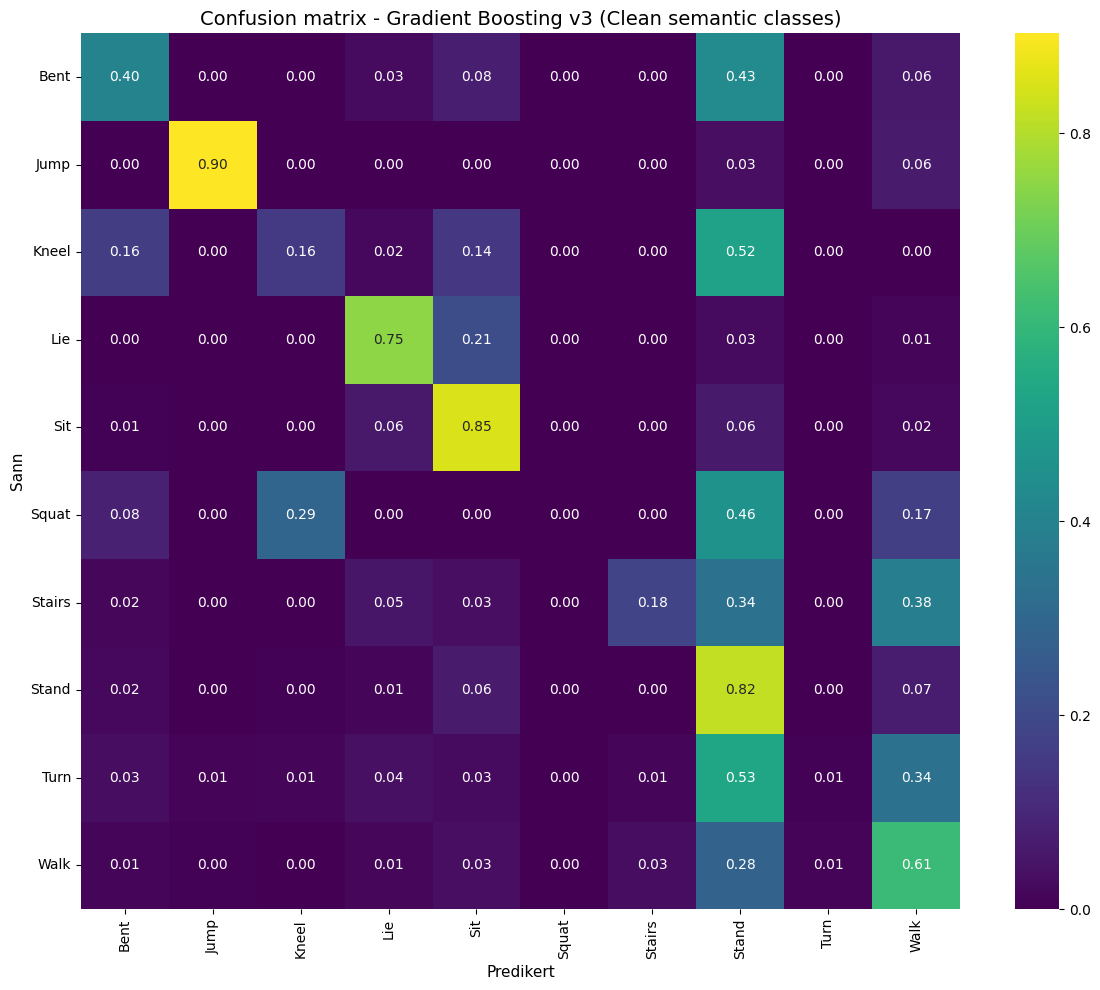

In [ ]:
# ============================================================
# CONFUSION MATRIX FOR BESTE V3-MODELL
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

labels_best = sorted(pd.Series(y_true_best).unique())

cm = confusion_matrix(
    y_true_best,
    preds_best,
    labels=labels_best
)

cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_norm,
    xticklabels=labels_best,
    yticklabels=labels_best,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title(f"Confusion matrix - {best_model_name} ({best_experiment})")
plt.xlabel("Predikert")
plt.ylabel("Sann")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##Forklarbarhet

### Permutation importance

Laster cached permutation importance


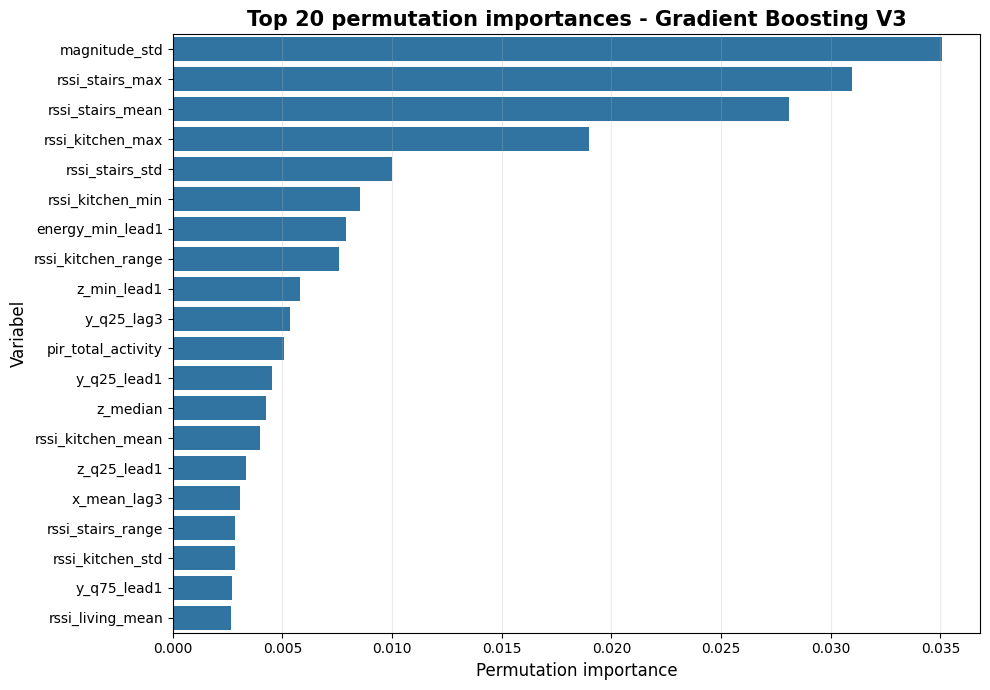

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
import joblib
import os

# ============================================================
# PERMUTATION IMPORTANCE: TOP FEATURES
# ============================================================

perm_cache = os.path.join(RESULT_V3_DIR, "perm_importance_cache.pkl")

if os.path.exists(perm_cache):
    print("Laster cached permutation importance")
    importance_df = joblib.load(perm_cache)
else:
    print("Kjører permutation importance...")
    best_model = trained_models_v3_clean["Gradient Boosting v3"]

    perm_importance = permutation_importance(
        best_model,
        X_test_v3_imp,
        y_test_v3_clean,
        n_repeats=5,
        random_state=42,
        scoring="f1_macro",
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test_v3_imp.columns,
        "Importance_Mean": perm_importance.importances_mean,
        "Importance_STD": perm_importance.importances_std
    }).sort_values("Importance_Mean", ascending=False)

    joblib.dump(importance_df, perm_cache)
    print("Cachet!")


top_features = importance_df.head(20).copy()

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance_Mean",
    y="Feature"
)

plt.title(
    "Top 20 permutation importances - Gradient Boosting V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Permutation importance", fontsize=12)
plt.ylabel("Variabel", fontsize=12)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### SHAP

Laster cached SHAP for V3
SHAP sample shape: (300, 229)
Antall klasser: 10
Klasser: ['Bent' 'Jump' 'Kneel' 'Lie' 'Sit' 'Squat' 'Stairs' 'Stand' 'Turn' 'Walk']


,Feature,Mean_abs_SHAP
83,rssi_stairs_max,0.1764
68,rssi_kitchen_max,0.1544
80,rssi_stairs_mean,0.1128
69,rssi_kitchen_range,0.1021
67,rssi_kitchen_min,0.0955
36,pir_total_activity,0.0919
81,rssi_stairs_std,0.0871
65,rssi_kitchen_mean,0.0697
196,x_max_lead1,0.0649
211,z_min_lead1,0.0580


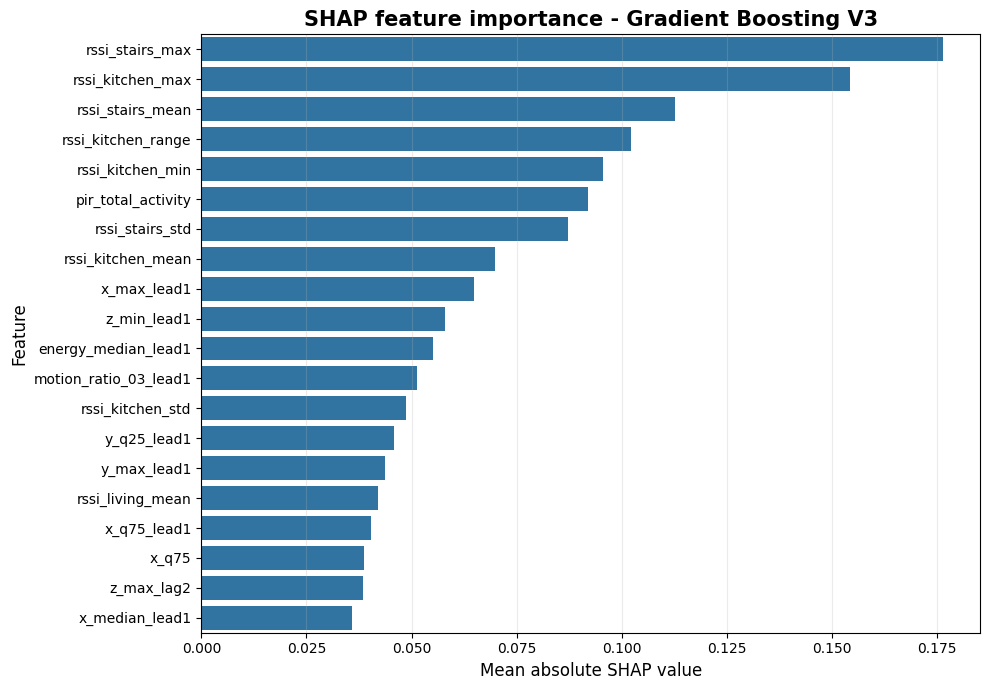

In [ ]:
# ============================================================
# SHAP - V3 CLEAN SEMANTIC MODEL
# ============================================================

import os
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------

SHAP_V3_DIR = os.path.join(RESULT_V3_DIR, "shap_v3")
os.makedirs(SHAP_V3_DIR, exist_ok=True)

SHAP_SAMPLE_SIZE = 300
SHAP_MODEL_NAME = "Gradient Boosting v3"

shap_sample_path = os.path.join(SHAP_V3_DIR, "v3_shap_sample.pkl")
shap_values_path = os.path.join(SHAP_V3_DIR, "v3_shap_values.pkl")
shap_classes_path = os.path.join(SHAP_V3_DIR, "v3_shap_classes.pkl")
shap_importance_path = os.path.join(SHAP_V3_DIR, "v3_shap_importance.pkl")

# ------------------------------------------------------------
# Modell og sample
# ------------------------------------------------------------

shap_model = trained_models_v3_clean[SHAP_MODEL_NAME]
shap_classes = shap_model.classes_

if os.path.exists(shap_sample_path):
    X_shap_v3 = joblib.load(shap_sample_path)
else:
    X_shap_v3 = X_test_v3_clean.sample(
        min(SHAP_SAMPLE_SIZE, len(X_test_v3_clean)),
        random_state=42
    )
    joblib.dump(X_shap_v3, shap_sample_path)

# ------------------------------------------------------------
# Beregn eller last SHAP
# ------------------------------------------------------------

if (
    os.path.exists(shap_values_path)
    and os.path.exists(shap_classes_path)
    and os.path.exists(shap_importance_path)
):
    print("Laster cached SHAP for V3")
    shap_values_v3 = joblib.load(shap_values_path)
    shap_classes = joblib.load(shap_classes_path)
    shap_v3_importance = joblib.load(shap_importance_path)

else:
    print("Beregner SHAP for V3")

    explainer = shap.TreeExplainer(shap_model)
    shap_values_v3 = explainer.shap_values(X_shap_v3)

    # --------------------------------------------------------
    # Håndter ulike SHAP-formater
    # --------------------------------------------------------

    if isinstance(shap_values_v3, list):
        # list: én matrise per klasse
        shap_array = np.stack(shap_values_v3, axis=2)

    else:
        shap_array = np.array(shap_values_v3)

        # forventet multiclass-format: samples x features x classes
        if shap_array.ndim == 2:
            shap_array = shap_array[:, :, np.newaxis]

    # Global SHAP importance: mean absolute SHAP over samples og klasser
    global_shap_importance = np.abs(shap_array).mean(axis=(0, 2))

    shap_v3_importance = pd.DataFrame({
        "Feature": X_shap_v3.columns,
        "Mean_abs_SHAP": global_shap_importance
    }).sort_values("Mean_abs_SHAP", ascending=False)

    joblib.dump(shap_values_v3, shap_values_path)
    joblib.dump(shap_classes, shap_classes_path)
    joblib.dump(shap_v3_importance, shap_importance_path)

print("SHAP sample shape:", X_shap_v3.shape)
print("Antall klasser:", len(shap_classes))
print("Klasser:", shap_classes)

# ------------------------------------------------------------
# Tabell
# ------------------------------------------------------------

display(
    shap_v3_importance.head(20).style
    .format({"Mean_abs_SHAP": "{:.4f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Mean_abs_SHAP"]
    )
)

# ------------------------------------------------------------
# Plot: global SHAP importance
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.barplot(
    data=shap_v3_importance.head(20),
    x="Mean_abs_SHAP",
    y="Feature"
)

plt.title(
    "SHAP feature importance - Gradient Boosting V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean absolute SHAP value", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

##Robusthet

Laster cachede V3 støy-resultater


,Model,Noise,Macro_F1
0,Random Forest,0.00,0.417
1,Gradient Boosting,0.00,0.444
2,Logistic Regression,0.00,0.386
3,Linear SVM,0.00,0.376
4,Random Forest,0.05,0.365
5,Gradient Boosting,0.05,0.411
6,Logistic Regression,0.05,0.290
7,Linear SVM,0.05,0.227
8,Random Forest,0.10,0.320
9,Gradient Boosting,0.10,0.375


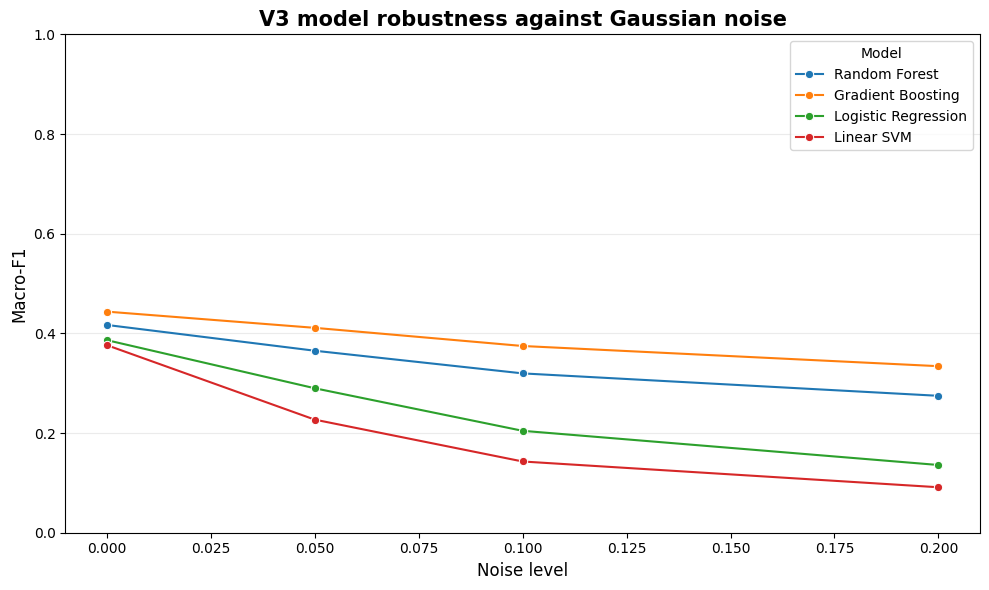

In [ ]:
# ======================================================
# V3 ROBUSTHET MOT GAUSSISK STØY
# ======================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import f1_score

noise_v3_path = os.path.join(
    RESULT_V3_DIR,
    "noise_robustness_v3_clean.pkl"
)

noise_levels_v3 = [0, 0.05, 0.10, 0.20]

v3_noise_models = {
    "Random Forest": trained_models_v3_clean["Random Forest v3"],
    "Gradient Boosting": trained_models_v3_clean["Gradient Boosting v3"],
    "Logistic Regression": trained_models_v3_clean["Logistic Regression v3"],
    "Linear SVM": trained_models_v3_clean["Linear SVM v3"]
}

if os.path.exists(noise_v3_path):

    print("Laster cachede V3 støy-resultater")
    noise_results_v3 = joblib.load(noise_v3_path)

else:

    print("Kjører V3 støy-eksperiment")

    noise_rows_v3 = []

    for noise in noise_levels_v3:

        print("Støynivå:", noise)

        X_test_v3_noisy = X_test_v3_clean.copy()

        if noise > 0:
            rng = np.random.default_rng(42)

            noise_matrix = rng.normal(
                loc=0,
                scale=noise,
                size=X_test_v3_noisy.shape
            )

            X_test_v3_noisy = X_test_v3_noisy + noise_matrix

        for model_name, model in v3_noise_models.items():

            preds = model.predict(X_test_v3_noisy)

            score = f1_score(
                y_test_v3_clean,
                preds,
                average="macro",
                zero_division=0
            )

            noise_rows_v3.append({
                "Model": model_name,
                "Noise": noise,
                "Macro_F1": score
            })

    noise_results_v3 = pd.DataFrame(noise_rows_v3)

    joblib.dump(noise_results_v3, noise_v3_path)

display(
    noise_results_v3.style
    .format({"Noise": "{:.2f}", "Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=noise_results_v3,
    x="Noise",
    y="Macro_F1",
    hue="Model",
    marker="o"
)

plt.title(
    "V3 model robustness against Gaussian noise",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Noise level", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# ======================================================
# V3 SENSORABLASJON
# Tester ACC, PIR, RSSI og kombinasjoner i V3-pipelinen
# ======================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline

# ------------------------------------------------------
# 1. Definer feature-grupper for V3
# ------------------------------------------------------

v3_all_features = list(X_train_v3_sub.columns)

# Akselerometer-relaterte features, inkludert temporale lag/lead
v3_acc_features = [
    c for c in v3_all_features
    if (
        c.startswith(("x_", "y_", "z_"))
        or c.startswith("energy_")
        or c.startswith("magnitude_")
        or c.startswith("motion_ratio")
    )
]

# PIR-relaterte features
v3_pir_features = [
    c for c in v3_all_features
    if c.startswith("pir_")
]

# RSSI-relaterte features
v3_rssi_features = [
    c for c in v3_all_features
    if c.startswith("rssi_")
]

v3_feature_sets = {
    "ACC_only": v3_acc_features,
    "PIR_only": v3_pir_features,
    "RSSI_only": v3_rssi_features,
    "ACC+PIR": v3_acc_features + v3_pir_features,
    "ACC+RSSI": v3_acc_features + v3_rssi_features,
    "PIR+RSSI": v3_pir_features + v3_rssi_features,
    "ALL": v3_acc_features + v3_pir_features + v3_rssi_features
}

print("Antall V3 features:")
for name, features in v3_feature_sets.items():
    print(name, len(features))


# ------------------------------------------------------
# 2. Hjelpefunksjon for sample weights
# ------------------------------------------------------

def fit_v3_ablation_model(model, X, y, confidence):
    class_weights = compute_sample_weight(
        class_weight="balanced",
        y=y
    )

    sample_weights = class_weights * (confidence.values ** 2)

    if isinstance(model, Pipeline):
        last_step_name = model.steps[-1][0]

        try:
            model.fit(
                X,
                y,
                **{f"{last_step_name}__sample_weight": sample_weights}
            )
        except (TypeError, ValueError):
            model.fit(X, y)

    else:
        try:
            model.fit(
                X,
                y,
                sample_weight=sample_weights
            )
        except (TypeError, ValueError):
            model.fit(X, y)

    return model


# ------------------------------------------------------
# 3. Kjør eller last cachede V3 sensorablasjonsresultater
# ------------------------------------------------------

v3_ablation_path = os.path.join(
    RESULT_V3_DIR,
    "sensor_ablation_v3_clean.pkl"
)

if os.path.exists(v3_ablation_path):

    print("Laster cachede V3 sensorablasjonsresultater")
    ablation_results_v3 = joblib.load(v3_ablation_path)

else:

    print("Kjører V3 sensorablasjon")

    ablation_rows_v3 = []

    # Dropp Dummy for ryddigere figur
    v3_ablation_models = {
        name: model
        for name, model in v3_models.items()
        if name != "Dummy v3"
    }

    for exp_name, features in v3_feature_sets.items():

        print(f"\nEksperiment: {exp_name}")

        if len(features) == 0:
            print(f"Hopper over {exp_name}, ingen features funnet")
            continue

        Xtr = X_train_v3_sub[features]
        Xte = X_test_v3_clean[features]

        for model_name, model in v3_ablation_models.items():

            print(f"  Modell: {model_name}")

            model_temp = clone(model)

            model_temp = fit_v3_ablation_model(
                model_temp,
                Xtr,
                y_train_v3_clean_sub,
                conf_train_v3_sub
            )

            preds = model_temp.predict(Xte)

            score = f1_score(
                y_test_v3_clean,
                preds,
                average="macro",
                zero_division=0
            )

            ablation_rows_v3.append({
                "Experiment": exp_name,
                "Model": model_name.replace(" v3", ""),
                "Macro_F1": score
            })

    ablation_results_v3 = pd.DataFrame(ablation_rows_v3)

    joblib.dump(ablation_results_v3, v3_ablation_path)

display(
    ablation_results_v3.style
    .format({"Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

Antall V3 features:
ACC_only 180
PIR_only 29
RSSI_only 20
ACC+PIR 209
ACC+RSSI 200
PIR+RSSI 49
ALL 229
Laster cachede V3 sensorablasjonsresultater


,Experiment,Model,Macro_F1
0,ACC_only,Logistic Regression,0.295
1,ACC_only,Random Forest,0.348
2,ACC_only,Gradient Boosting,0.376
3,ACC_only,Linear SVM,0.253
4,PIR_only,Logistic Regression,0.142
5,PIR_only,Random Forest,0.143
6,PIR_only,Gradient Boosting,0.142
7,PIR_only,Linear SVM,0.140
8,RSSI_only,Logistic Regression,0.248
9,RSSI_only,Random Forest,0.290


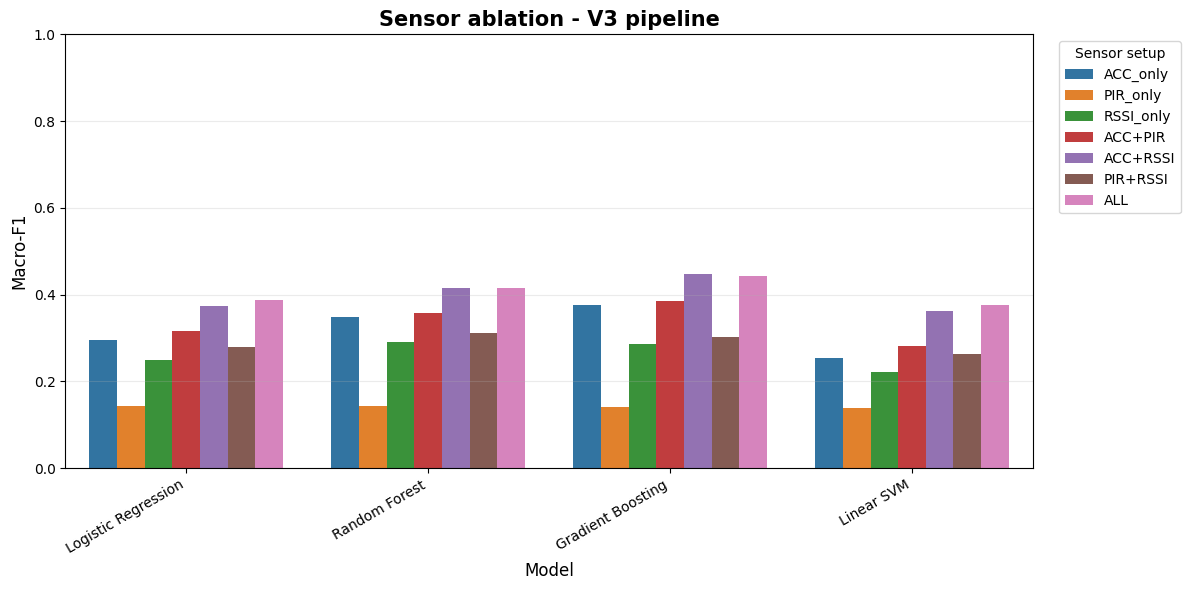

In [ ]:
# ======================================================
# PLOT: V3 SENSORABLASJON
# ======================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ablation_results_v3,
    x="Model",
    y="Macro_F1",
    hue="Experiment"
)

plt.title(
    "Sensor ablation - V3 pipeline",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.xticks(rotation=30, ha="right")

plt.ylim(0, 1)

plt.legend(
    title="Sensor setup",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()



In [ ]:
# PERMUTATION IMPORTANCE - BESTE MODELL

from sklearn.inspection import permutation_importance
import joblib
import os

perm_cache = os.path.join(RESULT_V3_DIR, "perm_importance_cache.pkl")

if os.path.exists(perm_cache):
    print("Laster cached permutation importance")
    importance_df = joblib.load(perm_cache)
else:
    print("Kjører permutation importance...")
    best_model = trained_models_v3_clean["Gradient Boosting v3"]

    perm_importance = permutation_importance(
        best_model,
        X_test_v3_imp,
        y_test_v3_clean,
        n_repeats=5,
        random_state=42,
        scoring="f1_macro",
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test_v3_imp.columns,
        "Importance_Mean": perm_importance.importances_mean,
        "Importance_STD": perm_importance.importances_std
    }).sort_values("Importance_Mean", ascending=False)

    joblib.dump(importance_df, perm_cache)
    print("Cachet!")

print("Top 20 viktigste features:")
display(importance_df.head(20))

Laster cached permutation importance
Top 20 viktigste features:


,Feature,Importance_Mean,Importance_STD
31,magnitude_std,0.035053,0.003400
83,rssi_stairs_max,0.030965,0.001331
80,rssi_stairs_mean,0.028096,0.001467
68,rssi_kitchen_max,0.018965,0.001181
81,rssi_stairs_std,0.009988,0.002613
67,rssi_kitchen_min,0.008539,0.001263
219,energy_min_lead1,0.007908,0.002183
69,rssi_kitchen_range,0.007585,0.000903
211,z_min_lead1,0.005808,0.001280
171,y_q25_lag3,0.005351,0.001524


#Sammenligning

##Ytelse

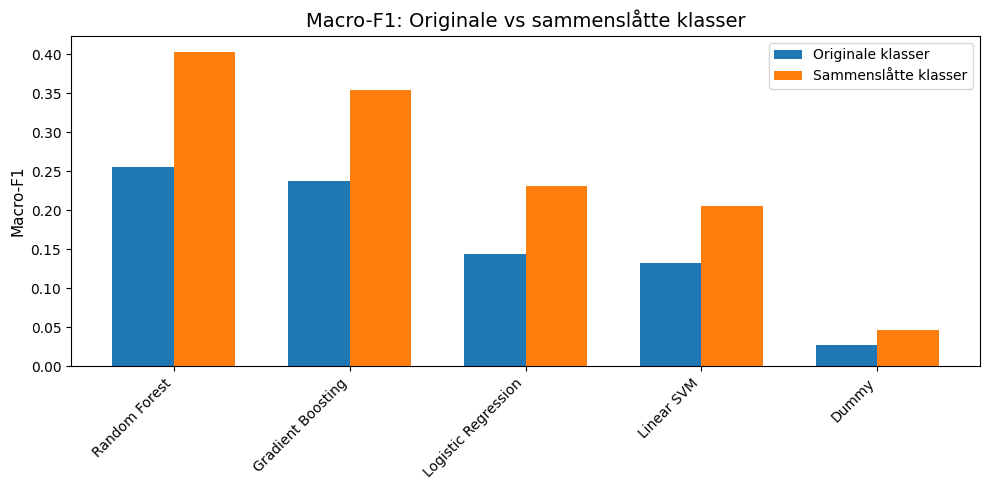

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filtrer ut 1D-CNN
models_list = [m for m in performance_df["Model"].tolist() if m != "1D-CNN"]
original_f1 = performance_df.set_index("Model").loc[models_list]["Macro_F1"].tolist()
merged_f1 = performance_merged_df.set_index("Model").loc[models_list]["Macro_F1"].tolist()

x = np.arange(len(models_list))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, original_f1, width, label="Originale klasser")
ax.bar(x + width/2, merged_f1, width, label="Sammenslåtte klasser")

ax.set_title("Macro-F1: Originale vs sammenslåtte klasser")
ax.set_xticks(x)
ax.set_xticklabels(models_list, rotation=45, ha="right")
ax.set_ylabel("Macro-F1")
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_6492/638583300.py:52: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  overall_comparison = pd.concat(


,Pipeline,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
6,V3 clean semantic,Gradient Boosting,0.688778,0.443636,0.661128,0.505148,0.468206
7,V3 clean semantic,Random Forest,0.678888,0.416901,0.641197,0.638859,0.415671
8,V3 clean semantic,Logistic Regression,0.526262,0.386412,0.548308,0.377453,0.473804
9,V3 clean semantic,Linear SVM,0.509558,0.376335,0.531186,0.364815,0.468265
11,Raw CNN V2,Raw CNN V2,0.342419,0.278572,0.365003,NaN,NaN
0,Baseline,Random Forest,0.564659,0.254784,0.509994,0.403190,0.225782
1,Baseline,1D-CNN,0.374184,0.239128,0.390408,0.233682,0.261546
2,Baseline,Gradient Boosting,0.566613,0.237936,0.514284,0.361168,0.218078
3,Baseline,Logistic Regression,0.182886,0.144080,0.176256,0.165987,0.267943
4,Baseline,Linear SVM,0.223174,0.132954,0.222114,0.158807,0.251857


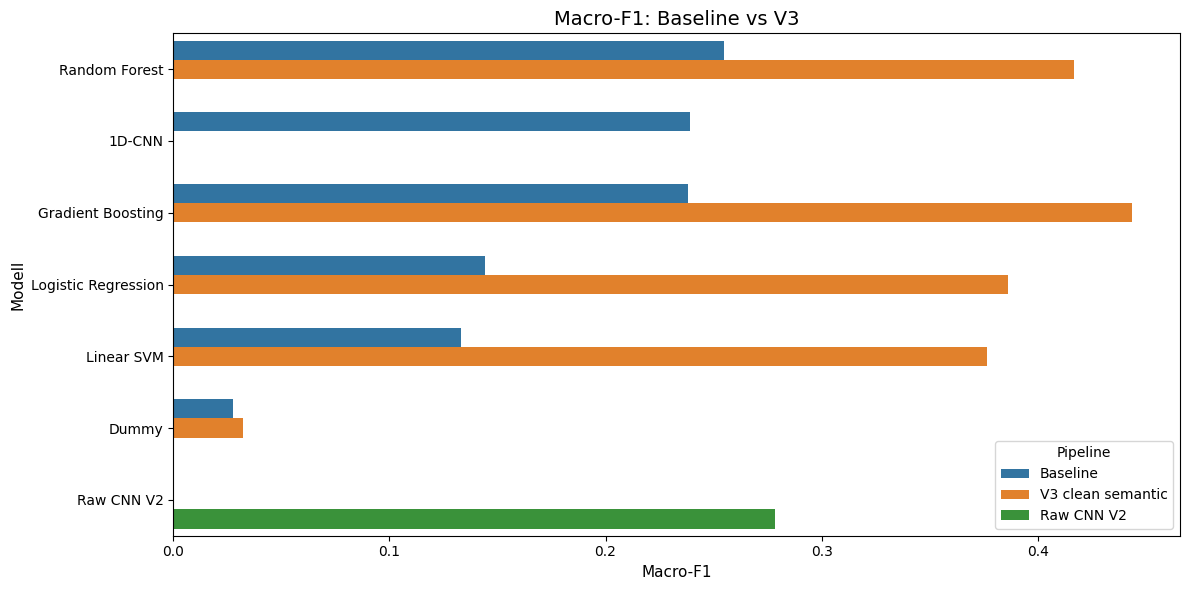

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.4s
[Parallel(n_jobs=12)]: Done 800 out of 800 | elapsed:    0.4s finished


,Pipeline,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall
3,V3 high-confidence,Gradient Boosting,0.729989,0.489410,0.712471,0.527899,0.508061
2,V3 high-confidence,Random Forest,0.720740,0.464172,0.695426,0.664801,0.450724
1,V3 high-confidence,Logistic Regression,0.552532,0.417507,0.580118,0.389825,0.523865
4,V3 high-confidence,Linear SVM,0.533702,0.401456,0.559174,0.374238,0.517624
5,Raw CNN V2,Raw CNN V2,0.342419,0.278572,0.365003,0.275619,0.385711
0,V3 high-confidence,Dummy,0.203606,0.033833,0.068886,0.020361,0.100000


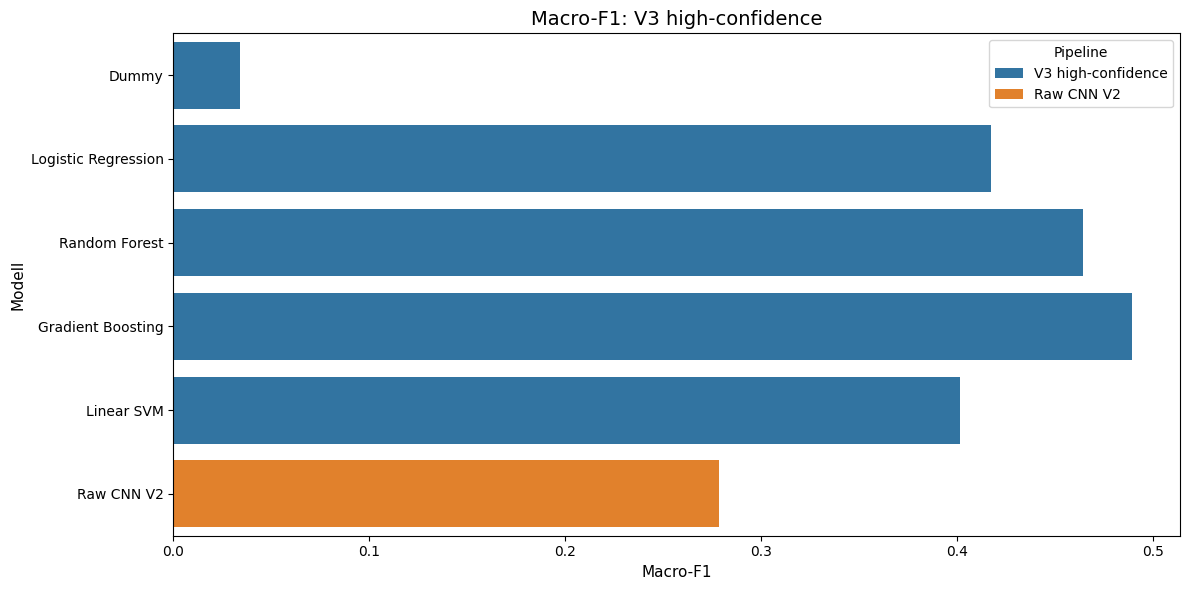

In [ ]:
# ============================================================
# BASELINE VS V3: OVERALL PERFORMANCE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# ----------------------------
# 1. Baseline-resultater
# ----------------------------

baseline_overall = performance_df.copy()
baseline_overall["Pipeline"] = "Baseline"

# ----------------------------
# 2. V3 clean semantic-resultater
# ----------------------------

v3_clean_overall = performance_v3_all[
    performance_v3_all["Experiment"] == "Clean semantic classes"
].copy()

v3_clean_overall["Pipeline"] = "V3 clean semantic"

# Fjern " v3" fra modellnavn slik at modellene kan sammenlignes lettere
v3_clean_overall["Model"] = (
    v3_clean_overall["Model"]
    .str.replace(" v3", "", regex=False)
)

# ----------------------------
# 3. Raw CNN V2-resultat
# ----------------------------

raw_cnn_overall = pd.DataFrame([{
    "Experiment": "Raw CNN V2",
    "Model": "Raw CNN V2",
    "Accuracy": raw_cnn_accuracy,
    "Macro_F1": raw_cnn_macro_f1,
    "Weighted_F1": raw_cnn_weighted_f1,
    "Macro_Precision": None,
    "Macro_Recall": None,
    "Pipeline": "Raw CNN V2"
}])

# ----------------------------
# 4. Kombiner resultater
# ----------------------------

overall_comparison = pd.concat(
    [
        baseline_overall[[
            "Pipeline", "Model", "Accuracy", "Macro_F1", "Weighted_F1",
            "Macro_Precision", "Macro_Recall"
        ]],
        v3_clean_overall[[
            "Pipeline", "Model", "Accuracy", "Macro_F1", "Weighted_F1",
            "Macro_Precision", "Macro_Recall"
        ]],
        raw_cnn_overall[[
            "Pipeline", "Model", "Accuracy", "Macro_F1", "Weighted_F1",
            "Macro_Precision", "Macro_Recall"
        ]]
    ],
    ignore_index=True
)

display(overall_comparison.sort_values("Macro_F1", ascending=False))

# ----------------------------
# 5. Plot Macro-F1
# ----------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=overall_comparison,
    x="Macro_F1",
    y="Model",
    hue="Pipeline"
)

plt.title("Macro-F1: Baseline vs V3")
plt.xlabel("Macro-F1")
plt.ylabel("Modell")

plt.tight_layout()
plt.show()

#High Confidence
v3_highconf_rows = []

for model_name, model in trained_models_v3_clean.items():

    preds_highconf = model.predict(X_test_v3_highconf)

    v3_highconf_rows.append({
        "Pipeline": "V3 high-confidence",
        "Model": model_name.replace(" v3", ""),
        "Accuracy": accuracy_score(y_test_v3_clean_highconf, preds_highconf),
        "Macro_F1": f1_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_test_v3_clean_highconf, preds_highconf, average="weighted", zero_division=0),
        "Macro_Precision": precision_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_test_v3_clean_highconf, preds_highconf, average="macro", zero_division=0)
    })

overall_highconf_comparison = pd.DataFrame(v3_highconf_rows)

raw_cnn_highconf_report = {
    "Pipeline": "Raw CNN V2",
    "Model": "Raw CNN V2",
    "Accuracy": raw_cnn_accuracy,
    "Macro_F1": raw_cnn_macro_f1,
    "Weighted_F1": raw_cnn_weighted_f1,
    "Macro_Precision": precision_score(
        y_test_raw_cnn,
        y_pred_raw_labels,
        average="macro",
        zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_test_raw_cnn,
        y_pred_raw_labels,
        average="macro",
        zero_division=0
    )
}

overall_highconf_comparison = pd.concat(
    [
        overall_highconf_comparison,
        pd.DataFrame([raw_cnn_highconf_report])
    ],
    ignore_index=True
)

display(
    overall_highconf_comparison.sort_values(
        "Macro_F1",
        ascending=False
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=overall_highconf_comparison,
    x="Macro_F1",
    y="Model",
    hue="Pipeline"
)

plt.title("Macro-F1: V3 high-confidence")
plt.xlabel("Macro-F1")
plt.ylabel("Modell")

plt.tight_layout()
plt.show()

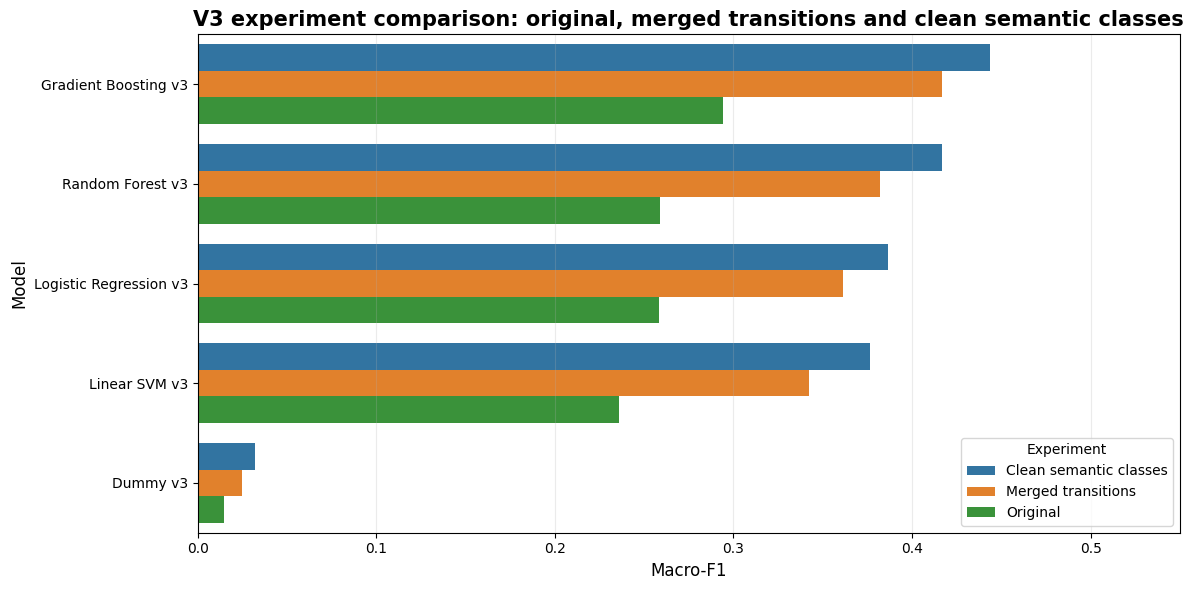

In [ ]:
# ============================================================
# V3 EXPERIMENT COMPARISON: ORIGINAL / MERGED / CLEAN
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_v3_all,
    x="Macro_F1",
    y="Model",
    hue="Experiment"
)

plt.title(
    "V3 experiment comparison: original, merged transitions and clean semantic classes",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Macro-F1", fontsize=12)
plt.ylabel("Model", fontsize=12)

plt.xlim(0, 0.55)

plt.legend(
    title="Experiment",
    loc="lower right"
)

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

###Per Klasse F-1

,Random Forest V3,Gradient Boosting V3,Logistic Regression V3,Linear SVM V3
Class,,,,
Bent,0.422,0.467,0.310,0.277
Jump,0.500,0.589,0.364,0.347
Kneel,0.236,0.241,0.310,0.313
Lie,0.737,0.747,0.646,0.628
Sit,0.759,0.782,0.693,0.674
Squat,0.000,0.000,0.000,0.000
Stairs,0.239,0.291,0.357,0.387
Stand,0.767,0.780,0.590,0.569
Turn,0.007,0.010,0.126,0.130


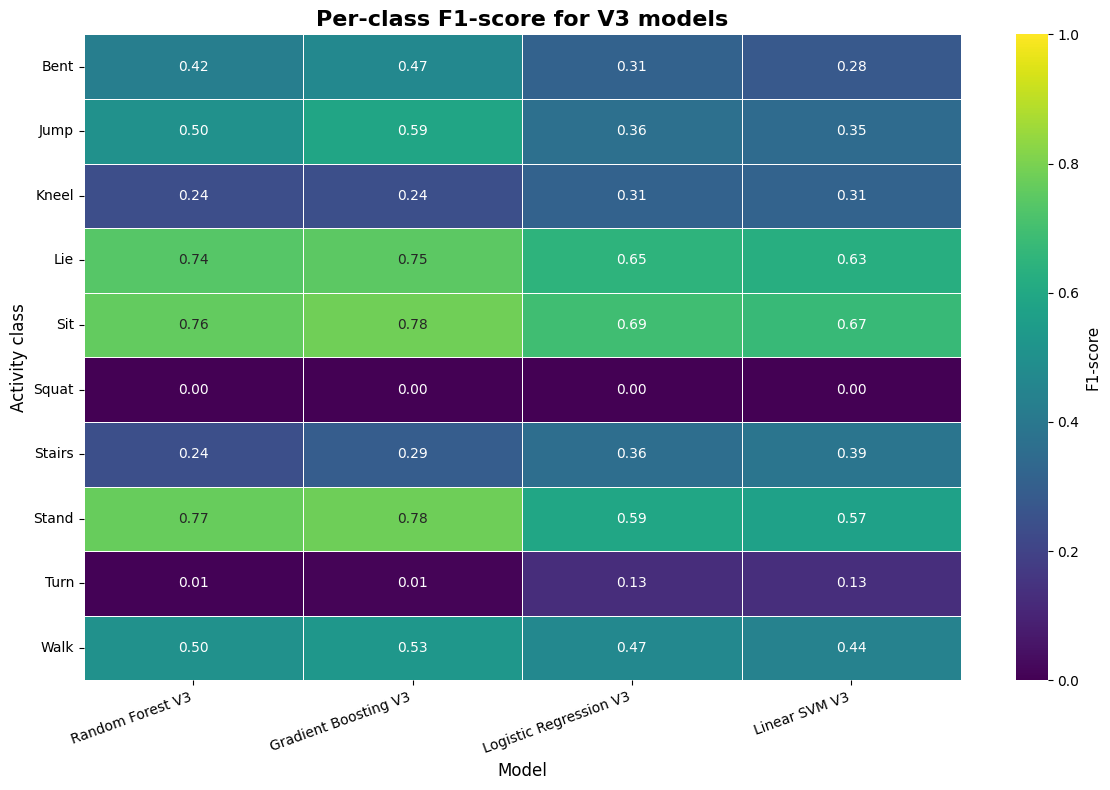

In [ ]:
# ============================================================
# PER-CLASS F1: BASELINE VS V3
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# ------------------------------------------------------------
# 1. Map baseline y_test og baseline predictions til clean semantic classes
# ------------------------------------------------------------

y_test_baseline_clean = map_activity_to_clean_class(
    pd.Series(y_test)
).reset_index(drop=True)

baseline_clean_predictions = {}

for model_name, preds in predictions.items():
    baseline_clean_predictions[model_name] = map_activity_to_clean_class(
        pd.Series(preds)
    ).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Lag classification reports for baseline i clean class-systemet
# ------------------------------------------------------------

baseline_clean_reports = {}

for model_name, preds_clean in baseline_clean_predictions.items():

    valid_mask = y_test_baseline_clean.notna() & preds_clean.notna()

    baseline_clean_reports[model_name] = classification_report(
        y_test_baseline_clean[valid_mask],
        preds_clean[valid_mask],
        output_dict=True,
        zero_division=0
    )

# ------------------------------------------------------------
# 3. Lag classification reports for V3 clean semantic classes
# ------------------------------------------------------------

v3_clean_reports = {}

for model_name, preds in predictions_v3_clean.items():

    v3_clean_reports[model_name] = classification_report(
        y_test_v3_clean,
        preds,
        output_dict=True,
        zero_division=0
    )

# ------------------------------------------------------------
# 4. Lag report for Raw CNN V2
# ------------------------------------------------------------

raw_cnn_report = classification_report(
    y_test_raw_cnn,
    y_pred_raw_labels,
    output_dict=True,
    zero_division=0
)

# ------------------------------------------------------------
# 5. Finn felles klasser
# ------------------------------------------------------------

class_names = sorted([
    c for c in v3_clean_reports["Gradient Boosting v3"].keys()
    if c not in ["accuracy", "macro avg", "weighted avg"]
])

# ------------------------------------------------------------
# 6. Bygg per-class F1-tabell
# ------------------------------------------------------------

per_class_comparison = pd.DataFrame({
    "RF Baseline": [
        baseline_clean_reports["Random Forest"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "RF V3": [
        v3_clean_reports["Random Forest v3"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "GB Baseline": [
        baseline_clean_reports["Gradient Boosting"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "GB V3": [
        v3_clean_reports["Gradient Boosting v3"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "LogReg Baseline": [
        baseline_clean_reports["Logistic Regression"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "LogReg V3": [
        v3_clean_reports["Logistic Regression v3"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "Linear SVM Baseline": [
        baseline_clean_reports["Linear SVM"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "Linear SVM V3": [
        v3_clean_reports["Linear SVM v3"].get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ],
    "Raw CNN V2": [
        raw_cnn_report.get(c, {"f1-score": 0})["f1-score"]
        for c in class_names
    ]
}, index=class_names)

display(
    v3_per_class_df.style
    .format("{:.3f}")
    .background_gradient(cmap="viridis")
)

# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

sns.heatmap(
    v3_per_class_df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "F1-score"}
)

plt.title(
    "Per-class F1-score for V3 models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Model", fontsize=12)
plt.ylabel("Activity class", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

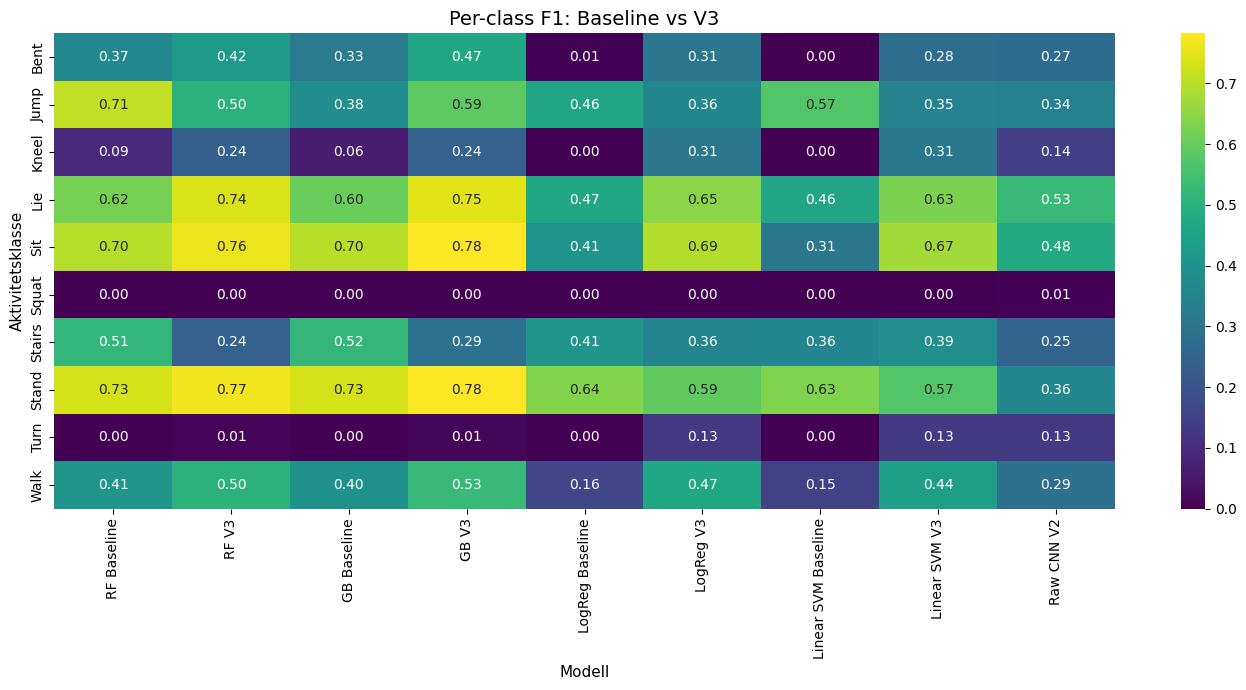

In [ ]:
# ============================================================
# HEATMAP: PER-CLASS F1 BASELINE VS V3
# ============================================================

plt.figure(figsize=(14, 7))

sns.heatmap(
    per_class_comparison,
    annot=True,
    fmt=".2f",
    cmap="viridis"
)

plt.title("Per-class F1: Baseline vs V3")
plt.ylabel("Aktivitetsklasse")
plt.xlabel("Modell")

plt.tight_layout()
plt.show()

,Random Forest,Gradient Boosting,Logistic Regression,Linear SVM
Bent,0.055,0.142,0.304,0.277
Jump,-0.208,0.209,-0.097,-0.222
Kneel,0.144,0.182,0.310,0.313
Lie,0.118,0.142,0.179,0.167
Sit,0.063,0.084,0.288,0.363
Squat,0.000,0.000,0.000,0.000
Stairs,-0.275,-0.226,-0.051,0.028
Stand,0.036,0.049,-0.047,-0.062
Turn,0.007,0.010,0.126,0.130
Walk,0.094,0.130,0.304,0.285


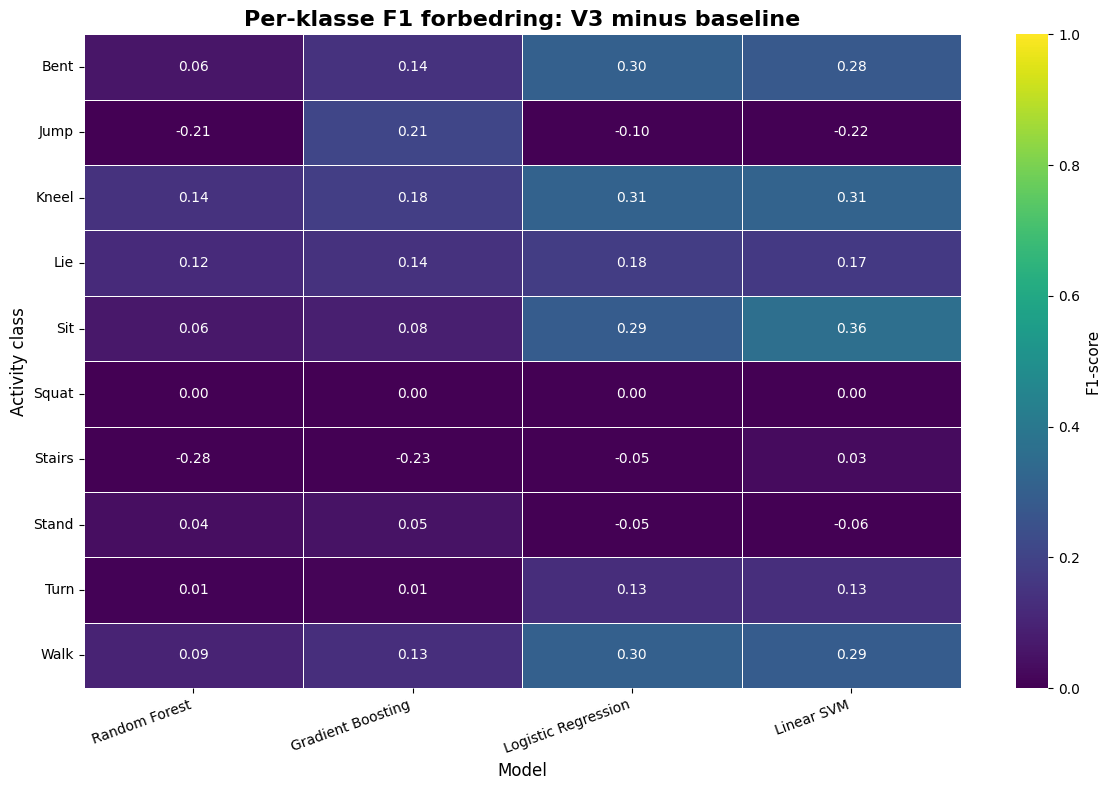

In [ ]:
# ============================================================
# IMPROVEMENT PLOT: V3 - BASELINE
# ============================================================

improvement_df = pd.DataFrame({
    "Random Forest": per_class_comparison["RF V3"] - per_class_comparison["RF Baseline"],
    "Gradient Boosting": per_class_comparison["GB V3"] - per_class_comparison["GB Baseline"],
    "Logistic Regression": per_class_comparison["LogReg V3"] - per_class_comparison["LogReg Baseline"],
    "Linear SVM": per_class_comparison["Linear SVM V3"] - per_class_comparison["Linear SVM Baseline"]
}, index=per_class_comparison.index)


display(
    improvement_df.style
    .format("{:.3f}")
    .background_gradient(cmap="viridis")
)

# HEATMAP

plt.figure(figsize=(12, 8))

sns.heatmap(
    improvement_df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "F1-score"}
)

plt.title(
    "Per-klasse F1 forbedring: V3 minus baseline",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Model", fontsize=12)
plt.ylabel("Activity class", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

###Confusion Matrix

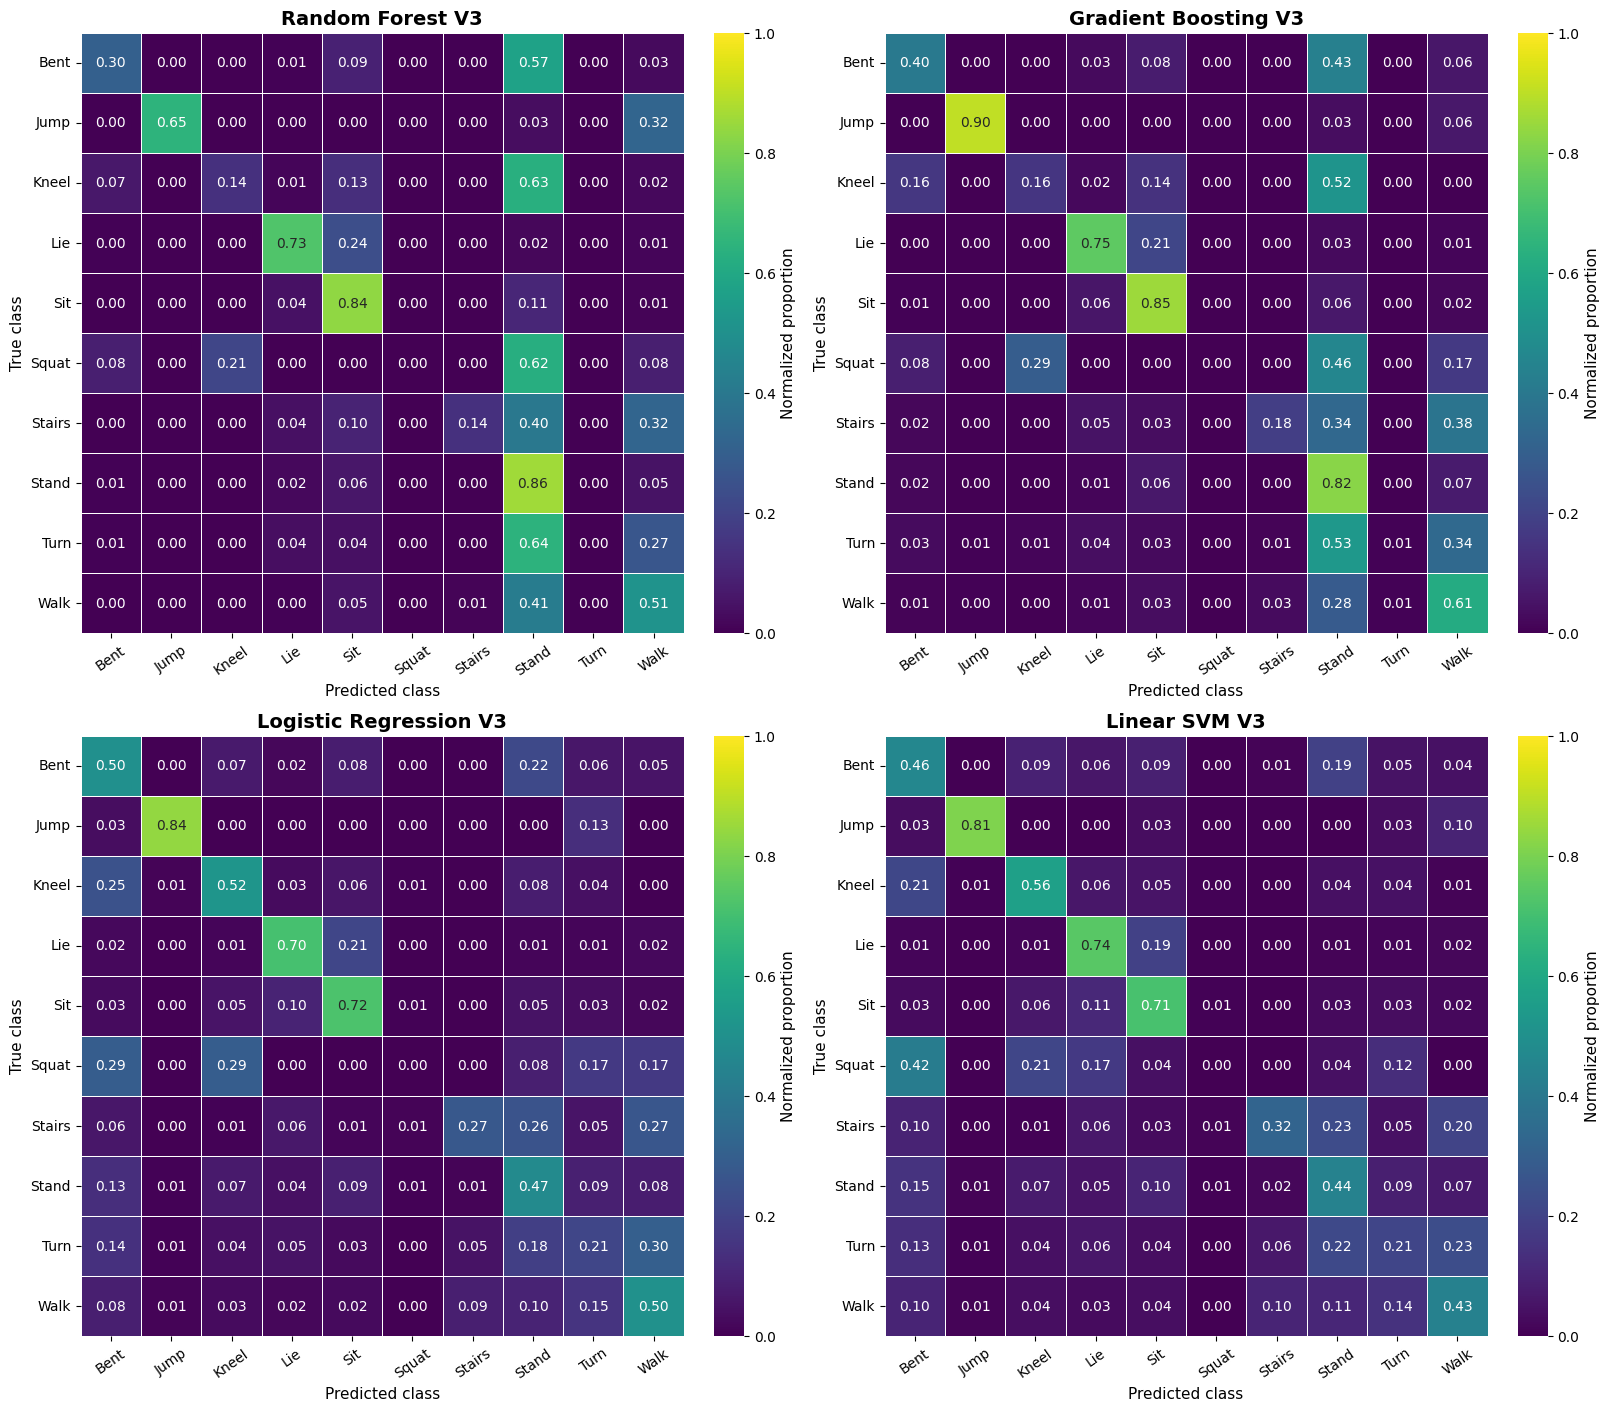

In [ ]:
# ======================================================
# FIGUR: FORVIRRINGSMATRISER FOR V3-PIPELINE
# Bruker faktiske variabler fra notebooken:
# predictions_v3_clean, y_test_v3_clean
# ======================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

v3_cm_predictions = {
    "Random Forest V3": predictions_v3_clean["Random Forest v3"],
    "Gradient Boosting V3": predictions_v3_clean["Gradient Boosting v3"],
    "Logistic Regression V3": predictions_v3_clean["Logistic Regression v3"],
    "Linear SVM V3": predictions_v3_clean["Linear SVM v3"]
}

class_labels_v3 = sorted(pd.Series(y_test_v3_clean).unique())

cols = 2
rows = int(np.ceil(len(v3_cm_predictions) / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 7 * rows),
    constrained_layout=True
)

axes = axes.flatten()

for ax, (name, preds) in zip(axes, v3_cm_predictions.items()):

    cm = confusion_matrix(
        y_test_v3_clean,
        preds,
        labels=class_labels_v3
    )

    cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
    cm_norm = np.nan_to_num(cm_norm)

    sns.heatmap(
        cm_norm,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        xticklabels=class_labels_v3,
        yticklabels=class_labels_v3,
        cbar_kws={"label": "Normalized proportion"}
    )

    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.set_xlabel("Predicted class", fontsize=11)
    ax.set_ylabel("True class", fontsize=11)

    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

for ax in axes[len(v3_cm_predictions):]:
    ax.axis("off")



plt.show()

### High-Confidence Gradiant Boosting

,Metric,Score
0,Accuracy,0.730
1,Macro-F1,0.489
2,Weighted-F1,0.712


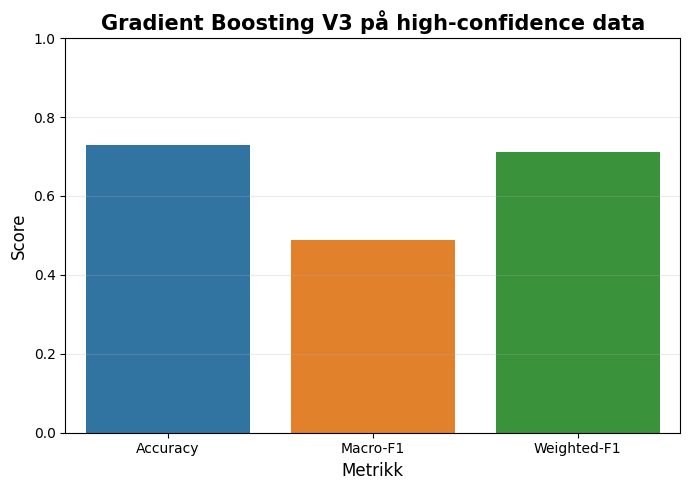

In [ ]:
# ============================================================
# HIGH-CONFIDENCE TEST RESULT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Dataframe
# ------------------------------------------------------------

highconf_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro-F1", "Weighted-F1"],
    "Score": [
        acc_highconf,
        macro_f1_highconf,
        weighted_f1_highconf
    ]
})

# ------------------------------------------------------------
# Styled table
# ------------------------------------------------------------

display(
    highconf_df.style
    .format({"Score": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Score"]
    )
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.barplot(
    data=highconf_df,
    x="Metric",
    y="Score",
    hue="Metric",
    legend=False
)

plt.title(
    "Gradient Boosting V3 på high-confidence data",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Metrikk", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

,Test set,Metric,Score
0,Full test,Accuracy,0.689
1,Full test,Macro-F1,0.444
2,Full test,Weighted-F1,0.661
3,High-confidence,Accuracy,0.730
4,High-confidence,Macro-F1,0.489
5,High-confidence,Weighted-F1,0.712


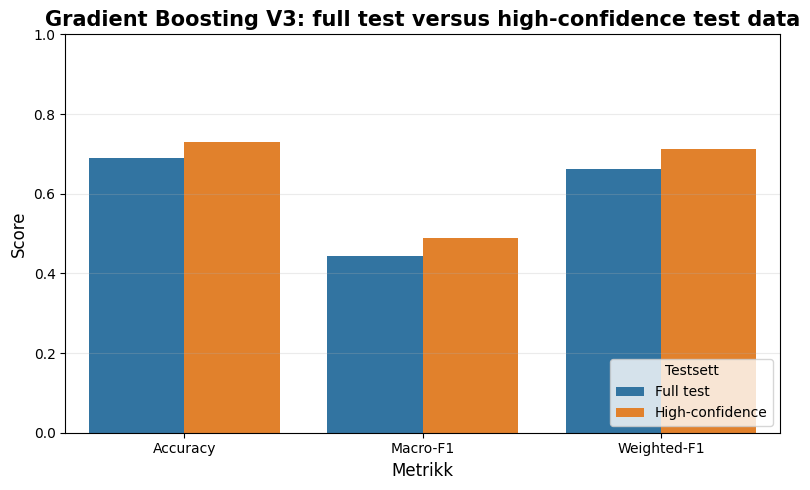

In [ ]:
# ======================================================
# FULL TEST VS HIGH-CONFIDENCE TEST
# Gradient Boosting V3
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fulltest-resultater for Gradient Boosting V3 fra performance_v3_all
gb_v3_full = performance_v3_all[
    (performance_v3_all["Model"] == "Gradient Boosting v3") &
    (performance_v3_all["Experiment"] == "Clean semantic classes")
].iloc[0]

full_vs_highconf_df = pd.DataFrame({
    "Test set": ["Full test", "Full test", "Full test",
                 "High-confidence", "High-confidence", "High-confidence"],
    "Metric": ["Accuracy", "Macro-F1", "Weighted-F1",
               "Accuracy", "Macro-F1", "Weighted-F1"],
    "Score": [
        gb_v3_full["Accuracy"],
        gb_v3_full["Macro_F1"],
        gb_v3_full["Weighted_F1"],
        acc_highconf,
        macro_f1_highconf,
        weighted_f1_highconf
    ]
})

display(
    full_vs_highconf_df.style
    .format({"Score": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Score"]
    )
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=full_vs_highconf_df,
    x="Metric",
    y="Score",
    hue="Test set"
)

plt.title(
    "Gradient Boosting V3: full test versus high-confidence test data",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Metrikk", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.ylim(0, 1)

plt.legend(
    title="Testsett",
    loc="lower right"
)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Forklarbarhet

In [ ]:
from sklearn.inspection import permutation_importance

fi_gb_path = f"{RESULT_DIR}/feature_importance_gb.pkl"

if os.path.exists(fi_gb_path):
    print("Laster cachet feature importance for Gradient Boosting")
    importances_gb = joblib.load(fi_gb_path)

else:
    print("Beregner feature importance for Gradient Boosting")
    gb_model = trained_models["Gradient Boosting"]

    result = permutation_importance(
        gb_model,
        X_test.sample(5000, random_state=42),
        y_test.loc[X_test.sample(5000, random_state=42).index],
        n_repeats=5,
        random_state=42,
        scoring="f1_macro"
    )

    importances_gb = pd.Series(
        result.importances_mean,
        index=X_train_sub.columns
    ).sort_values(ascending=False)

    joblib.dump(importances_gb, fi_gb_path)



Laster cachet feature importance for Gradient Boosting


,Feature,Importance,Pipeline
0,x_mean,0.0756,Baseline
1,x_std,0.0712,Baseline
2,z_mean,0.0456,Baseline
3,y_mean,0.0435,Baseline
4,kitchen_y,0.0431,Baseline
5,stairs_y,0.0301,Baseline
6,z_std,0.0260,Baseline
7,living_y,0.0255,Baseline
8,y_std,0.0245,Baseline
9,living_x,0.0112,Baseline


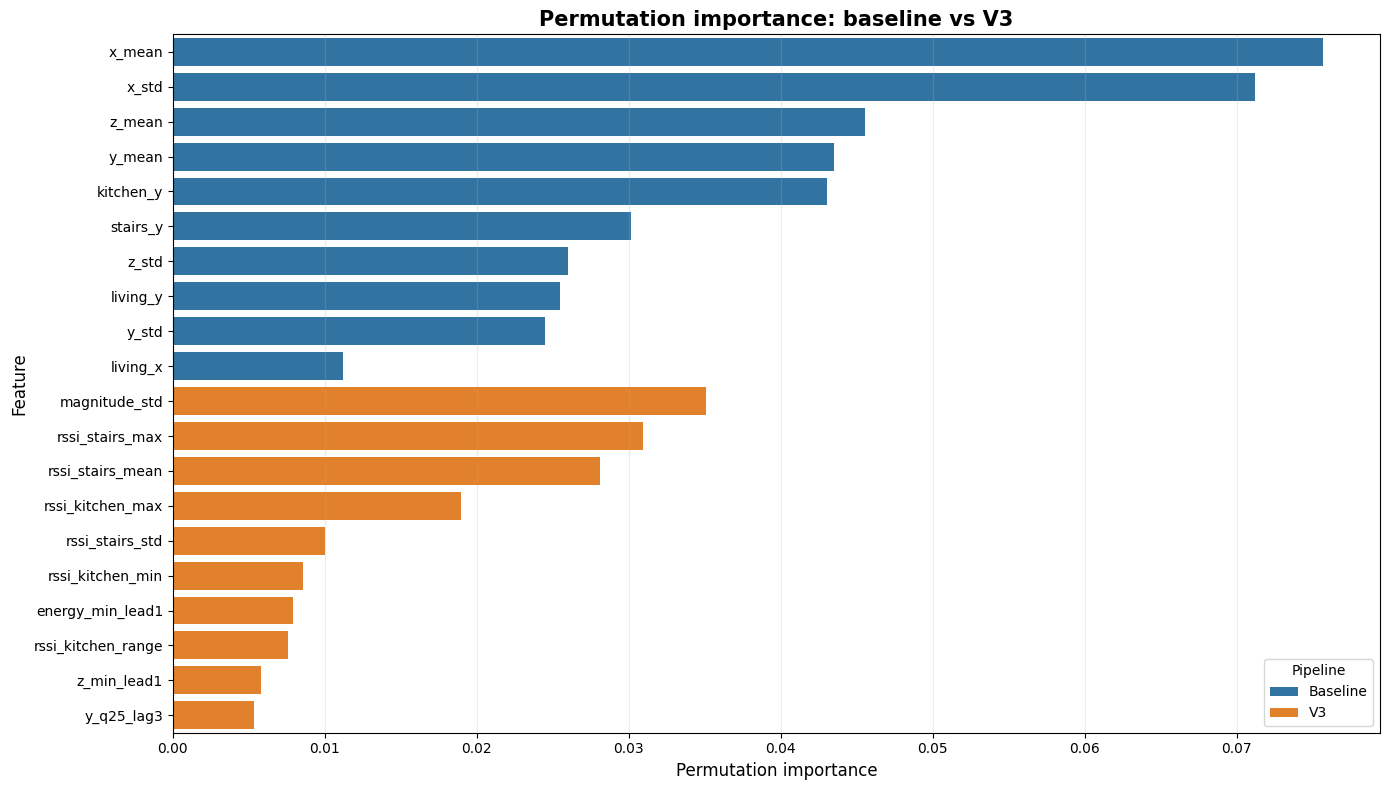

In [ ]:
# ======================================================
# FIGUR 5.22:
# SAMMENLIGNING AV PERMUTATION IMPORTANCE
# BASELINE VS V3
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------
# BASELINE
# importances_gb = pandas Series
# ------------------------------------------------------

baseline_perm = (
    importances_gb
    .head(10)
    .reset_index()
)

baseline_perm.columns = [
    "Feature",
    "Importance"
]

baseline_perm["Pipeline"] = "Baseline"

# ------------------------------------------------------
# V3
# importance_df = dataframe
# ------------------------------------------------------

v3_perm = (
    importance_df[
        ["Feature", "Importance_Mean"]
    ]
    .copy()
    .head(10)
)

v3_perm.columns = [
    "Feature",
    "Importance"
]

v3_perm["Pipeline"] = "V3"

# ------------------------------------------------------
# Kombiner
# ------------------------------------------------------

perm_compare = pd.concat(
    [
        baseline_perm,
        v3_perm
    ],
    ignore_index=True
)

display(
    perm_compare.style
    .format({"Importance": "{:.4f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Importance"]
    )
)

# ------------------------------------------------------
# Plot
# ------------------------------------------------------

plt.figure(figsize=(14, 8))

sns.barplot(
    data=perm_compare,
    x="Importance",
    y="Feature",
    hue="Pipeline"
)

plt.title(
    "Permutation importance: baseline vs V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Permutation importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.legend(
    title="Pipeline",
    loc="lower right"
)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

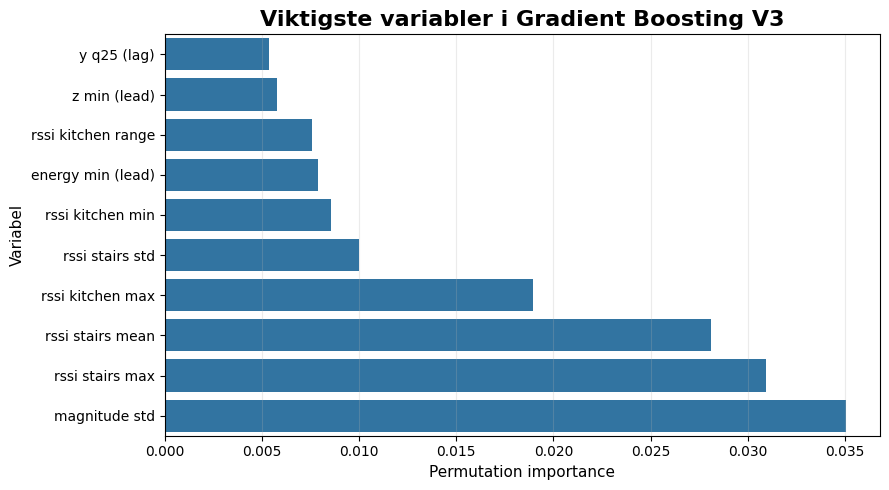

In [ ]:
# ======================================================
# Posterfigur: Top 10 permutation importance
# Gradient Boosting V3
# ======================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Bruker eksisterende importance_df fra V3 permutation importance-blokken
# Forventede kolonner: "Feature" og "Importance_Mean"

top10_perm_gb_v3 = (
    importance_df[["Feature", "Importance_Mean"]]
    .sort_values("Importance_Mean", ascending=False)
    .head(10)
    .copy()
)

# Valgfritt: penere navn til plakat
top10_perm_gb_v3["Feature_label"] = (
    top10_perm_gb_v3["Feature"]
    .str.replace("_", " ", regex=False)
    .str.replace("lead1", "(lead)", regex=False)
    .str.replace("lag3", "(lag)", regex=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top10_perm_gb_v3,
    x="Importance_Mean",
    y="Feature_label",
    orient="h"
)

plt.title("Viktigste variabler i Gradient Boosting V3", fontsize=16, weight="bold")
plt.xlabel("Permutation importance")
plt.ylabel("Variabel")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

# Lagre høyoppløselig versjon til plakat
plt.savefig("top10_permutation_importance_gb_v3.png", dpi=300, bbox_inches="tight")

plt.show()

###Feature Importance

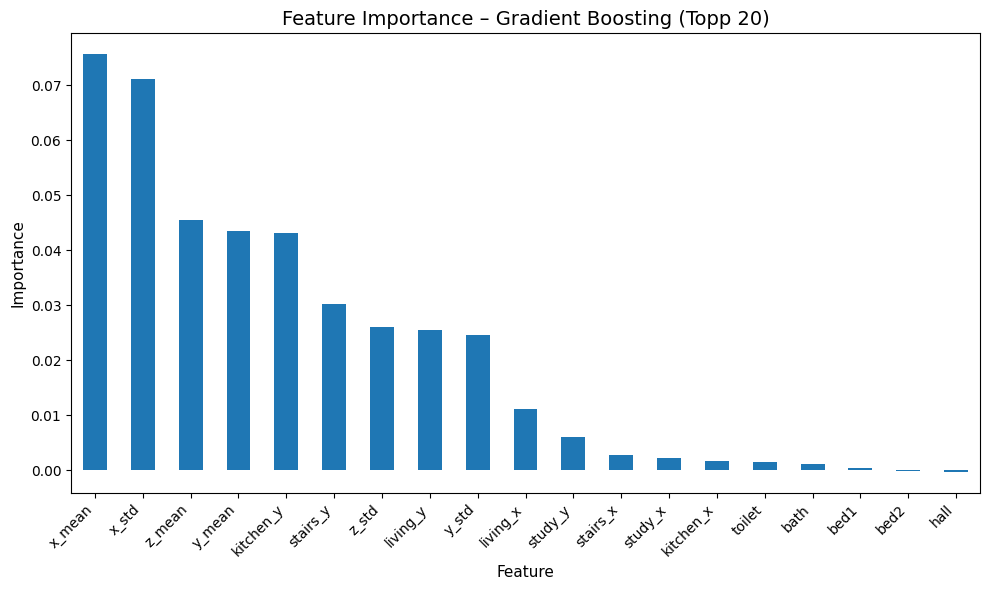


Topp 10 viktigste features – Gradient Boosting:
x_mean       0.075641
x_std        0.071199
z_mean       0.045571
y_mean       0.043502
kitchen_y    0.043058
stairs_y     0.030122
z_std        0.025985
living_y     0.025462
y_std        0.024512
living_x     0.011184
dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
importances_gb.head(20).plot(kind="bar")
plt.title("Feature Importance – Gradient Boosting (Topp 20)")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nTopp 10 viktigste features – Gradient Boosting:")
print(importances_gb.head(10))

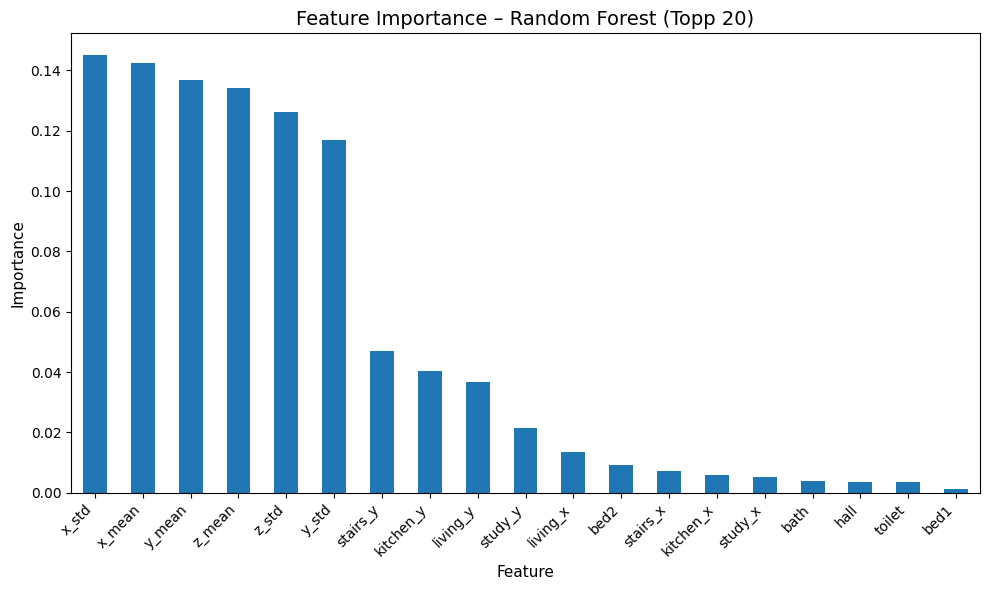


Topp 10 viktigste features:
x_std        0.145013
x_mean       0.142471
y_mean       0.136752
z_mean       0.134129
z_std        0.126090
y_std        0.116751
stairs_y     0.046870
kitchen_y    0.040421
living_y     0.036645
study_y      0.021415
dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
importances.head(20).plot(kind="bar")
plt.title("Feature Importance – Random Forest (Topp 20)")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nTopp 10 viktigste features:")
print(importances.head(10))

##Robusthet

,Pipeline,Model,Seed,Macro_F1
0,Baseline,Dummy,0,0.028
1,Baseline,Dummy,1,0.028
2,Baseline,Dummy,2,0.028
3,Baseline,Random Forest,0,0.252
4,Baseline,Random Forest,1,0.252
5,Baseline,Random Forest,2,0.254
6,Baseline,Linear SVM,0,0.133
7,Baseline,Linear SVM,1,0.133
8,Baseline,Linear SVM,2,0.133


Laster cachede V3 random seed-resultater


,Pipeline,Model,Seed,Macro_F1
0,V3,Random Forest,0,0.415
1,V3,Random Forest,1,0.416
2,V3,Random Forest,2,0.415
3,V3,Gradient Boosting,0,0.444
4,V3,Gradient Boosting,1,0.448
5,V3,Gradient Boosting,2,0.446
6,V3,Logistic Regression,0,0.386
7,V3,Logistic Regression,1,0.386
8,V3,Logistic Regression,2,0.386
9,V3,Linear SVM,0,0.376


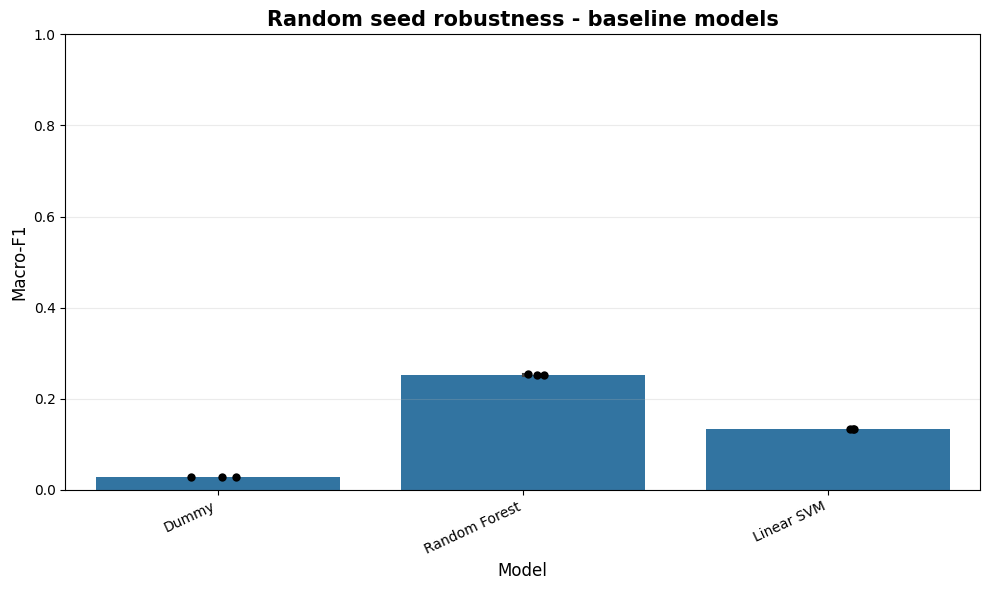

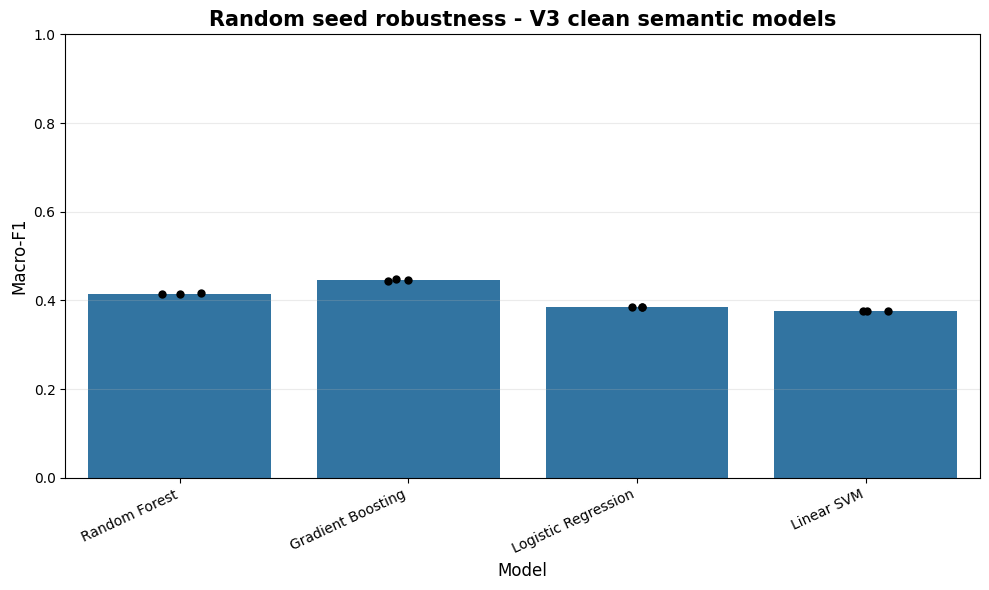

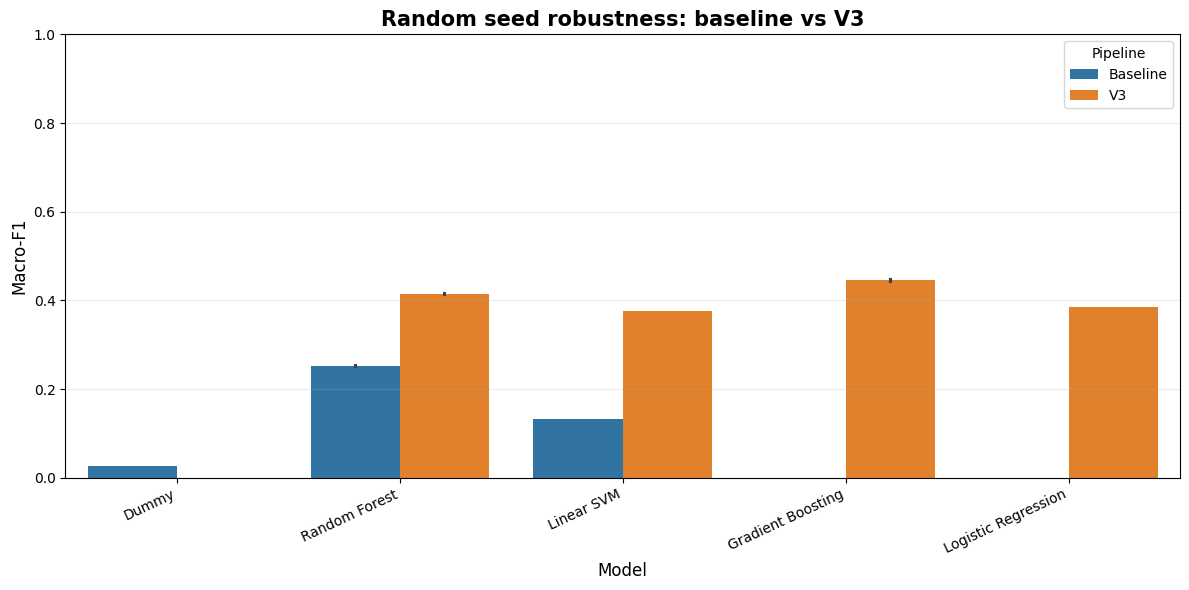

In [ ]:
# ======================================================
# RANDOM SEED ROBUSTNESS:
# BASELINE + V3 CLEAN SEMANTIC
# ======================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline

# ------------------------------------------------------
# Cache
# ------------------------------------------------------

v3_seed_path = os.path.join(
    RESULT_V3_DIR,
    "random_seed_robustness_v3_clean.pkl"
)

SEEDS = [0, 1, 2]

# ------------------------------------------------------
# 1. Baseline-resultater fra eksisterende robustness-dict
# ------------------------------------------------------

baseline_rows = []

for model_name, scores in robustness.items():

    for i, score in enumerate(scores):

        baseline_rows.append({
            "Pipeline": "Baseline",
            "Model": model_name,
            "Seed": i,
            "Macro_F1": score
        })

baseline_df = pd.DataFrame(baseline_rows)

display(
    baseline_df.style
    .format({"Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

# ------------------------------------------------------
# 2. V3 random seed-resultater
# ------------------------------------------------------

v3_seed_models = {
    "Random Forest": v3_models["Random Forest v3"],
    "Gradient Boosting": v3_models["Gradient Boosting v3"],
    "Logistic Regression": v3_models["Logistic Regression v3"],
    "Linear SVM": v3_models["Linear SVM v3"]
}


def set_random_state_for_model(model, seed):
    model_temp = clone(model)
    params = model_temp.get_params()

    updates = {}

    for param_name in params:
        if param_name == "random_state" or param_name.endswith("__random_state"):
            updates[param_name] = seed

    if updates:
        model_temp.set_params(**updates)

    return model_temp


def fit_v3_with_optional_weights(model, X, y, confidence):
    class_weights = compute_sample_weight(
        class_weight="balanced",
        y=y
    )

    sample_weights = class_weights * (confidence.values ** 2)

    if isinstance(model, Pipeline):
        last_step_name = model.steps[-1][0]

        try:
            model.fit(
                X,
                y,
                **{f"{last_step_name}__sample_weight": sample_weights}
            )
        except (TypeError, ValueError):
            model.fit(X, y)

    else:
        try:
            model.fit(
                X,
                y,
                sample_weight=sample_weights
            )
        except (TypeError, ValueError):
            model.fit(X, y)

    return model


if os.path.exists(v3_seed_path):

    print("Laster cachede V3 random seed-resultater")
    v3_df = joblib.load(v3_seed_path)

else:

    print("Kjører V3 random seed-eksperiment")

    v3_rows = []

    for model_name, model in v3_seed_models.items():

        print(f"\n{model_name}")

        for seed in SEEDS:

            print(f"Seed {seed}")

            model_temp = set_random_state_for_model(model, seed)

            model_temp = fit_v3_with_optional_weights(
                model_temp,
                X_train_v3_sub,
                y_train_v3_clean_sub,
                conf_train_v3_sub
            )

            preds = model_temp.predict(X_test_v3_clean)

            score = f1_score(
                y_test_v3_clean,
                preds,
                average="macro",
                zero_division=0
            )

            v3_rows.append({
                "Pipeline": "V3",
                "Model": model_name,
                "Seed": seed,
                "Macro_F1": score
            })

    v3_df = pd.DataFrame(v3_rows)

    joblib.dump(v3_df, v3_seed_path)

display(
    v3_df.style
    .format({"Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

# ------------------------------------------------------
# 3. Graf 1: Baseline
# ------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=baseline_df,
    x="Model",
    y="Macro_F1",
    errorbar="sd"
)

sns.stripplot(
    data=baseline_df,
    x="Model",
    y="Macro_F1",
    color="black",
    size=6,
    jitter=True
)

plt.title(
    "Random seed robustness - baseline models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Macro-F1", fontsize=12)
plt.xlabel("Model", fontsize=12)

plt.xticks(rotation=25, ha="right")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------
# 4. Graf 2: V3
# ------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=v3_df,
    x="Model",
    y="Macro_F1",
    errorbar="sd"
)

sns.stripplot(
    data=v3_df,
    x="Model",
    y="Macro_F1",
    color="black",
    size=6,
    jitter=True
)

plt.title(
    "Random seed robustness - V3 clean semantic models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Macro-F1", fontsize=12)
plt.xlabel("Model", fontsize=12)

plt.xticks(rotation=25, ha="right")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------
# 5. Graf 3: Baseline vs V3
# ------------------------------------------------------

seed_comparison_df = pd.concat(
    [
        baseline_df,
        v3_df
    ],
    ignore_index=True
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=seed_comparison_df,
    x="Model",
    y="Macro_F1",
    hue="Pipeline",
    errorbar="sd"
)

plt.title(
    "Random seed robustness: baseline vs V3",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Macro-F1", fontsize=12)
plt.xlabel("Model", fontsize=12)

plt.xticks(rotation=25, ha="right")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Baseline random seed summary


,Model,mean,std,min,max
0,Dummy,0.028,0.000,0.028,0.028
1,Linear SVM,0.133,0.000,0.133,0.133
2,Random Forest,0.253,0.001,0.252,0.254


V3 random seed summary


,Model,mean,std,min,max
0,Gradient Boosting,0.446,0.002,0.444,0.448
1,Linear SVM,0.376,0.000,0.376,0.376
2,Logistic Regression,0.386,0.000,0.386,0.386
3,Random Forest,0.415,0.000,0.415,0.416


Baseline vs V3 random seed summary


,Pipeline,Model,mean,std,min,max
0,Baseline,Dummy,0.028,0.000,0.028,0.028
1,Baseline,Linear SVM,0.133,0.000,0.133,0.133
2,Baseline,Random Forest,0.253,0.001,0.252,0.254
3,V3,Gradient Boosting,0.446,0.002,0.444,0.448
4,V3,Linear SVM,0.376,0.000,0.376,0.376
5,V3,Logistic Regression,0.386,0.000,0.386,0.386
6,V3,Random Forest,0.415,0.000,0.415,0.416


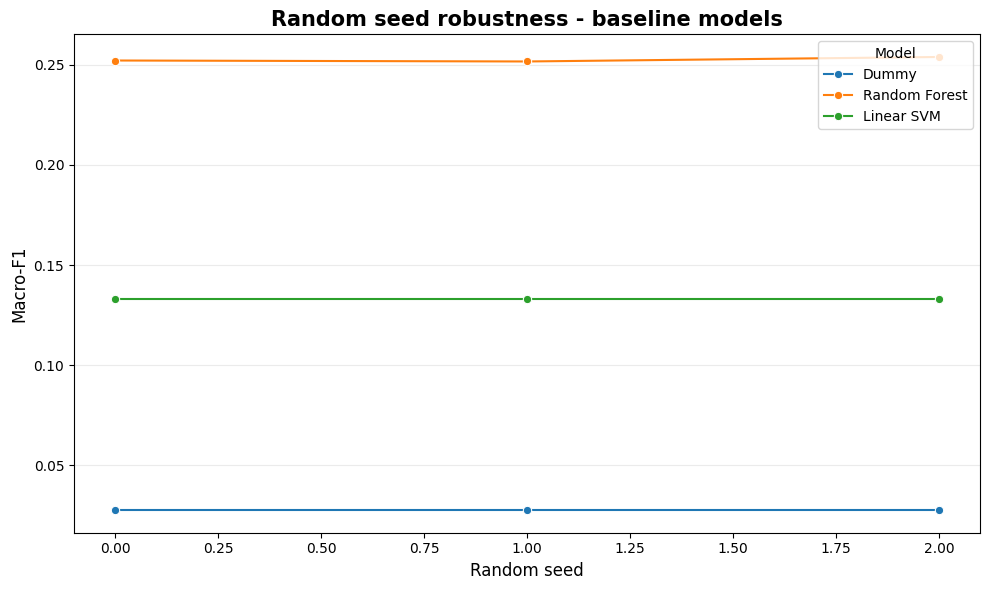

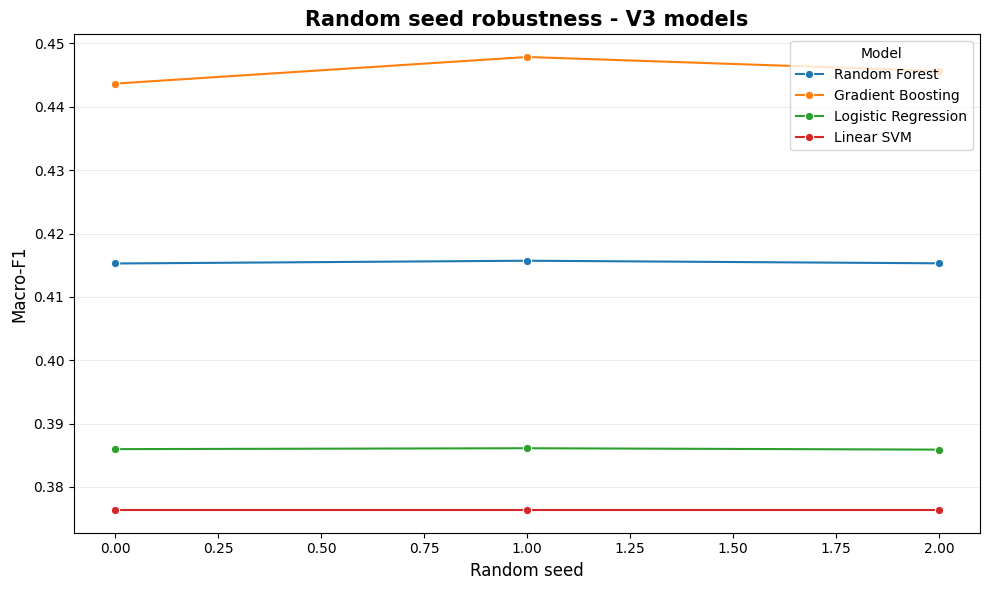

/tmp/ipykernel_6492/1269585874.py:175: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


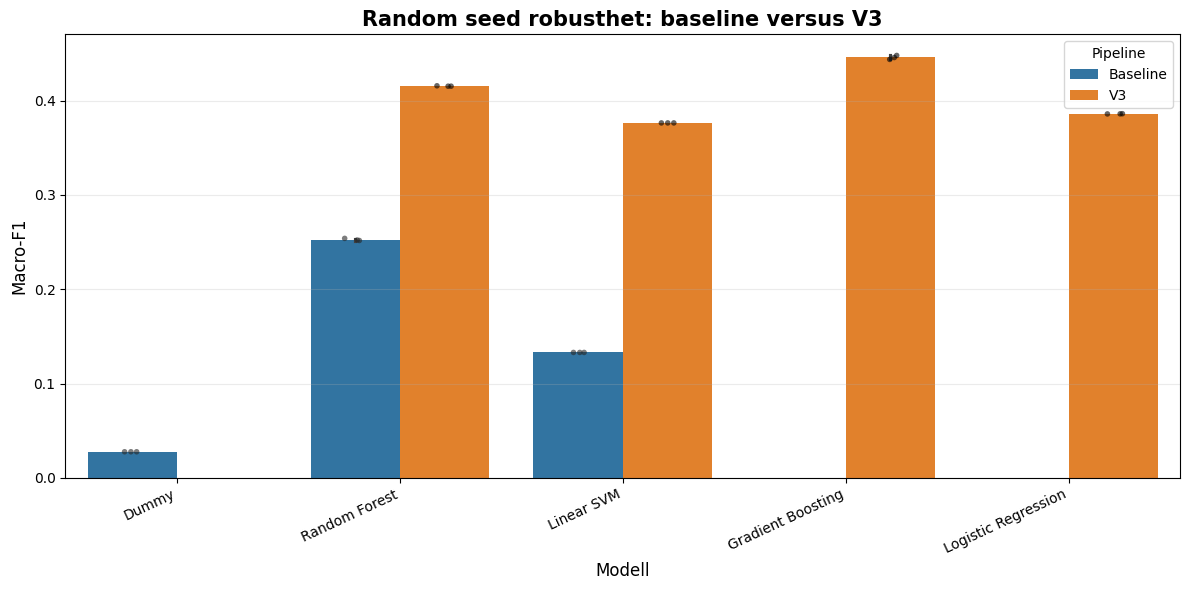

In [ ]:
# ======================================================
# RANDOM SEED ROBUSTNESS PLOTS
# Baseline, V3 og comparison
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------
# 1. Lag baseline dataframe fra eksisterende robustness
# ------------------------------------------------------

baseline_rows = []

for model_name, scores in robustness.items():
    for seed_idx, score in enumerate(scores):
        baseline_rows.append({
            "Pipeline": "Baseline",
            "Model": model_name,
            "Seed": seed_idx,
            "Macro_F1": score
        })

baseline_df = pd.DataFrame(baseline_rows)

# ------------------------------------------------------
# 2. Bruk eksisterende V3 dataframe
# Forventet navn fra tidligere kode: v3_df
# ------------------------------------------------------

v3_plot_df = v3_df.copy()

v3_plot_df["Pipeline"] = "V3"

# Sørger for at modellnavn matcher baseline-navn best mulig
v3_plot_df["Model"] = (
    v3_plot_df["Model"]
    .str.replace(" V3", "", regex=False)
    .str.replace(" v3", "", regex=False)
)

# ------------------------------------------------------
# 3. Lag oppsummeringstabeller
# ------------------------------------------------------

baseline_summary = (
    baseline_df
    .groupby("Model")["Macro_F1"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

v3_summary = (
    v3_plot_df
    .groupby("Model")["Macro_F1"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

comparison_df = pd.concat(
    [baseline_df, v3_plot_df],
    ignore_index=True
)

comparison_summary = (
    comparison_df
    .groupby(["Pipeline", "Model"])["Macro_F1"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

print("Baseline random seed summary")
display(
    baseline_summary.style
    .format({"mean": "{:.3f}", "std": "{:.3f}", "min": "{:.3f}", "max": "{:.3f}"})
    .background_gradient(cmap="viridis", subset=["mean"])
)

print("V3 random seed summary")
display(
    v3_summary.style
    .format({"mean": "{:.3f}", "std": "{:.3f}", "min": "{:.3f}", "max": "{:.3f}"})
    .background_gradient(cmap="viridis", subset=["mean"])
)

print("Baseline vs V3 random seed summary")
display(
    comparison_summary.style
    .format({"mean": "{:.3f}", "std": "{:.3f}", "min": "{:.3f}", "max": "{:.3f}"})
    .background_gradient(cmap="viridis", subset=["mean"])
)







# ------------------------------------------------------
# 4. Hjelpefunksjon for zoomet y-akse
# ------------------------------------------------------

def set_zoomed_ylim(df, margin=0.01):
    ymin = df["Macro_F1"].min() - margin
    ymax = df["Macro_F1"].max() + margin

    ymin = max(0, ymin)
    ymax = min(1, ymax)

    plt.ylim(ymin, ymax)


# ======================================================
# GRAF 1: BASELINE RANDOM SEED ROBUSTNESS
# ======================================================

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=baseline_df,
    x="Seed",
    y="Macro_F1",
    hue="Model",
    marker="o"
)

plt.title("Random seed robustness - baseline models", fontsize=15, fontweight="bold")
plt.xlabel("Random seed", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ======================================================
# GRAF 2: V3 RANDOM SEED ROBUSTNESS
# ======================================================

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=v3_plot_df,
    x="Seed",
    y="Macro_F1",
    hue="Model",
    marker="o"
)

plt.title("Random seed robustness - V3 models", fontsize=15, fontweight="bold")
plt.xlabel("Random seed", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ======================================================
# GRAF 3: BASELINE VS V3 RANDOM SEED COMPARISON
# Mean Macro-F1 med standardavvik
# ======================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Macro_F1",
    hue="Pipeline",
    errorbar="sd"
)

sns.stripplot(
    data=comparison_df,
    x="Model",
    y="Macro_F1",
    hue="Pipeline",
    dodge=True,
    color="black",
    size=4,
    alpha=0.6,
    legend=False
)

plt.title("Random seed robusthet: baseline versus V3", fontsize=15, fontweight="bold")
plt.xlabel("Modell", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

,Pipeline,Experiment,Model,Macro_F1
0,Baseline,ACC_only,Dummy,0.028
1,Baseline,ACC_only,Logistic Regression,0.082
2,Baseline,ACC_only,Random Forest,0.173
3,Baseline,ACC_only,Gradient Boosting,0.151
4,Baseline,ACC_only,Linear SVM,0.060
5,Baseline,PIR_only,Dummy,0.028
6,Baseline,PIR_only,Logistic Regression,0.047
7,Baseline,PIR_only,Random Forest,0.038
8,Baseline,PIR_only,Gradient Boosting,0.046
9,Baseline,PIR_only,Linear SVM,0.047


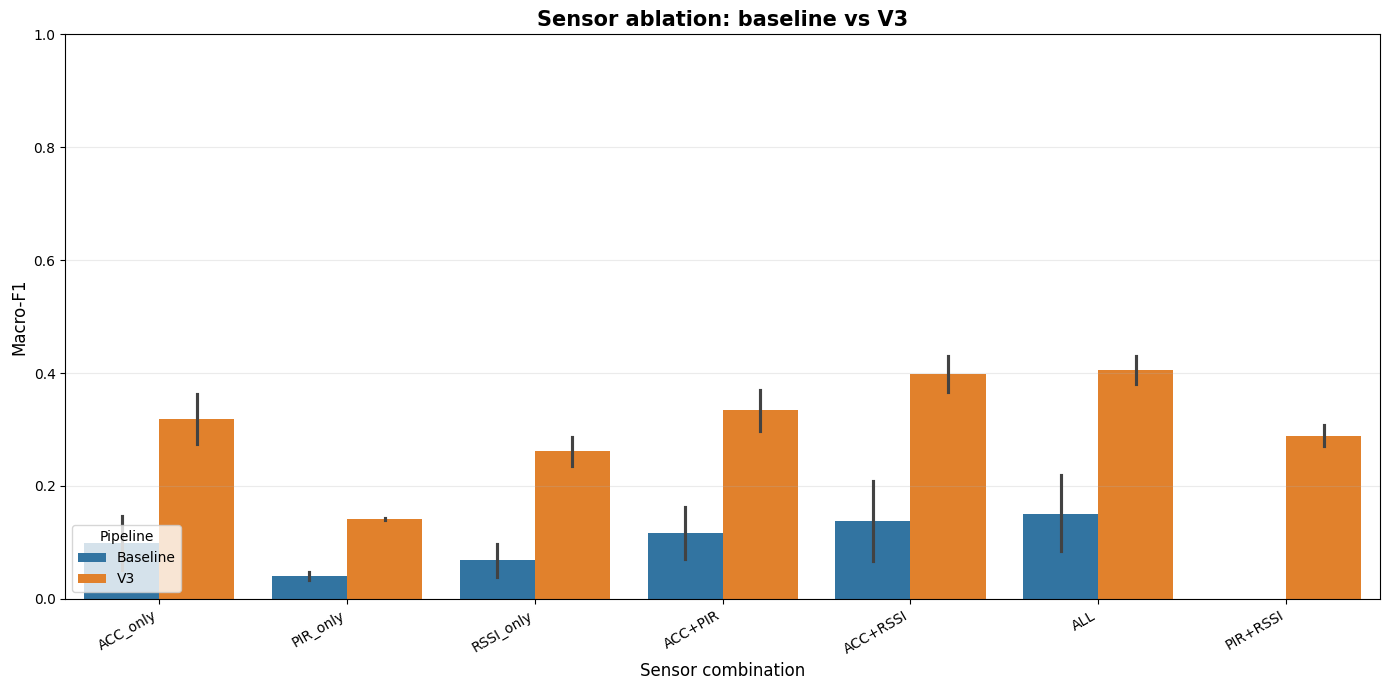

In [ ]:
# ======================================================
# BASELINE VS V3 SENSORABLASJON
# ======================================================

baseline_ablation_compare = ablation_results.copy()
baseline_ablation_compare["Pipeline"] = "Baseline"

v3_ablation_compare = ablation_results_v3.copy()
v3_ablation_compare["Pipeline"] = "V3"

# Gjør modellnavn sammenlignbare
v3_ablation_compare["Model"] = (
    v3_ablation_compare["Model"]
    .str.replace(" V3", "", regex=False)
    .str.replace(" v3", "", regex=False)
)

sensor_ablation_comparison = pd.concat(
    [
        baseline_ablation_compare[["Pipeline", "Experiment", "Model", "Macro_F1"]],
        v3_ablation_compare[["Pipeline", "Experiment", "Model", "Macro_F1"]]
    ],
    ignore_index=True
)

display(
    sensor_ablation_comparison.style
    .format({"Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=sensor_ablation_comparison,
    x="Experiment",
    y="Macro_F1",
    hue="Pipeline"
)

plt.title(
    "Sensor ablation: baseline vs V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Sensor combination", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.xticks(rotation=30, ha="right")

plt.ylim(0, 1)

plt.legend(
    title="Pipeline",
    loc="lower left"
)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

,Pipeline,Model,Noise,Macro_F1
0,Baseline,Dummy,0.00,0.028
1,Baseline,Logistic Regression,0.00,0.134
2,Baseline,Random Forest,0.00,0.252
3,Baseline,Gradient Boosting,0.00,0.200
4,Baseline,Linear SVM,0.00,0.118
5,Baseline,1D-CNN,0.00,0.239
6,Baseline,Dummy,0.05,0.028
7,Baseline,Logistic Regression,0.05,0.133
8,Baseline,Random Forest,0.05,0.214
9,Baseline,Gradient Boosting,0.05,0.155


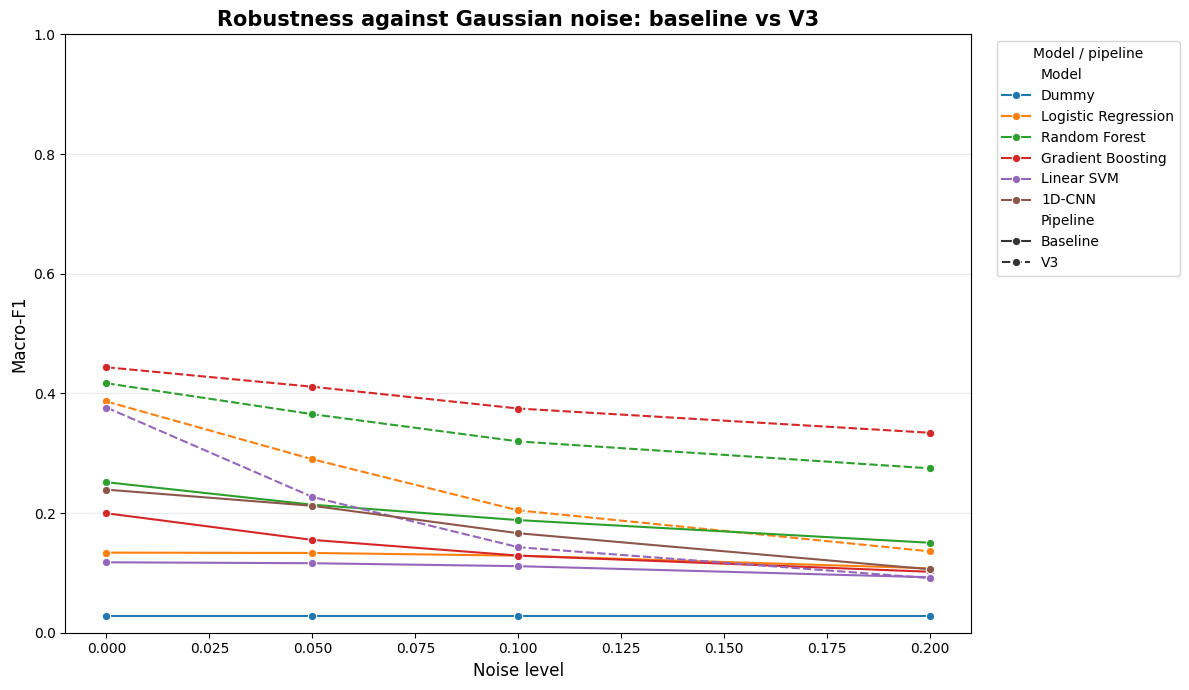

In [ ]:
# ======================================================
# GAUSSIAN NOISE ROBUSTNESS:
# BASELINE VS V3 COMPARISON
# Bruker faktiske variabler fra notebooken:
# noise_results og noise_results_v3
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

baseline_noise = noise_results.copy()
baseline_noise["Pipeline"] = "Baseline"

v3_noise = noise_results_v3.copy()
v3_noise["Pipeline"] = "V3"

# Gjør modellnavn sammenlignbare
v3_noise["Model"] = (
    v3_noise["Model"]
    .str.replace(" V3", "", regex=False)
    .str.replace(" v3", "", regex=False)
)

noise_comparison = pd.concat(
    [
        baseline_noise[["Pipeline", "Model", "Noise", "Macro_F1"]],
        v3_noise[["Pipeline", "Model", "Noise", "Macro_F1"]]
    ],
    ignore_index=True
)

display(
    noise_comparison.style
    .format({"Noise": "{:.2f}", "Macro_F1": "{:.3f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Macro_F1"]
    )
)

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=noise_comparison,
    x="Noise",
    y="Macro_F1",
    hue="Model",
    style="Pipeline",
    marker="o"
)

plt.title(
    "Robustness against Gaussian noise: baseline vs V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Noise level", fontsize=12)
plt.ylabel("Macro-F1", fontsize=12)

plt.ylim(0, 1)

plt.legend(
    title="Model / pipeline",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#Misc


,Feature,Mean_abs_SHAP
15,kitchen_y,0.0166
0,x_mean,0.0154
2,y_mean,0.0125
1,x_std,0.0119
4,z_mean,0.0108
5,z_std,0.0105
3,y_std,0.0093
18,stairs_y,0.0075
16,living_y,0.0064
11,living_x,0.0029


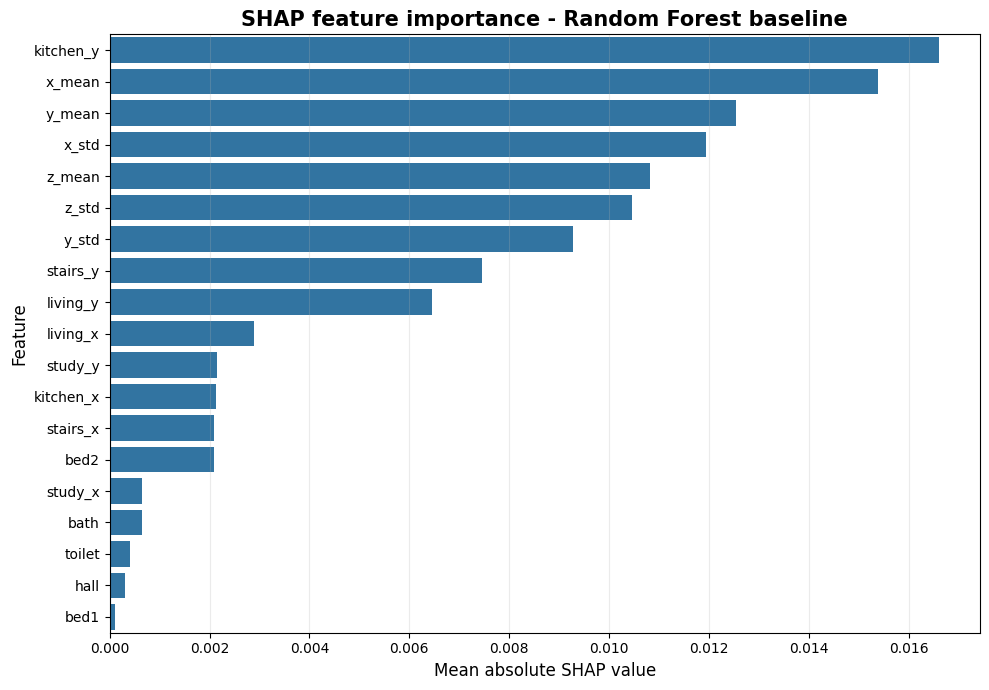

,Feature,Importance_Mean
0,x_mean,0.0756
1,x_std,0.0712
2,z_mean,0.0456
3,y_mean,0.0435
4,kitchen_y,0.0431
5,stairs_y,0.0301
6,z_std,0.0260
7,living_y,0.0255
8,y_std,0.0245
9,living_x,0.0112


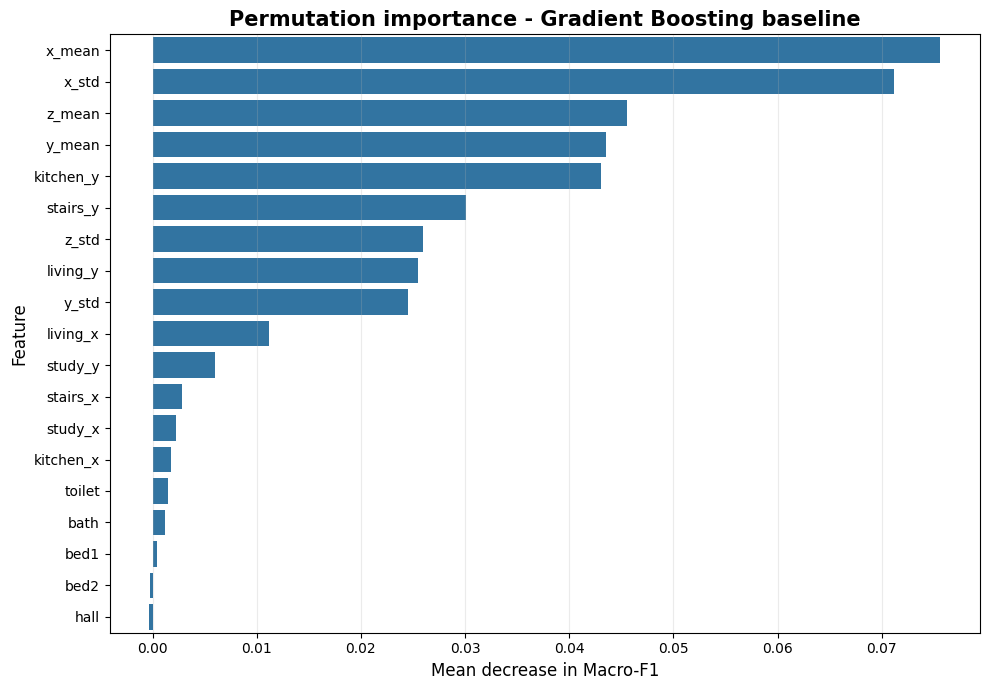

In [ ]:
# ============================================================
# FIGUR 5.7 OG 5.8:
# PLOT EXISTING SHAP + PERMUTATION IMPORTANCE BASELINE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# FIGUR 5.7: SHAP SUMMARY FOR BASELINE RANDOM FOREST
# Bruker eksisterende variabler fra celle 186:
# x_shap_sample, rf_shap_values, rf_classes
# ============================================================

# rf_shap_values har shape: (samples, features, classes)
# Vi lager global feature importance ved å ta mean absolute SHAP
# over både samples og klasser.

if len(rf_shap_values.shape) == 3:
    global_shap_importance = np.abs(rf_shap_values).mean(axis=(0, 2))
else:
    global_shap_importance = np.abs(rf_shap_values).mean(axis=0)

shap_baseline_df = pd.DataFrame({
    "Feature": x_shap_sample.columns,
    "Mean_abs_SHAP": global_shap_importance
}).sort_values("Mean_abs_SHAP", ascending=False)

display(
    shap_baseline_df.head(20).style
    .format({"Mean_abs_SHAP": "{:.4f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Mean_abs_SHAP"]
    )
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=shap_baseline_df.head(20),
    x="Mean_abs_SHAP",
    y="Feature"
)

plt.title(
    "SHAP feature importance - Random Forest baseline",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Mean absolute SHAP value",
    fontsize=12
)

plt.ylabel(
    "Feature",
    fontsize=12
)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# ============================================================
# FIGUR 5.8: PERMUTATION IMPORTANCE FOR BASELINE GRADIENT BOOSTING
# Bruker eksisterende variabel fra celle 190:
# importances_gb
# ============================================================

baseline_perm_df = (
    importances_gb
    .reset_index()
)

baseline_perm_df.columns = ["Feature", "Importance_Mean"]

display(
    baseline_perm_df.head(20).style
    .format({"Importance_Mean": "{:.4f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Importance_Mean"]
    )
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=baseline_perm_df.head(20),
    x="Importance_Mean",
    y="Feature"
)

plt.title(
    "Permutation importance - Gradient Boosting baseline",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean decrease in Macro-F1", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

,Experiment,Model,Accuracy,Macro_F1,Weighted_F1
0,Clean semantic classes,Gradient Boosting v3,0.688778,0.443636,0.661128
1,Clean semantic classes,Random Forest v3,0.678888,0.416901,0.641197
2,Clean semantic classes,Logistic Regression v3,0.526262,0.386412,0.548308
3,Clean semantic classes,Linear SVM v3,0.509558,0.376335,0.531186
5,Raw 1D-CNN V2,Raw 1D-CNN V2,0.342419,0.278572,0.365003
4,Clean semantic classes,Dummy v3,0.190858,0.032054,0.061177


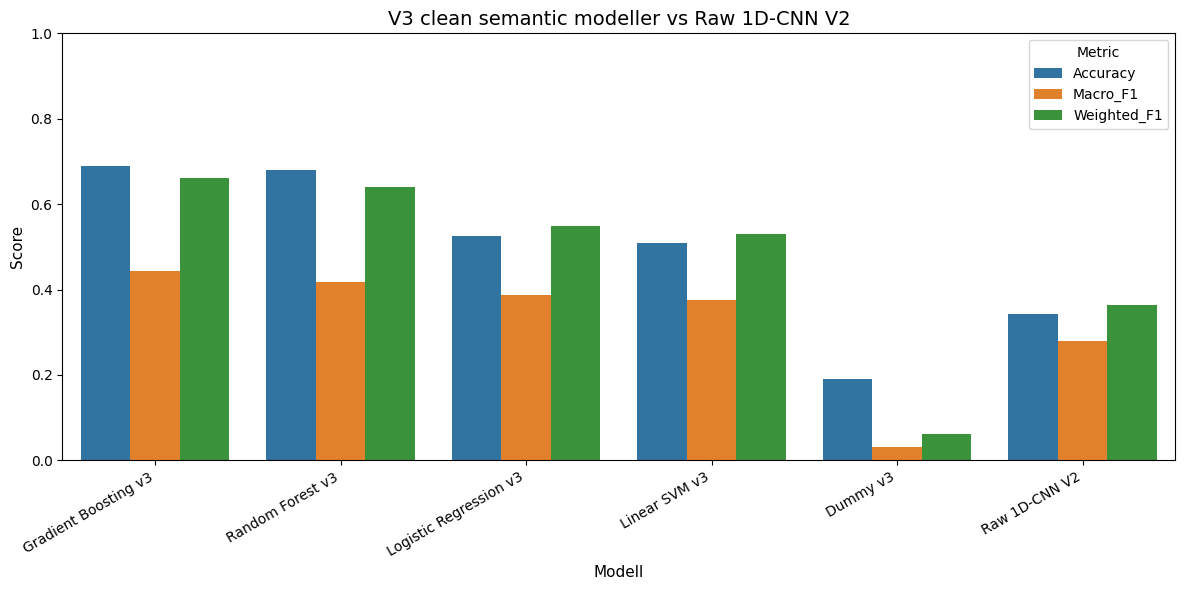

In [ ]:
# ======================================================
# V3 CLEAN SEMANTIC VS RAW 1D-CNN V2
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

v3_clean_results = performance_v3_all[
    performance_v3_all["Experiment"] == "Clean semantic classes"
].copy()

raw_cnn_result = pd.DataFrame([{
    "Experiment": "Raw 1D-CNN V2",
    "Model": "Raw 1D-CNN V2",
    "Accuracy": raw_cnn_accuracy,
    "Macro_F1": raw_cnn_macro_f1,
    "Weighted_F1": raw_cnn_weighted_f1
}])

cnn_v3_comparison = pd.concat(
    [
        v3_clean_results[["Experiment", "Model", "Accuracy", "Macro_F1", "Weighted_F1"]],
        raw_cnn_result
    ],
    ignore_index=True
)

display(cnn_v3_comparison.sort_values("Macro_F1", ascending=False))

cnn_v3_long = cnn_v3_comparison.melt(
    id_vars=["Experiment", "Model"],
    value_vars=["Accuracy", "Macro_F1", "Weighted_F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=cnn_v3_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("V3 clean semantic modeller vs Raw 1D-CNN V2")
plt.xlabel("Modell")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

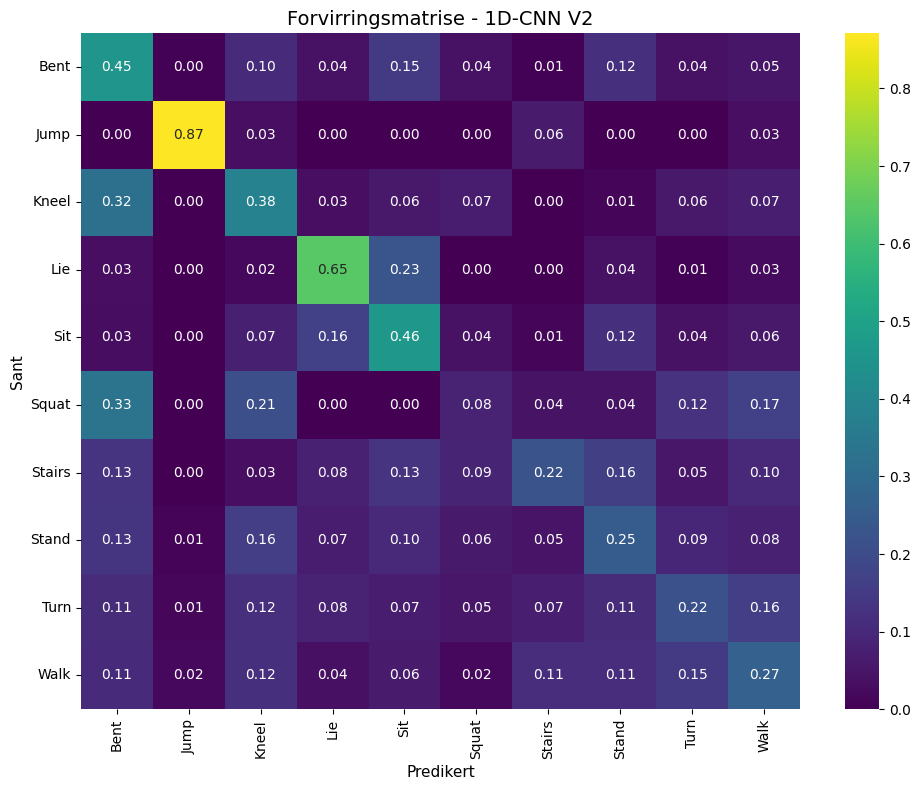

In [ ]:
# ======================================================
# CONFUSION MATRIX - RAW 1D-CNN V2
# Bruker y_test_raw_cnn og y_pred_raw_labels
# ======================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

raw_cnn_classes = sorted(pd.Series(y_test_raw_cnn).unique())

cm_raw_cnn = confusion_matrix(
    y_test_raw_cnn,
    y_pred_raw_labels,
    labels=raw_cnn_classes
)

cm_raw_cnn_norm = cm_raw_cnn.astype("float") / cm_raw_cnn.sum(axis=1, keepdims=True)
cm_raw_cnn_norm = np.nan_to_num(cm_raw_cnn_norm)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_raw_cnn_norm,
    cmap="viridis",
    xticklabels=raw_cnn_classes,
    yticklabels=raw_cnn_classes,
    annot=True,
    fmt=".2f"
)

plt.title("Forvirringsmatrise - 1D-CNN V2")
plt.xlabel("Predikert")
plt.ylabel("Sant")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

,Original_samples,After_filtering,Removed,Percent_kept,Percent_removed
label,,,,,
Stairs,676,272,404,40.2%,59.8%
Squat,110,46,64,41.8%,58.2%
Bent,956,743,213,77.7%,22.3%
Turn,342,285,57,83.3%,16.7%
Walk,1881,1581,300,84.1%,15.9%
Kneel,352,310,42,88.1%,11.9%
Lie,1687,1588,99,94.1%,5.9%
Stand,6886,6616,270,96.1%,3.9%
Sit,3355,3228,127,96.2%,3.8%


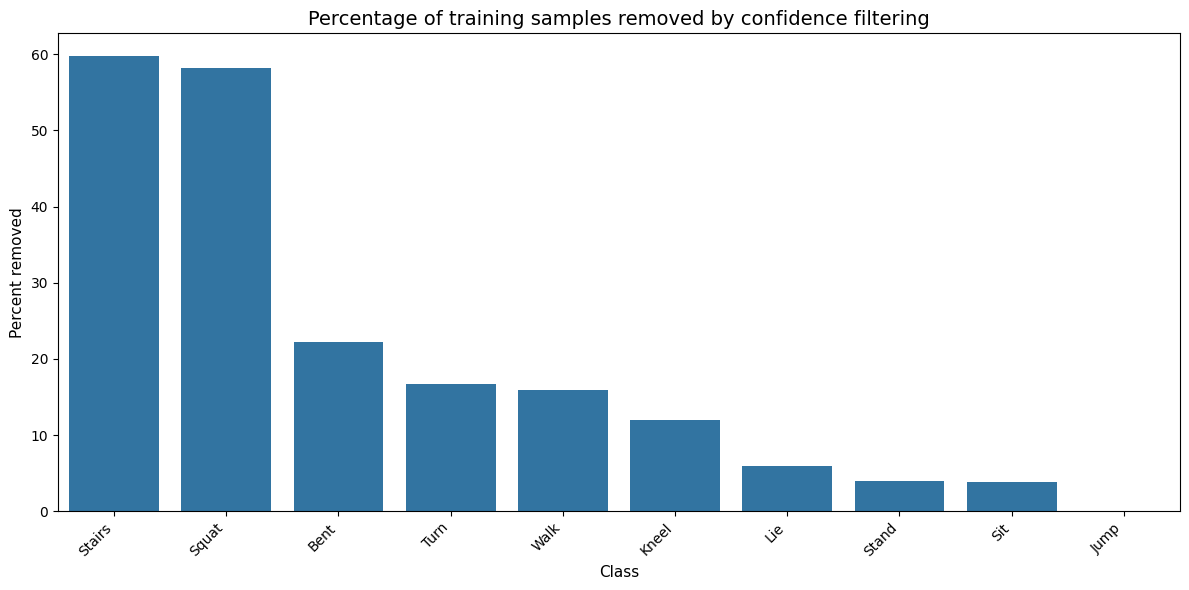

In [ ]:
# ======================================================
# CONFIDENCE FILTERING PER CLASS
# ======================================================

import pandas as pd

CONF_THRESHOLD = 0.6

y_train_v3_clean_full = map_activity_to_clean_class(y_train_v3)

valid_mask = y_train_v3_clean_full.notna()

before_y = y_train_v3_clean_full[valid_mask]
before_conf = conf_train_v3[valid_mask]

after_mask = before_conf > CONF_THRESHOLD

full_counts = before_y.value_counts().sort_index()
filtered_counts = before_y[after_mask].value_counts().sort_index()

filter_compare = pd.DataFrame({
    "Original_samples": full_counts,
    "After_filtering": filtered_counts
}).fillna(0)

filter_compare["Removed"] = (
    filter_compare["Original_samples"] -
    filter_compare["After_filtering"]
)

filter_compare["Percent_kept"] = (
    100 * filter_compare["After_filtering"] /
    filter_compare["Original_samples"]
)

filter_compare["Percent_removed"] = 100 - filter_compare["Percent_kept"]

filter_compare = filter_compare.sort_values("Percent_removed", ascending=False)

display(
    filter_compare.style
    .format({
        "Percent_kept": "{:.1f}%",
        "Percent_removed": "{:.1f}%"
    })
    .background_gradient(cmap="Reds", subset=["Percent_removed"])
)

plot_df = filter_compare.reset_index()

plt.figure(figsize=(12,6))

sns.barplot(
    data=plot_df,
    x="label",
    y="Percent_removed"
)

plt.title("Percentage of training samples removed by confidence filtering")
plt.xlabel("Class")
plt.ylabel("Percent removed")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ======================================================
# SAMPLE WEIGHT ANALYSIS
# ======================================================

import pandas as pd
import numpy as np

from sklearn.utils.class_weight import compute_sample_weight

# ------------------------------------------
# 1. Class weights
# ------------------------------------------

class_weights_only = compute_sample_weight(
    class_weight="balanced",
    y=y_train_v3_clean_sub
)

# ------------------------------------------
# 2. Confidence multipliers
# ------------------------------------------

confidence_multiplier = (
    conf_train_v3_sub.values ** 2
)

# ------------------------------------------
# 3. Final weights
# ------------------------------------------

final_weights = (
    class_weights_only
    * confidence_multiplier
)

# ------------------------------------------
# 4. Build dataframe
# ------------------------------------------

weights_df = pd.DataFrame({
    "Class": y_train_v3_clean_sub.values,
    "Confidence": conf_train_v3_sub.values,
    "Class_weight_only": class_weights_only,
    "Confidence_multiplier": confidence_multiplier,
    "Final_weight": final_weights
})

# ------------------------------------------
# 5. Aggregate per class
# ------------------------------------------

weights_summary = (
    weights_df
    .groupby("Class")
    .agg({
        "Confidence": ["mean", "std"],
        "Class_weight_only": ["mean"],
        "Confidence_multiplier": ["mean"],
        "Final_weight": ["mean", "std", "max"]
    })
)

display(
    weights_summary.style
    .format("{:.3f}")
    .background_gradient(cmap="viridis")
)

print(weights_summary)

       Confidence           Class_weight_only Confidence_multiplier  \
             mean       std              mean                  mean   
Class                                                                 
Bent     0.835783  0.098031          1.980215              0.708130   
Jump     0.819318  0.080131         33.438636              0.677557   
Kneel    0.834452  0.077830          4.746129              0.702348   
Lie      0.857729  0.079706          0.926511              0.742048   
Sit      0.922581  0.098570          0.455793              0.860868   
Squat    0.765870  0.065949         31.984783              0.590811   
Stairs   0.841642  0.104741          5.409191              0.719292   
Stand    0.885803  0.106723          0.222385              0.796034   
Turn     0.740912  0.081001          5.162456              0.555489   
Walk     0.788079  0.095273          0.930614              0.630140   

       Final_weight                       
               mean       std    

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.3s
[Parallel(n_jobs=12)]: Done 800 out of 800 | elapsed:    0.4s finished


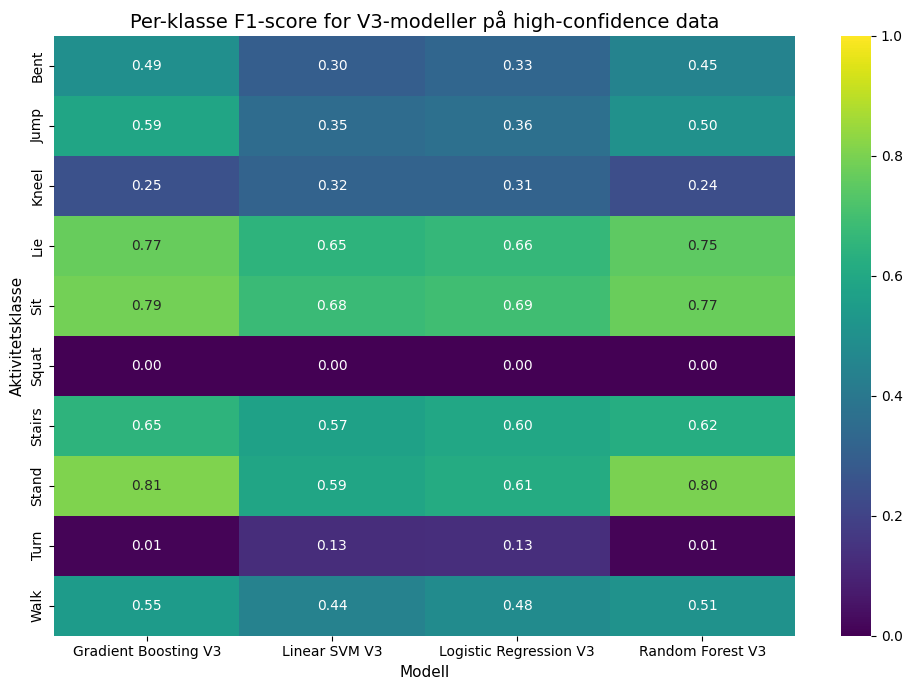

In [ ]:
# ======================================================
# FIGUR 5.11 - Per-klasse F1-score for V3 på high-confidence testdata
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report

selected_v3_models = {
    "Random Forest V3": trained_models_v3_clean["Random Forest v3"],
    "Gradient Boosting V3": trained_models_v3_clean["Gradient Boosting v3"],
    "Logistic Regression V3": trained_models_v3_clean["Logistic Regression v3"],
    "Linear SVM V3": trained_models_v3_clean["Linear SVM v3"]
}

classes = sorted(pd.Series(y_test_v3_clean).dropna().unique())

per_class_rows = []

for model_label, model in selected_v3_models.items():

    preds = model.predict(X_test_v3_highconf)

    report = classification_report(
        y_test_v3_clean_highconf,
        preds,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    for cls in classes:
        per_class_rows.append({
            "Class": cls,
            "Model": model_label,
            "F1": report[cls]["f1-score"]
        })

v3_per_class_highconf_df = pd.DataFrame(per_class_rows)

v3_per_class_highconf_pivot = v3_per_class_highconf_df.pivot(
    index="Class",
    columns="Model",
    values="F1"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    v3_per_class_highconf_pivot,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.title("Per-klasse F1-score for V3-modeller på high-confidence data")
plt.xlabel("Modell")
plt.ylabel("Aktivitetsklasse")

plt.tight_layout()
plt.show()

Laster cached V3 high-confidence sensorablasjon


,Experiment,Model,Macro_F1
0,ACC_only,Logistic Regression,0.317
1,ACC_only,Random Forest,0.383
2,ACC_only,Gradient Boosting,0.413
3,ACC_only,Linear SVM,0.270
4,PIR_only,Logistic Regression,0.150
5,PIR_only,Random Forest,0.150
6,PIR_only,Gradient Boosting,0.145
7,PIR_only,Linear SVM,0.147
8,RSSI_only,Logistic Regression,0.270
9,RSSI_only,Random Forest,0.324


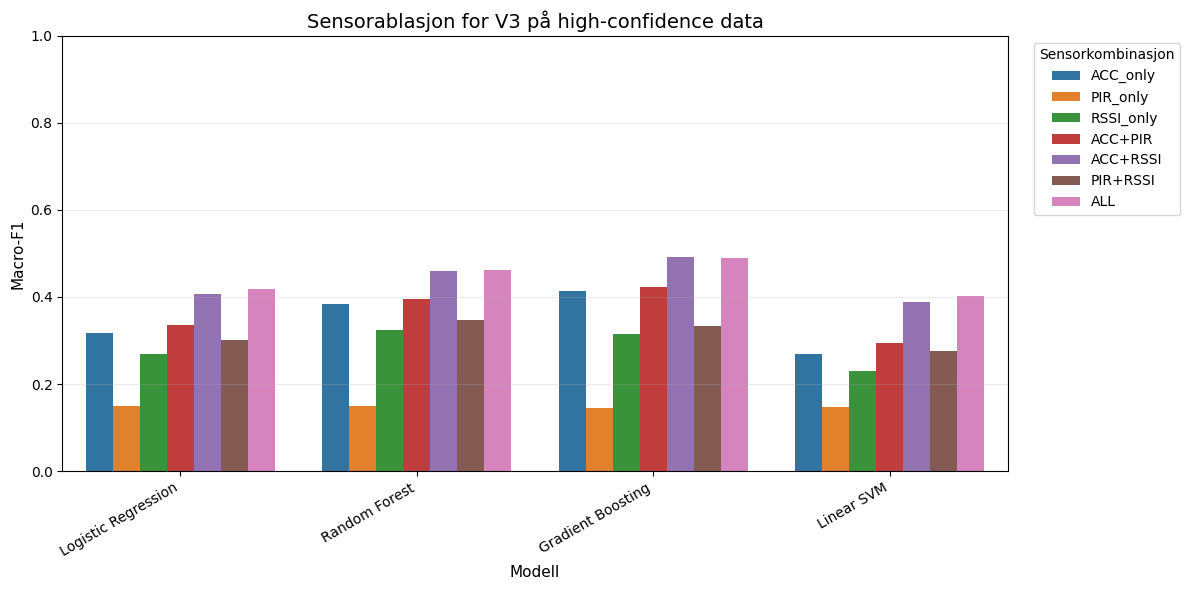

In [ ]:
# ======================================================
# FIGUR 5.15 - Sensorablasjon for V3 på high-confidence testdata
# ======================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline

# ------------------------------------------------------
# Cache
# ------------------------------------------------------

v3_ablation_highconf_path = os.path.join(
    RESULT_V3_DIR,
    "sensor_ablation_v3_highconfidence.pkl"
)

# ------------------------------------------------------
# Hjelpefunksjon for sample weights
# ------------------------------------------------------

def fit_model_with_weights(model, X, y, confidence):
    class_weights = compute_sample_weight(
        class_weight="balanced",
        y=y
    )

    sample_weights = class_weights * (confidence.values ** 2)

    if isinstance(model, Pipeline):
        last_step = model.steps[-1][0]

        try:
            model.fit(
                X,
                y,
                **{f"{last_step}__sample_weight": sample_weights}
            )
        except (TypeError, ValueError):
            model.fit(X, y)

    else:
        try:
            model.fit(X, y, sample_weight=sample_weights)
        except (TypeError, ValueError):
            model.fit(X, y)

    return model

# ------------------------------------------------------
# Kjør eller last sensorablasjon
# ------------------------------------------------------

if os.path.exists(v3_ablation_highconf_path):

    print("Laster cached V3 high-confidence sensorablasjon")
    ablation_results_v3_highconf = joblib.load(v3_ablation_highconf_path)

else:

    print("Kjører V3 sensorablasjon på high-confidence testdata")

    ablation_rows = []

    selected_models = {
        "Logistic Regression": v3_models["Logistic Regression v3"],
        "Random Forest": v3_models["Random Forest v3"],
        "Gradient Boosting": v3_models["Gradient Boosting v3"],
        "Linear SVM": v3_models["Linear SVM v3"]
    }

    for experiment_name, features in v3_feature_sets.items():

        # Hopper over tomme feature-sett
        if len(features) == 0:
            continue

        print("Kjører:", experiment_name)

        Xtr = X_train_v3_sub[features]
        Xte = X_test_v3_highconf[features]

        for model_name, model in selected_models.items():

            model_temp = clone(model)

            model_temp = fit_model_with_weights(
                model_temp,
                Xtr,
                y_train_v3_clean_sub,
                conf_train_v3_sub
            )

            preds = model_temp.predict(Xte)

            score = f1_score(
                y_test_v3_clean_highconf,
                preds,
                average="macro",
                zero_division=0
            )

            ablation_rows.append({
                "Experiment": experiment_name,
                "Model": model_name,
                "Macro_F1": score
            })

    ablation_results_v3_highconf = pd.DataFrame(ablation_rows)

    joblib.dump(
        ablation_results_v3_highconf,
        v3_ablation_highconf_path
    )

display(
    ablation_results_v3_highconf.style
    .format({"Macro_F1": "{:.3f}"})
    .background_gradient(cmap="viridis", subset=["Macro_F1"])
)

# ------------------------------------------------------
# Plot
# ------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ablation_results_v3_highconf,
    x="Model",
    y="Macro_F1",
    hue="Experiment"
)

plt.title("Sensorablasjon for V3 på high-confidence data")
plt.xlabel("Modell")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sensorkombinasjon", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

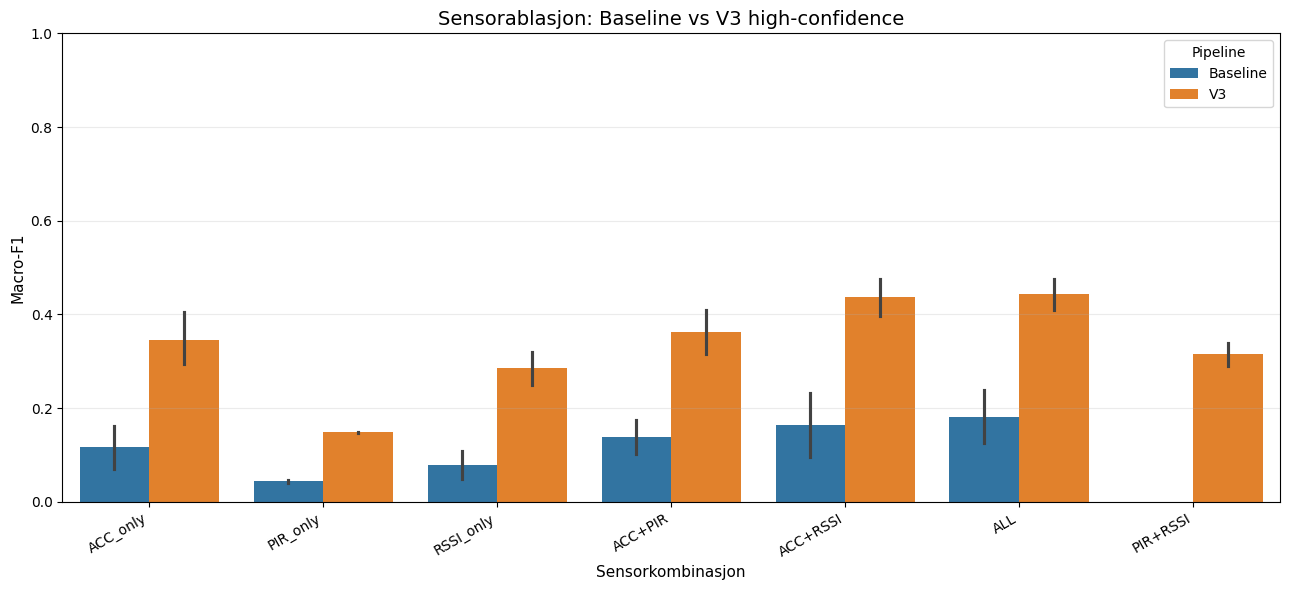

In [ ]:
# ======================================================
# FIGUR 5.22 - Sensorablasjon: Baseline fulltest vs V3 high-confidence
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------
# 1. Baseline sensorablasjon
# ------------------------------------------------------

baseline_ablation_compare = ablation_results.copy()

baseline_ablation_compare["Pipeline"] = "Baseline"
baseline_ablation_compare["Test setup"] = "Fulltest"

# Sikrer likt metrikknavn
baseline_ablation_compare = baseline_ablation_compare.rename(columns={
    "Macro-F1": "Macro_F1",
    "macro_f1": "Macro_F1"
})

# ------------------------------------------------------
# 2. V3 high-confidence sensorablasjon
# ------------------------------------------------------

v3_ablation_compare = ablation_results_v3_highconf.copy()

v3_ablation_compare["Pipeline"] = "V3"
v3_ablation_compare["Test setup"] = "High-confidence"

v3_ablation_compare = v3_ablation_compare.rename(columns={
    "Macro-F1": "Macro_F1",
    "macro_f1": "Macro_F1"
})

# ------------------------------------------------------
# 3. Slå sammen
# ------------------------------------------------------

fig_522_df = pd.concat(
    [
        baseline_ablation_compare[["Pipeline", "Test setup", "Experiment", "Model", "Macro_F1"]],
        v3_ablation_compare[["Pipeline", "Test setup", "Experiment", "Model", "Macro_F1"]]
    ],
    ignore_index=True
)

# Valgfritt: fjern Dummy hvis den finnes
fig_522_df = fig_522_df[
    ~fig_522_df["Model"].astype(str).str.contains("Dummy", case=False, na=False)
].copy()

# ------------------------------------------------------
# 4. Plot
# ------------------------------------------------------

plt.figure(figsize=(13, 6))

sns.barplot(
    data=fig_522_df,
    x="Experiment",
    y="Macro_F1",
    hue="Pipeline"
)

plt.title("Sensorablasjon: Baseline vs V3 high-confidence")
plt.xlabel("Sensorkombinasjon")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Pipeline")

plt.tight_layout()
plt.show()

,Pipeline,Test setup,Model,Accuracy,Macro_F1,Weighted_F1
6,V3,High-confidence,Gradient Boosting,0.730,0.489,0.712
7,V3,High-confidence,Random Forest,0.721,0.464,0.695
8,V3,High-confidence,Logistic Regression,0.553,0.418,0.580
9,V3,High-confidence,Linear SVM,0.534,0.401,0.559
11,1D-CNN V2,Sequence test,1D-CNN V2,0.342,0.279,0.365
0,Baseline,Fulltest,Random Forest,0.565,0.255,0.510
1,Baseline,Fulltest,1D-CNN,0.374,0.239,0.390
2,Baseline,Fulltest,Gradient Boosting,0.567,0.238,0.514
3,Baseline,Fulltest,Logistic Regression,0.183,0.144,0.176
4,Baseline,Fulltest,Linear SVM,0.223,0.133,0.222


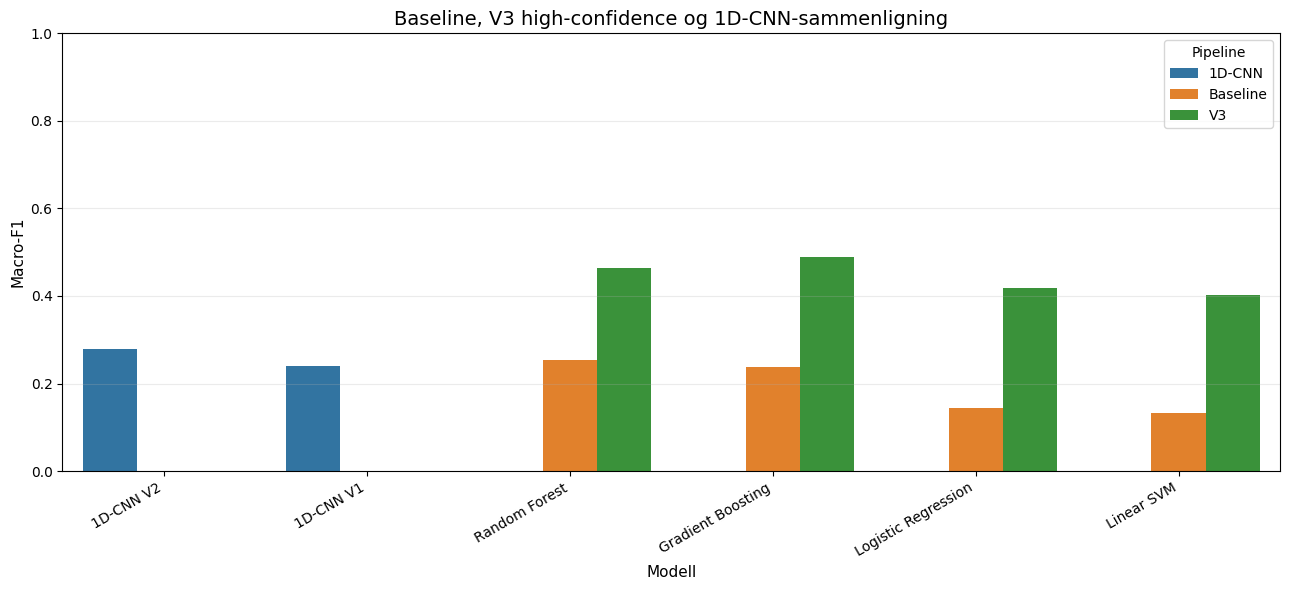

In [ ]:
# ======================================================
# FIGUR 5.18 - Baseline fulltest vs V3 high-confidence,
# inkludert 1D-CNN V1 og 1D-CNN V2
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------
# 1. Baseline-resultater fra eksisterende performance_df
# ------------------------------------------------------

baseline_compare = performance_df.copy()

baseline_compare["Pipeline"] = "Baseline"
baseline_compare["Test setup"] = "Fulltest"

baseline_compare["Model"] = (
    baseline_compare["Model"]
    .astype(str)
    .str.replace("Baseline ", "", regex=False)
)

# ------------------------------------------------------
# 2. V3 high-confidence-resultater
# ------------------------------------------------------

v3_highconf_compare = performance_v3_highconf.copy()

v3_highconf_compare["Pipeline"] = "V3"
v3_highconf_compare["Test setup"] = "High-confidence"

v3_highconf_compare["Model"] = (
    v3_highconf_compare["Model"]
    .astype(str)
    .str.replace(" v3", "", regex=False)
    .str.replace(" V3", "", regex=False)
)

# ------------------------------------------------------
# 3. 1D-CNN V2-resultat
# ------------------------------------------------------

cnn_v2_row = pd.DataFrame([{
    "Pipeline": "1D-CNN V2",
    "Test setup": "Sequence test",
    "Model": "1D-CNN V2",
    "Accuracy": raw_cnn_accuracy,
    "Macro_F1": raw_cnn_macro_f1,
    "Weighted_F1": raw_cnn_weighted_f1
}])

# ------------------------------------------------------
# 4. Slå sammen
# ------------------------------------------------------

fig_518_df = pd.concat(
    [
        baseline_compare[["Pipeline", "Test setup", "Model", "Accuracy", "Macro_F1", "Weighted_F1"]],
        v3_highconf_compare[["Pipeline", "Test setup", "Model", "Accuracy", "Macro_F1", "Weighted_F1"]],
        cnn_v2_row
    ],
    ignore_index=True
)

# Fjern Dummy fra hovedfiguren
fig_518_plot_df = fig_518_df[
    ~fig_518_df["Model"].str.contains("Dummy", case=False, na=False)
].copy()

# ------------------------------------------------------
# 5. Gjør 1D-CNN V1 og V2 tydelige i samme familie
# ------------------------------------------------------

fig_518_plot_df["Pipeline"] = fig_518_plot_df.apply(
    lambda row: "1D-CNN" if "1D-CNN" in row["Model"] else row["Pipeline"],
    axis=1
)

fig_518_plot_df["Model"] = fig_518_plot_df["Model"].replace({
    "1D-CNN": "1D-CNN V1"
})

# Sorter for penere figur
fig_518_plot_df = fig_518_plot_df.sort_values(
    ["Pipeline", "Macro_F1"],
    ascending=[True, False]
)

display(
    fig_518_df.sort_values("Macro_F1", ascending=False)
    .style
    .format({
        "Accuracy": "{:.3f}",
        "Macro_F1": "{:.3f}",
        "Weighted_F1": "{:.3f}"
    })
    .background_gradient(cmap="viridis", subset=["Macro_F1"])
)

# ------------------------------------------------------
# 6. Plot Macro-F1
# ------------------------------------------------------

plt.figure(figsize=(13, 6))

sns.barplot(
    data=fig_518_plot_df,
    x="Model",
    y="Macro_F1",
    hue="Pipeline"
)

plt.title("Baseline, V3 high-confidence og 1D-CNN-sammenligning")
plt.xlabel("Modell")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.legend(title="Pipeline")
plt.tight_layout()
plt.show()

,Feature,Importance,Pipeline
0,x_mean,0.0756,Baseline
1,x_std,0.0712,Baseline
2,z_mean,0.0456,Baseline
3,y_mean,0.0435,Baseline
4,kitchen_y,0.0431,Baseline
5,stairs_y,0.0301,Baseline
6,z_std,0.0260,Baseline
7,living_y,0.0255,Baseline
8,y_std,0.0245,Baseline
9,living_x,0.0112,Baseline


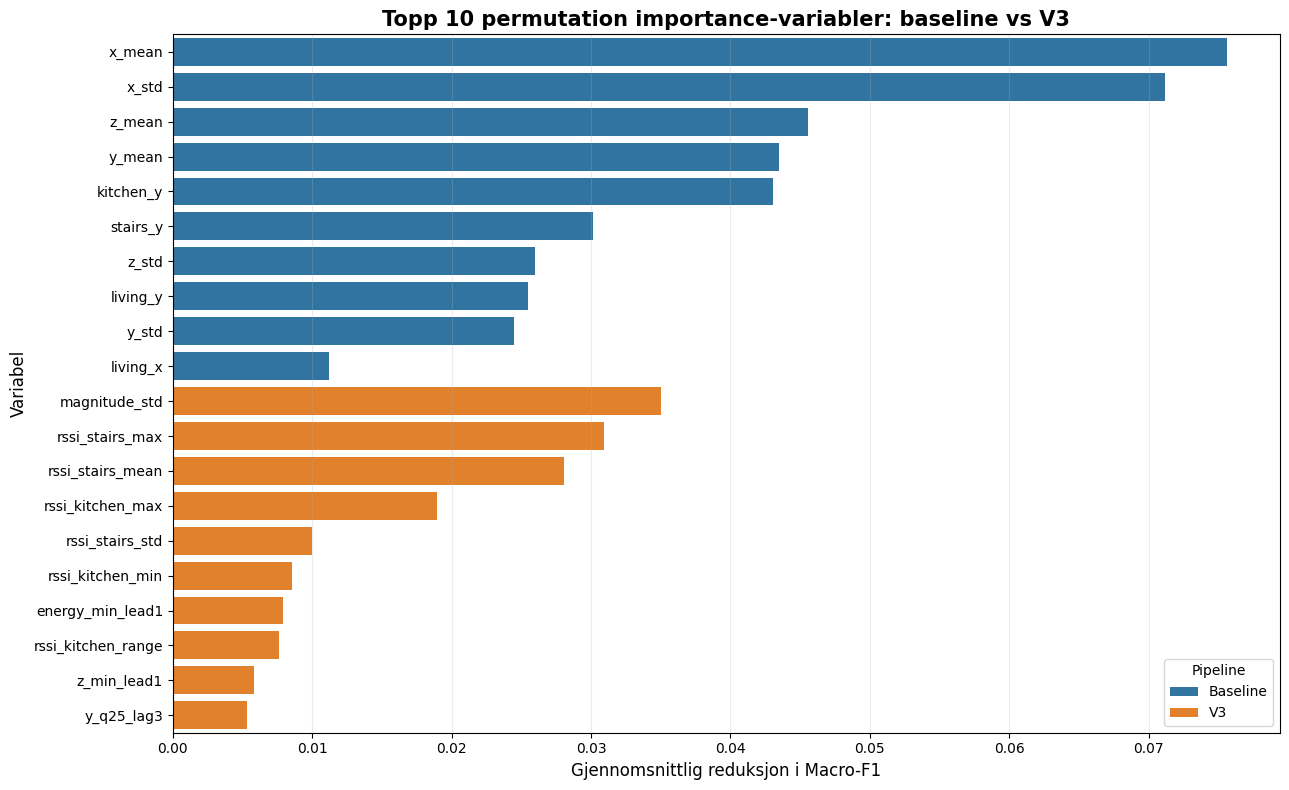

In [ ]:
# ======================================================
# FIGUR 5.25 - Top 10 permutation importance:
# baseline vs V3
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TOP_K = 10

# ------------------------------------------------------
# BASELINE
# importances_gb = pandas Series
# ------------------------------------------------------

baseline_imp = (
    importances_gb
    .sort_values(ascending=False)
    .head(TOP_K)
    .reset_index()
)

baseline_imp.columns = [
    "Feature",
    "Importance"
]

baseline_imp["Pipeline"] = "Baseline"

# ------------------------------------------------------
# V3
# importance_df = DataFrame
# ------------------------------------------------------

v3_imp = (
    importance_df[
        ["Feature", "Importance_Mean"]
    ]
    .copy()
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .head(TOP_K)
)

v3_imp.columns = [
    "Feature",
    "Importance"
]

v3_imp["Pipeline"] = "V3"

# ------------------------------------------------------
# Kombiner
# ------------------------------------------------------

comparison_df = pd.concat(
    [
        baseline_imp,
        v3_imp
    ],
    ignore_index=True
)

display(
    comparison_df.style
    .format({"Importance": "{:.4f}"})
    .background_gradient(
        cmap="viridis",
        subset=["Importance"]
    )
)

# ------------------------------------------------------
# Plot
# ------------------------------------------------------

plt.figure(figsize=(13, 8))

sns.barplot(
    data=comparison_df,
    y="Feature",
    x="Importance",
    hue="Pipeline"
)

plt.title(
    "Topp 10 permutation importance-variabler: baseline vs V3",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Gjennomsnittlig reduksjon i Macro-F1",
    fontsize=12
)

plt.ylabel(
    "Variabel",
    fontsize=12
)

plt.grid(axis="x", alpha=0.25)

plt.legend(
    title="Pipeline",
    loc="lower right"
)

plt.tight_layout()
plt.show()

,Model,Accuracy,Macro_F1,Weighted_F1
0,1D-CNN V1,0.374,0.239,0.390
1,1D-CNN V2,0.342,0.279,0.365


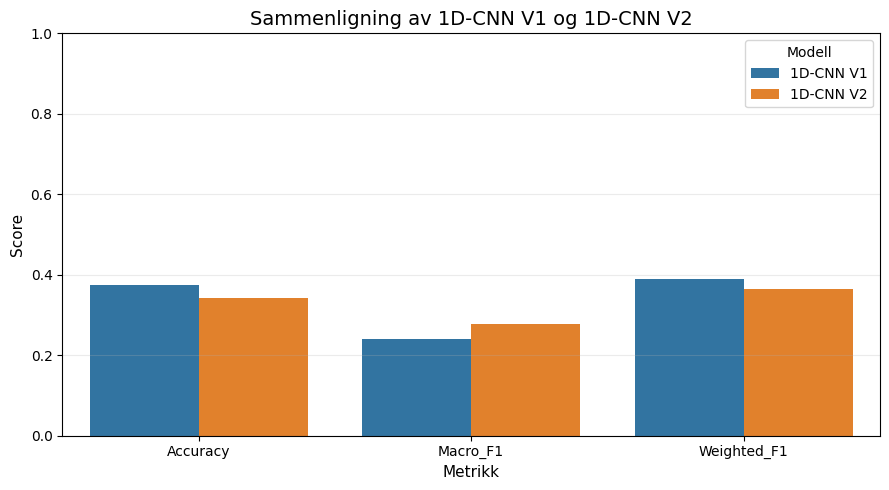

In [ ]:
# ======================================================
# Sammenligning av 1D-CNN V1 og 1D-CNN V2
# ======================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------
# 1. Hent 1D-CNN V1 fra baseline-resultatene
# ------------------------------------------------------

cnn_v1_row = performance_df[
    performance_df["Model"].astype(str).str.fullmatch("1D-CNN", case=False, na=False)
].copy()

# Sikkerhetssjekk
if cnn_v1_row.empty:
    print("Fant ikke 1D-CNN i performance_df. Modellnavnene er:")
    print(performance_df["Model"].unique())
else:
    # --------------------------------------------------
    # 2. Lag sammenligningstabell
    # --------------------------------------------------

    cnn_compare_df = pd.DataFrame({
        "Model": ["1D-CNN V1", "1D-CNN V2"],
        "Accuracy": [
            cnn_v1_row["Accuracy"].iloc[0],
            raw_cnn_accuracy
        ],
        "Macro_F1": [
            cnn_v1_row["Macro_F1"].iloc[0],
            raw_cnn_macro_f1
        ],
        "Weighted_F1": [
            cnn_v1_row["Weighted_F1"].iloc[0],
            raw_cnn_weighted_f1
        ]
    })

    display(
        cnn_compare_df.style
        .format({
            "Accuracy": "{:.3f}",
            "Macro_F1": "{:.3f}",
            "Weighted_F1": "{:.3f}"
        })
        .background_gradient(cmap="viridis", subset=["Macro_F1"])
    )

    # --------------------------------------------------
    # 3. Gjør data long format for plotting
    # --------------------------------------------------

    cnn_plot_df = cnn_compare_df.melt(
        id_vars="Model",
        value_vars=["Accuracy", "Macro_F1", "Weighted_F1"],
        var_name="Metric",
        value_name="Score"
    )

    # --------------------------------------------------
    # 4. Plot
    # --------------------------------------------------

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=cnn_plot_df,
        x="Metric",
        y="Score",
        hue="Model"
    )

    plt.title("Sammenligning av 1D-CNN V1 og 1D-CNN V2")
    plt.xlabel("Metrikk")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.25)
    plt.legend(title="Modell")

    plt.tight_layout()
    plt.show()